# Clearview Properties — Residential Price Analysis

Technical notebook for the Clearview Properties brief: the whole analysis end to end, with the evidence behind every decision.

## Executive summary
- **Q1 – Listing range.** A model trained on past sales gives every home a reference price, an 80% listing range and a 50% negotiation band. On sales it had never seen, the ranges contained the stated share of sales in every price tier. → [Section 3](#s3)
- **Q2 – What drives price.** The building's size and age matter most, then its overall quality and condition. Owner-modifiable features add comparatively little that is unique. Location matters, but far less than raw neighborhood prices suggest. → [Section 4](#s4)
- **Q3 – Profitable improvements.** None of the improvements with a published 2008 cost (kitchen, siding, deck, basement) pays for itself at resale: past sales value them well below their cost, and below what Realtors estimated at the time. For the other improvements, the break-even cost tells owners the most worth spending. → [Section 5](#s5)
- **Q4 – Market segments.** The market splits into two halves, older and smaller vs newer and larger homes, located in largely different neighborhoods. Quality is worth more in the newer half, and one price model serves both. → [Section 6](#s6)

## Contents
- [0. Setup and reproducibility](#s0)
  - [Raw data, loaded as delivered](#s0-raw)
  - [0.1 Toolbox](#s0-1)
- [1. Data quality audit and cleaning](#s1)
  - [1.1 Data dictionary: variable meanings and valid codes](#s1-1)
  - [1.2 Audit of the raw file](#s1-2)
  - [1.3 Repair pipeline](#s1-3)
  - [1.4 Verification: re-run the audit on the cleaned data](#s1-4)
  - [1.5 Analysis sample: which sales the price models learn from](#s1-5)
  - [1.6 Lot Frontage: dropped (team decision)](#s1-6)
  - [1.7 Remaining missing values: investigation](#s1-7)
  - [1.8 Key results and data quality log](#s1-8)
- [2. Exploratory data analysis and feature engineering](#s2)
  - [2.1 New variables computed from the data](#s2-1)
  - [2.2 Train/test split (before any analysis)](#s2-2)
  - [2.3 Target: model the price or its logarithm?](#s2-3)
  - [2.4 Time: did prices move between 2006 and 2010?](#s2-4)
  - [2.5 Location and age](#s2-5)
  - [2.6 Shared modeling tools](#s2-6)
  - [2.7 Variable selection](#s2-7)
  - [2.8 Lot Frontage: cross-validation check (Section 1.6)](#s2-8)
  - [2.9 Key results](#s2-9)
- [3. Q1 — Price range model](#s3)
  - [3.1 Candidate models and their tuning](#s3-1)
  - [3.2 A single model or a blend?](#s3-2)
  - [3.3 Final check on the test set, and over time](#s3-3)
  - [3.4 Listing range and negotiation band](#s3-4)
  - [3.5 Valuation card for brokers](#s3-5)
  - [3.6 Key results](#s3-6)
- [4. Q2 — Price drivers](#s4)
  - [4.1 Groups of characteristics](#s4-1)
  - [4.2 How much does each group matter?](#s4-2)
  - [4.3 Which individual characteristics matter most?](#s4-3)
  - [4.4 How much is location worth?](#s4-4)
  - [4.5 Key results](#s4-5)
- [5. Q3 — Improvement return on investment](#s5)
  - [5.1 Key results](#s5-1)
- [6. Q4 — Market segmentation](#s6)
  - [6.1 How many segments?](#s6-1)
  - [6.2 Who is in each segment?](#s6-2)
  - [6.3 Do the segments behave differently?](#s6-3)
  - [6.4 Does one price model serve both segments?](#s6-4)
  - [6.5 Key results](#s6-5)
- [7. Conclusions, limitations and next steps](#s7)
  - [Answers to the client's questions](#s7-answers)
  - [Limitations](#s7-limitations)
  - [Next steps](#s7-next)

## Use of AI tools
As the brief requires, we declare the AI tools used. Claude (Anthropic, through Claude Code) helped set up the reproducible environment and write the data quality audit and cleaning (Sections 0–1). Google Antigravity (Gemini) helped extend the audit and write a first version of Sections 2–7 and of the client presentation. Claude was then used to review the notebook section by section against the original analysis plan. In every case the tools proposed code and alternatives, and the team made the decisions. Each reviewed section ends with a **"Decisions and rationale"** box that records what was decided, the alternatives considered and the evidence. Results were checked by rerunning the whole notebook in the pinned environment.

<a id="how-to-read"></a>

## How to read this notebook

- **Section template.** Each section opens with **In brief** (the answer in words), then shows the method and the evidence, prints its **Key results** from the code, and closes with **Decisions and rationale**: what was decided, the alternatives considered, and why.
- **Code is collapsed.** Click a cell's placeholder to expand it. Shared helper functions are in [0.1 Toolbox](#s0-1).
- **Numbers come from code.** Results are printed by the code cells, never typed by hand, so the text and the results cannot disagree.

**Terms in plain words**

*Measures*

| Term | Meaning |
|---|---|
| Typical % error (MAPE) | Average size of the pricing error, as a percentage of the sale price. |
| Average $ error (MAE) / median error | Average size of the pricing error in dollars / half of the homes are priced closer than this. |
| RMSE of log price | The error measure used to fit and compare models. For small values it reads roughly as a typical percentage error (0.10 ≈ 10%). |
| R² | Share of the variation in prices that a model explains (1 = all of it). |
| 95% interval / standard error | The range that, given the data, very likely contains the true value / how much an estimate would move with different data. |
| p-value | How surprising a result would be if there were no real difference. Below 0.05 is conventionally taken as a real difference. |
| Skewness | How lopsided a distribution is: 0 is symmetric, and a long tail of high values gives a positive number. |
| Rank correlation (Spearman), correlation ratio (η), Cramér's V | How strongly two variables move together, from 0 (no link) to 1. Rank correlation for numbers and ordered categories, η for a category vs a number, Cramér's V for two categories. |
| Silhouette / stability (ARI) | How distinct the market segments are / how reliably the same segments reappear when the data is re-sampled (1 = identical). |

*Data handling*

| Term | Meaning |
|---|---|
| Training set / test set | Sales the models learn from (80%) / sales kept aside and used only once, at the end, to measure accuracy on unseen homes (20%). |
| Stratified split | The split keeps the same mix of cheap and expensive homes in both sets. |
| Cross-validation | Repeatedly holding out one fifth of the training sales, fitting on the rest and measuring the error on the held-out part. Models are compared and tuned without touching the test set. |
| Out-of-fold prediction | A prediction for a training sale made by a model that did not see that sale during cross-validation. |
| Leave-one-out check | Hiding one known value at a time and predicting it from the others, to test a repair rule before using it. |
| Imputation | Filling real gaps (with the median or the most frequent value), learned from the training data only. |
| Pipeline | The preparation steps and the model, fitted together, so the test data never influences the preparation. |
| One-hot encoding | Turning a category into yes/no columns, one per category value. |
| Log scale | Using the logarithm of a value, so that effects read as percentages and a few very large values do not dominate. |

*Methods*

| Term | Meaning |
|---|---|
| Regression / linear model | Predicts log price as a weighted sum of characteristics; each weight is an effect, other things being equal. |
| Ridge, ElasticNet | Linear models with a penalty that shrinks weak effects (ElasticNet can set them exactly to zero). |
| Random Forest, boosted trees (HistGradientBoosting, LightGBM) | Many decision trees combined. Boosting builds them one after another, each correcting the errors of the previous ones. |
| Blend | A weighted average of several models' predictions. |
| Bootstrap | Re-sampling the data many times to see how much a result moves. It produces the intervals. |
| Calibrated (conformal) range | A price range sized from past errors so that it contains a stated share of sales (for example 80%). |
| Permutation importance | How much worse the model gets when one input, or a group of inputs, is scrambled. |
| K-means | Groups homes so that each home is closer to its own group's average than to any other group's. |
| F-test, Kruskal-Wallis test | Statistical tests of whether differences between groups are larger than chance would explain. |
| Robust standard errors (HC1) | A way of computing intervals that does not assume all homes are equally predictable. |
| Duan's smearing factor | Converts the typical (median) price from a log-price model into an average price. Here it is practically 1. |
| Association | A relationship observed in past sales. It does not prove that changing one thing would change the price. |

<a id="s0"></a>

## 0. Setup and reproducibility

> **In brief.** *Purpose:* anyone can rerun this notebook and get the same results. *How:* pinned software versions, one random seed, deterministic models, and a setup check that stops if the environment is wrong. *Decisions:* [end of section](#s0-decisions).

All randomness in this notebook comes from one constant, `SEED`. It is passed as `random_state` to every split, cross-validation splitter, model and clustering algorithm. Our own random steps (bootstraps, permutations) each get a separate generator from `rng_for(task)`, derived from `SEED` and the task's name. As a result, a task's result does not depend on which cells ran before it. The environment is pinned with `uv.lock`; see the README for setup instructions.

In [1]:
import os
import random
import re
import sys
import zlib
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import lightgbm
import statsmodels.api as sm

# --- Reproducibility -------------------------------------------------------
# Results are only guaranteed inside the project's uv environment (Python 3.12 + uv.lock).
assert sys.version_info[:2] == (3, 12), (
    f"Python {sys.version.split()[0]} detected: run this notebook with the project's uv environment "
    "(`uv sync`, then select the .venv kernel or use `uv run jupyter ...`). See README.")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)              # legacy global state, for libraries that still use it


def rng_for(task):
    """Independent, reproducible random generator for one named task (bootstrap, permutation...).

    Seeded from SEED and the task name, so the result does not depend on which cells ran before.
    Calling it twice with the same name gives the same random draws (used to compare models on
    identical bootstrap samples).
    """
    return np.random.default_rng([SEED, zlib.crc32(task.encode())])

# Inherited by any worker subprocesses (e.g. joblib). It cannot change hashing in the
# already-running kernel, and none of our results depend on that.
os.environ["PYTHONHASHSEED"] = str(SEED)

# --- Paths (resolved from the project root, so it runs from any working directory) ---
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
FIG_DIR = ROOT / "main" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Display and chart defaults ----------------------------------------------
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
# Colorblind-safe categorical slots (validated reference palette; max 3 hues per chart),
# plus a neutral gray for context marks and recessive text/grid tones.
COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gray": "#9a9993",
          "text": "#0b0b0b", "text2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "savefig.facecolor": COLORS["surface"], "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text2"], "axes.titlecolor": COLORS["text"],
    "xtick.color": COLORS["text2"], "ytick.color": COLORS["text2"],
    "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
USD = mticker.FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k")


def save_fig(fig, name):
    """Export a figure to main/figures/ (used later for the client deck)."""
    fig.savefig(FIG_DIR / f"{name}.png")


print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | lightgbm {lightgbm.__version__} | matplotlib {matplotlib.__version__}")
print(f"Project root: {ROOT}")

Python 3.12.14 | pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1 | lightgbm 4.7.0 | matplotlib 3.11.2
Project root: C:\Users\danio\Documents\EAFIT_Maestria_CienciasIng\Clases 2026-02\Aprendizaje Automático\proyecto-final-ml


<a id="s0-raw"></a>

### Raw data, loaded as delivered

The raw file is never modified. Every cleaning step in Section 1 is applied in code to a copy.

`keep_default_na=False` makes pandas read the text exactly as written: only empty cells count as missing. Without it, pandas would silently turn codes such as `"NA"` or `"N/A"` into missing values, hiding part of the quality problem we need to measure.

In [2]:
raw = pd.read_csv(DATA_DIR / "Data.csv", keep_default_na=False, na_values=[""])
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw shape: 2,963 rows x 82 columns


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,2693,903454020.0,30.0,RM,50.0,9000,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,1Fam,1Story,5.0,4.0,1919.0,1950.0,Gable,CompShg,Wd Sdng,Wd Sdng,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0.0,Unf,0.0,610.0,610.0,GasA,Ex,N,FuseA,819.0,0.0,0.0,819.0,0.0,0.0,1.0,0.0,2.0,1.0,Gd,4.0,Typ,0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,N,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,9.0,2006.0,WD,Abnorml,72000
1,252,906385010.0,20.0,RL,94.0,10402,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,CollgCr,Norm,Norm,1Fam,1Story,7.0,5.0,2009.0,2009.0,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,1226.0,1226.0,GasA,Ex,Y,SBrkr,1226.0,0.0,0.0,1226.0,0.0,0.0,2.0,0.0,3.0,1.0,Gd,6.0,Typ,0.0,NaN,Attchd,2009.0,RFn,3.0,740.0,TA,TA,Y,0.0,36.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,5.0,2010.0,WD,Normal,198900
2,2146,907252020.0,60.0,RL,NaN,9375,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,8.0,5.0,2002.0,2002.0,Gable,CompShg,VinylSd,VinylSd,BrkFace,149.0,Gd,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,1284.0,1284.0,GasA,Ex,Y,SBrkr,1284.0,885.0,0.0,2169.0,0.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,1.0,Gd,Attchd,2002.0,RFn,2.0,647.0,TA,TA,Y,192.0,87.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,8.0,2007.0,WD,Normal,228500
3,2480,531451290.0,60.0,RL,70.0,9370,Pave,NaN,IR2,Lvl,AllPub,Inside,Gtl,SawyerW,Norm,Norm,1Fam,2Story,6.0,5.0,1992.0,1993.0,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,PConc,Gd,TA,No,ALQ,758.0,Unf,0.0,78.0,836.0,GasA,Ex,Y,SBrkr,844.0,887.0,0.0,1731.0,1.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,0.0,NaN,Attchd,1992.0,RFn,2.0,462.0,TA,TA,Y,307.0,85.0,0.0,0.0,224.0,0.0,NaN,NaN,Othr,3000.0,10.0,2006.0,WD,Family,248500
4,316,916386010.0,20.0,RL,88.0,11896,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Timber,Norm,Norm,1Fam,1Story,7.0,5.0,2008.0,2008.0,Gable,CompShg,VinylSd,VinylSd,Stone,60.0,Gd,TA,PConc,Gd,TA,No,GLQ,78.0,Unf,0.0,1258.0,1336.0,GasA,Ex,Y,SBrkr,1346.0,0.0,0.0,NaN,1.0,0.0,2.0,0.0,3.0,1.0,Gd,6.0,Typ,1.0,TA,Attchd,2008.0,Fin,3.0,660.0,TA,TA,Y,100.0,48.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,5.0,2010.0,WD,Normal,220000


<a id="s0-1"></a>

### 0.1 Toolbox

The shared helper functions, gathered in one place: documentation of variables, bootstrap intervals and model building. These cells only **define** functions. When the functions are called, they use objects created in later sections, such as the training data, the cross-validation folds and the model settings. Step-specific functions stay next to the step they explain.

In [3]:
from itertools import product

import lightgbm as lgb
from scipy.optimize import nnls
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

In [4]:
# --- Documentation: the data dictionary and computed variables ---

def parse_dictionary(path, columns):
    """Read the client's data dictionary.

    Returns three dicts:
      descriptions: {column: meaning}, including notes such as "NaN = no alley access";
      codes:        {column: {code: meaning}} for coded columns (neighborhoods are listed without meanings);
      absent_notes: {column: note} from the final "NOTES ON MISSING VALUES" section: columns where an empty
                    value means the feature does not exist ("the rest of Garage * columns" is expanded).
    """
    descriptions, codes, absent_notes, current, in_notes = {}, {}, {}, None, False
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.startswith("NOTES ON MISSING"):                 # final section: missing-value notes
            in_notes = True
            continue
        if in_notes:                                            # "  Garage Type    NaN = no garage  (and the rest of Garage * columns)"
            note = re.match(r"^\s+(\S.*?)\s{2,}(NaN = .*?)\s*(?:\(and the rest of (\w+) \* columns\))?$", line)
            if note and note.group(1) in columns:
                group = note.group(3)
                for col in ([c for c in columns if group in c] if group else [note.group(1)]):
                    absent_notes[col] = note.group(2).strip()
            continue
        header = re.match(r"^(\S.*?)\s{2,}(\S.*)$", line)          # "Column Name   meaning"
        if header and header.group(1) in columns:
            current = header.group(1)
            descriptions[current] = header.group(2).rstrip(":")
            continue
        if current is None or not line.startswith(" "):
            continue
        entry = re.match(r"^\s{10,}(\S.*?)\s{2,}(\S.*)$", line)    # "      CODE   meaning"
        if entry:
            codes.setdefault(current, {})[entry.group(1)] = entry.group(2)
        elif current == "Neighborhood" and "," in line:           # neighborhoods are listed inline
            codes[current] = {c.strip(): "" for c in line.split(",")}
        elif not line.strip().endswith(":"):                      # note such as "NaN = no alley access"
            descriptions[current] += "; " + line.strip()
    for col, note in absent_notes.items():                      # show the note next to the meaning
        if note not in descriptions[col]:
            descriptions[col] += f"; dictionary note: {note}"
    return descriptions, codes, absent_notes


# Variables we compute ourselves: meaning, formula and why they exist (shown next to dictionary variables).
ENGINEERED = {}


def define_variable(name, meaning, formula, why):
    """Register a computed variable so that every 'Variables used here' table can explain it."""
    ENGINEERED[name] = {"meaning": meaning, "formula": formula, "why": why}


def codes_text(col, max_codes=8):
    """Readable list of a column's codes, e.g. 'N = No; Y = Yes' (long lists are shortened)."""
    items = [f"{c} = {m}" if m else c for c, m in VAR_CODES.get(col, {}).items()]
    if len(items) > max_codes:
        return "; ".join(items[:max_codes]) + f"; ... ({len(items)} codes)"
    return "; ".join(items)


def variables_table(roles):
    """Show the variables behind a section. `roles` maps each variable to its role in the section.

    Meanings and codes come from the data dictionary; computed variables come from ENGINEERED
    (pass None as the role to show why the variable was created)."""
    rows = []
    for name, role in roles.items():
        if name in VAR_DESCRIPTIONS:
            rows.append({"Variable": name, "Plain name": plain_name(name), "Source": "Data dictionary", "Meaning": VAR_DESCRIPTIONS[name],
                         "Codes / formula": codes_text(name) or "numeric", "Role in this section": role})
        elif name in ENGINEERED:
            e = ENGINEERED[name]
            rows.append({"Variable": name, "Plain name": plain_name(name), "Source": "Computed", "Meaning": e["meaning"],
                         "Codes / formula": e["formula"], "Role in this section": role or e["why"]})
        else:
            raise KeyError(f"{name!r} is neither in the data dictionary nor registered with define_variable()")
    table = pd.DataFrame(rows).set_index("Variable")
    if len(table) > 15:
        show_scrollable(table)
    else:
        with pd.option_context("display.max_colwidth", None):
            display(table)

In [5]:
# --- Statistics ---

def bootstrap_ci(statistic, *arrays, task, n_boot=2000):
    """Statistic with a 95% bootstrap interval, returned as (estimate, low, high).

    The rows are resampled with replacement n_boot times. The same task name always gives the same resampled rows,
    so several models scored with one task name are compared on identical samples."""
    arrays = [np.asarray(a) for a in arrays]
    rng = rng_for(task)
    idx = rng.integers(0, len(arrays[0]), size=(n_boot, len(arrays[0])))
    values = np.array([statistic(*(a[i] for a in arrays)) for i in idx])
    return statistic(*arrays), *np.percentile(values, [2.5, 97.5])


# --- Presentation: plain names and readable tables ---

DISPLAY_NAMES = {   # plain names shown in charts and results tables (the glossary keeps the column names)
    "MS SubClass": "Dwelling type (class code)", "MS Zoning": "Zoning", "Lot Frontage": "Street frontage (ft)",
    "Lot Area": "Lot size (sqft)", "Street": "Road access", "Alley": "Alley access", "Lot Shape": "Lot shape",
    "Land Contour": "Land flatness", "Utilities": "Utilities available",
    "Lot Config": "Lot position (inside, corner, cul-de-sac)", "Land Slope": "Land slope",
    "Neighborhood": "Neighborhood", "Condition 1": "Nearby road or railway", "Condition 2": "Second nearby road or railway",
    "Bldg Type": "Building type", "House Style": "House style (stories)", "Overall Qual": "Overall quality (1-10)",
    "Overall Cond": "Overall condition (1-10)", "Year Built": "Year built", "Year Remod/Add": "Year of last remodel",
    "Roof Style": "Roof style", "Roof Matl": "Roof material", "Exterior 1st": "Exterior covering (main)",
    "Exterior 2nd": "Exterior covering (second)", "Mas Vnr Type": "Masonry veneer type",
    "Mas Vnr Area": "Masonry veneer area (sqft)", "Exter Qual": "Exterior material quality",
    "Exter Cond": "Exterior material condition", "Foundation": "Foundation type", "Bsmt Qual": "Basement height",
    "Bsmt Cond": "Basement condition", "Bsmt Exposure": "Basement walkout exposure",
    "BsmtFin Type 1": "Basement finish quality (main area)", "BsmtFin SF 1": "Finished basement area, main (sqft)",
    "BsmtFin Type 2": "Basement finish quality (second area)", "BsmtFin SF 2": "Finished basement area, second (sqft)",
    "Bsmt Unf SF": "Unfinished basement area (sqft)", "Total Bsmt SF": "Basement area (sqft)",
    "Heating": "Heating type", "Heating QC": "Heating quality", "Central Air": "Central air conditioning",
    "Electrical": "Electrical system", "1st Flr SF": "First-floor area (sqft)", "2nd Flr SF": "Second-floor area (sqft)",
    "Low Qual Fin SF": "Low-quality finished area (sqft)", "Gr Liv Area": "Living area above ground (sqft)",
    "Bsmt Full Bath": "Basement full bathrooms", "Bsmt Half Bath": "Basement half bathrooms",
    "Full Bath": "Full bathrooms", "Half Bath": "Half bathrooms", "Bedroom AbvGr": "Bedrooms",
    "Kitchen AbvGr": "Kitchens", "Kitchen Qual": "Kitchen quality", "TotRms AbvGrd": "Rooms (excluding bathrooms)",
    "Functional": "Functional deductions (repairs needed)", "Fireplaces": "Number of fireplaces",
    "Fireplace Qu": "Fireplace quality", "Garage Type": "Garage type", "Garage Yr Blt": "Year garage built",
    "Garage Finish": "Garage interior finish", "Garage Cars": "Garage capacity (cars)", "Garage Area": "Garage area (sqft)",
    "Garage Qual": "Garage quality", "Garage Cond": "Garage condition", "Paved Drive": "Paved driveway",
    "Wood Deck SF": "Wood deck area (sqft)", "Open Porch SF": "Open porch area (sqft)",
    "Enclosed Porch": "Enclosed porch area (sqft)", "3Ssn Porch": "Three-season porch area (sqft)",
    "Screen Porch": "Screened porch area (sqft)", "Pool Area": "Pool area (sqft)", "Pool QC": "Pool quality",
    "Fence": "Fence type", "Misc Feature": "Other feature (shed, tennis court...)", "Misc Val": "Value of other feature ($)",
    "Mo Sold": "Month of sale", "Yr Sold": "Year of sale", "Sale Type": "Sale type (deed or contract)",
    "Sale Condition": "Sale condition", "SalePrice": "Sale price ($)", "Order": "Row id", "PID": "Parcel id",
    "house_age": "House age at sale (years)", "years_since_remod": "Years since last remodel",
    "is_remodeled": "Ever remodeled", "total_sf": "Total floor area, living + basement (sqft)",
    "log_lot_area": "Lot size (log scale)", "log_gr_liv_area": "Living area (log scale)",
    "log_total_sf": "Total floor area (log scale)", "total_baths": "Total bathrooms",
    "porch_sf": "Outdoor living area, deck + porches (sqft)", "is_new_home": "New construction",
    "price_per_sqft": "Price per sqft ($)", "gap_vs_normal_sale": "Gap vs a comparable normal sale",
    "like_for_like_gap": "Like-for-like price gap", "predicted_price_tier": "Predicted price tier",
    "market_segment": "Market segment",
}


def plain_name(name):
    """Plain name of a variable for charts and tables (falls back to the column name)."""
    return DISPLAY_NAMES.get(name, name)


def format_table(df, money=(), pct=(), pct_signed=(), share=(), ints=(), years=(), decimals=2):
    """Copy of a results table with readable numbers: $1,234 | 6.11% | +4.4% | 82.5% | 1,234 | 1956 (years).

    Other numeric columns are rounded to `decimals`. Missing values are shown as blanks."""
    out = df.copy()
    formats = {**{c: "${:,.0f}" for c in money}, **{c: "{:.2f}%" for c in pct}, **{c: "{:+.1f}%" for c in pct_signed},
               **{c: "{:.1%}" for c in share}, **{c: "{:,.0f}" for c in ints}, **{c: "{:.0f}" for c in years}}
    for col in out.columns:
        if out[col].dtype == object:          # e.g. after a transpose: try to recover numbers
            try:
                out[col] = pd.to_numeric(out[col])
            except (ValueError, TypeError):
                pass
        if col in formats:
            out[col] = [("" if pd.isna(v) else formats[col].format(v)) for v in out[col]]
        elif pd.api.types.is_float_dtype(out[col]):
            out[col] = out[col].round(decimals)
    return out


def show_scrollable(df, max_height=420):
    """Display a long table in full, inside a box of limited height that scrolls."""
    from IPython.display import HTML
    with pd.option_context("display.max_colwidth", None):
        display(HTML(f'<div style="max-height:{max_height}px; overflow:auto">{df.to_html()}</div>'))

In [6]:
# --- Model building (preprocessing settings are explained in Section 2.6) ---

def split_by_kind(cols):
    """Split variables into numeric, ordered-category and unordered-category lists."""
    ordinal = [c for c in cols if c in ORDINAL_MAP]
    nominal = [c for c in cols if c not in ORDINAL_MAP and not pd.api.types.is_numeric_dtype(train_df[c])]
    numeric = [c for c in cols if c not in ordinal and c not in nominal]
    return numeric, ordinal, nominal


def build_preprocessor(num_cols, ord_cols, nom_cols, scale=True, add_missing_ind=False, log_skewed=True):
    """Imputation + encoding, fitted inside each training fold.

    scale=True is used for linear models: skewed amounts are log-transformed and every input is standardized."""
    skewed = [c for c in num_cols if scale and log_skewed and c in SKEWED_COLS]
    num_cols = [c for c in num_cols if c not in skewed]
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=add_missing_ind))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    log_steps = [("imp", SimpleImputer(strategy="median")),
                 ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                 ("scaler", StandardScaler())]
    ord_steps = [
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("enc", OrdinalEncoder(categories=[ORDINAL_MAP[c] for c in ord_cols],
                               handle_unknown="use_encoded_value", unknown_value=-1)),
    ]
    if scale:
        ord_steps.append(("scaler", StandardScaler()))
    nom_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("log", Pipeline(log_steps), skewed),
        ("ord", Pipeline(ord_steps), ord_cols),
        ("nom", nom_pipe, nom_cols),
    ])


def make_model(kind, cols, log_skewed=True):
    """Ridge (linear, scaled inputs) or LightGBM (trees) on the given variables."""
    num, ordi, nom = split_by_kind(cols)
    if kind == "Ridge":
        return Pipeline([("prep", build_preprocessor(num, ordi, nom, scale=True, log_skewed=log_skewed)),
                         ("reg", Ridge(alpha=RIDGE_ALPHA))])
    return Pipeline([("prep", build_preprocessor(num, ordi, nom, scale=False)), ("reg", lgb.LGBMRegressor(**LGB_PARAMS))])


def linear_pipe(reg, cols=None):
    """Linear model with log of skewed amounts and standardized inputs (2.6)."""
    num, ordi, nom = split_by_kind(FEATURE_COLS if cols is None else cols)
    return Pipeline([("prep", build_preprocessor(num, ordi, nom, scale=True)), ("reg", reg)])


def tree_pipe(reg, cols=None):
    """Tree model with imputed, encoded but unscaled inputs (2.6)."""
    num, ordi, nom = split_by_kind(FEATURE_COLS if cols is None else cols)
    return Pipeline([("prep", build_preprocessor(num, ordi, nom, scale=False)), ("reg", reg)])


def oof_log_predictions(pipe, cols=None):
    """Out-of-fold predictions of log price on the training set (the same 5 folds for every model)."""
    cols = FEATURE_COLS if cols is None else cols
    X, oof = train_df[cols], np.zeros(len(train_df))
    for tr, va in kf.split(X):
        oof[va] = pipe.fit(X.iloc[tr], y_train_log[tr]).predict(X.iloc[va])
    return oof


def fold_rmse(pred_log):
    """RMSE of log price in each cross-validation fold."""
    return np.array([root_mean_squared_error(y_train_log[va], pred_log[va]) for _, va in kf.split(train_df)])


def cv_oof_log_model(pipe, X, y_log, p_usd, kf):
    """Return out-of-fold predictions (log and USD = typical price) and summary metrics."""
    oof_log = np.zeros(len(X))
    for tr, va in kf.split(X):
        oof_log[va] = pipe.fit(X.iloc[tr], y_log[tr]).predict(X.iloc[va])
    oof_usd = np.exp(oof_log)
    return oof_log, oof_usd, {
        "RMSE ($)": root_mean_squared_error(p_usd, oof_usd),
        "MAE ($)": mean_absolute_error(p_usd, oof_usd),
        "MedAE ($)": float(np.median(np.abs(p_usd - oof_usd))),
        "MAPE (%)": 100.0 * mean_absolute_percentage_error(p_usd, oof_usd),
        "R2": r2_score(p_usd, oof_usd),
    }

<a id="s0-decisions"></a>

### Decisions and rationale — Section 0


| Decision | Why |
|---|---|
| Pinned environment (uv, `uv.lock`, Python 3.12). The setup cell stops on any other Python version. | An earlier run under Python 3.14 escaped the lock file. |
| One seed. Each random task gets its own generator (`rng_for`). | Changing one section no longer shifts another's results. |
| LightGBM runs in deterministic mode. | Repeated runs give identical results. |
| Timings are printed apart and labeled machine-dependent. | They are the only outputs that cannot reproduce. |
| AI use declared, with each tool's role. | Required by the brief. |

<a id="s1"></a>

## 1. Data quality audit and cleaning

> **In brief.** *Question:* can the client's data be trusted as delivered? *Answer:* no. The audit found duplicates, corrupted prices, wrong units, impossible years, inconsistent labels and unexplained gaps. Each problem was repaired with evidence from the same record, or the record was removed, and non-market sales were set aside. A re-check confirms that no problem remains. *Numbers:* [Key results](#s1-8). *Decisions:* [end of section](#s1-decisions).

**Approach.** Audit the raw file against the data dictionary (1.2), repair in a fixed, logged order (1.3), re-run the audit (1.4), then define which sales the models learn from (1.5).

**Principles.** Never invent a sale price. Repair a value only when the same record holds the evidence. Leave real gaps to be filled (imputed) inside the model pipeline, which learns from the training data only.

<a id="s1-1"></a>

### 1.1 Data dictionary: variable meanings and valid codes

The client's dictionary (`Data_Dictionary.txt`) defines every variable and its valid codes. We parse it once, so the audit's valid codes, the variable tables and the missing-value rules all come from the client's own documentation. Its final note lists the columns where an empty value means *the feature does not exist* (no pool, no garage...); empty values elsewhere may be data errors. Variables we compute are registered in one place (`ENGINEERED`) with their meaning, formula and purpose.

In [7]:
VAR_DESCRIPTIONS, VAR_CODES, ABSENT_NOTES = parse_dictionary(DATA_DIR / "Data_Dictionary.txt", raw.columns)
VALID_CODES = {col: set(codes) for col, codes in VAR_CODES.items()}
CODED_TEXT_COLS = [c for c in VALID_CODES if c != "MS SubClass"]   # MS SubClass is a numeric code
undocumented = [c for c in raw.columns if c not in VAR_DESCRIPTIONS]
print(f"Columns described in the dictionary: {len(VAR_DESCRIPTIONS)} of {raw.shape[1]} | "
      f"coded columns: {len(VALID_CODES)}" + (f" | not documented: {undocumented}" if undocumented else ""))
print(f"Columns where an empty value means 'feature absent' (dictionary note): {len(ABSENT_NOTES)}")

Columns described in the dictionary: 82 of 82 | coded columns: 44
Columns where an empty value means 'feature absent' (dictionary note): 24


#### Variables used in this section

The table lists the variables behind this section's decisions, with their meaning from the data dictionary and their role here.

**New variables computed in this section.** One variable is added to the data and kept as a model input: `is_new_home`. Two more quantities are computed only to support decisions and are not kept: `price_per_sqft` (step 6) and `gap_vs_normal_sale` (1.5). The table gives each one's meaning, formula and the reason it was computed.

In [8]:
define_variable(
    "price_per_sqft", "Sale price per square foot of above-ground living area (USD/sqft)",
    "SalePrice / Gr Liv Area",
    "Step 6: flags placeholder prices, since a price per sqft far above the typical one cannot be a real sale. "
    "Used for checking only; not a model input.")
define_variable(
    "gap_vs_normal_sale",
    "Difference between a sale's price and the price expected for a comparable Normal sale, in log points "
    "(exp(gap) - 1 = percentage difference)",
    "log(SalePrice) - reference prediction; reference model: log(SalePrice) ~ log(Gr Liv Area) + Overall Qual "
    "+ Year Built, fitted on Normal sales",
    "Section 1.5: measures how far non-market sales (foreclosures, family sales...) sit from market prices, "
    "to justify excluding them. Not a model input.")
define_variable(
    "is_new_home", "1 if the home was not completed when last assessed (new construction), otherwise 0",
    "Sale Condition == 'Partial'",
    "Section 1.5: new homes stay in the models with their own price premium, so that premium is not credited "
    "to features such as a new kitchen (important for Q3). Kept as a model input.")

variables_table({
    "PID": "Finds repeated records of the same sale; recovers unknown neighborhoods (step 8)",
    "Order": "Row id only; checked for duplicates",
    "SalePrice": "Target: invalid values removed (step 6)",
    "Lot Area": "Units text, square meters and zeros repaired (step 2)",
    "Gr Liv Area": "Rebuilt from its parts (step 5); scope limit of the analysis sample (1.5)",
    "1st Flr SF": "Part of Gr Liv Area (step 5)",
    "2nd Flr SF": "Part of Gr Liv Area (step 5)",
    "Low Qual Fin SF": "Part of Gr Liv Area (step 5)",
    "Year Built": "Impossible values repaired; missing values filled (step 7)",
    "Year Remod/Add": "Evidence for the build year; cannot be earlier than it (step 7)",
    "Garage Yr Blt": "Evidence for the build year; impossible values repaired (step 7)",
    "Yr Sold": "Sales outside the documented period removed (step 7)",
    "Garage Cars": "Placeholder value 99 repaired (step 7b)",
    "Garage Area": "Evidence for the real garage capacity (step 7b)",
    "Neighborhood": "Unknown codes recovered (step 8)",
    "MS Zoning": "Missing codes recovered from the nearest parcel (step 8)",
    "Mas Vnr Type": "Empty type = no veneer (dictionary note); contradictions flagged (step 9)",
    "Mas Vnr Area": "Shows whether a veneer exists when the type is empty (step 9)",
    "Sale Condition": "Defines the analysis sample (1.5)",
    "Overall Qual": "Control variable in the reference model of 1.5",
    "Lot Frontage": "Dropped (1.6)",
    "Lot Config": "Shows where Lot Frontage is missing (1.6)",
    "price_per_sqft": None,
    "gap_vs_normal_sale": None,
    "is_new_home": None,
})

,Plain name,Source,Meaning,Codes / formula,Role in this section
Variable,,,,,
PID,Parcel id,Data dictionary,Parcel Identification Number from the city tax records.; Uniquely identifies a property.,numeric,Finds repeated records of the same sale; recovers unknown neighborhoods (step 8)
Order,Row id,Data dictionary,Sequential identifier of the row (not a property ID).,numeric,Row id only; checked for duplicates
SalePrice,Sale price ($),Data dictionary,Sale price of the property in US dollars (numeric).,numeric,Target: invalid values removed (step 6)
Lot Area,Lot size (sqft),Data dictionary,Lot size in square feet (numeric).,numeric,"Units text, square meters and zeros repaired (step 2)"
Gr Liv Area,Living area above ground (sqft),Data dictionary,Above-grade (ground) living area square feet (numeric).,numeric,Rebuilt from its parts (step 5); scope limit of the analysis sample (1.5)
1st Flr SF,First-floor area (sqft),Data dictionary,First floor square feet (numeric).,numeric,Part of Gr Liv Area (step 5)
2nd Flr SF,Second-floor area (sqft),Data dictionary,Second floor square feet (numeric).,numeric,Part of Gr Liv Area (step 5)
Low Qual Fin SF,Low-quality finished area (sqft),Data dictionary,"Low quality finished square feet, all floors (numeric).",numeric,Part of Gr Liv Area (step 5)
Year Built,Year built,Data dictionary,Original construction year.,numeric,Impossible values repaired; missing values filled (step 7)


<a id="s1-2"></a>

### 1.2 Audit of the raw file

One function holds every check. It runs on the raw data now and on the cleaned data at the end of this section, so the same code shows both the problem and its fix.

In [9]:
ABSENT = "Absent"   # label used later for "this feature does not exist" (no pool, no garage...)
UNKNOWN = "Unknown" # label for a feature that exists but whose type was not recorded


def unexplained_missing(df):
    """Missing cells that the dictionary's missing-value note does not explain.

    Per the note, an empty value means 'feature absent' only for the listed columns. For Garage and
    Basement columns this holds only when the whole feature is absent (Garage Type / Bsmt Qual empty):
    a missing garage finish on a house that has a garage is a data quality issue."""
    is_absent = lambda col: df[col].isna() | df[col].eq(ABSENT)
    garage_absent, basement_absent = is_absent("Garage Type"), is_absent("Bsmt Qual")
    explained = pd.DataFrame(False, index=df.index, columns=df.columns)
    for col in df.columns.intersection(list(ABSENT_NOTES)):
        explained[col] = garage_absent if "Garage" in col else basement_absent if "Bsmt" in col else True
    return df.isna() & ~explained



def as_code(s):
    """Text view of a coded column (numeric codes such as MS SubClass become '30', '120')."""
    if pd.api.types.is_numeric_dtype(s):
        return s.astype("Int64").astype("string")
    return s.astype("string")


def audit(df):
    """Count the rows affected by each known class of data problem."""
    price = pd.to_numeric(df["SalePrice"], errors="coerce")
    lot_txt = df["Lot Area"].astype("string")
    if pd.api.types.is_numeric_dtype(df["Lot Area"]):
        lot, lot_units, lot_decimal = df["Lot Area"], pd.Series(False, index=df.index), (df["Lot Area"] % 1).fillna(0) != 0
    else:
        lot = pd.to_numeric(lot_txt.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
        lot_units, lot_decimal = lot_txt.str.contains(r"[A-Za-z]", na=False), lot_txt.str.contains(r"\.", na=False)
    ppsf = price / df["Gr Liv Area"]

    label_space = pd.Series(False, index=df.index)   # fixed by removing surrounding spaces
    label_other = pd.Series(False, index=df.index)   # wrong case, synonym or placeholder
    for col, valid in VALID_CODES.items():
        s, ok = as_code(df[col]), list(valid | {ABSENT} | ({UNKNOWN} if col == "Mas Vnr Type" else set()))
        bad = s.notna() & ~s.isin(ok)
        spaces = bad & s.str.strip().isin(ok)
        label_space |= spaces.fillna(False)
        label_other |= (bad & ~spaces).fillna(False)

    years = df[["Year Built", "Year Remod/Add", "Garage Yr Blt"]]
    components = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
    checks = {
        "Empty rows (>90% of fields missing)": df.isna().mean(axis=1) > 0.9,
        "Exact duplicate rows (ignoring Order)": df.drop(columns="Order").duplicated(),
        "Extra rows for an already-seen PID": df["PID"].notna() & df["PID"].duplicated(),
        "Duplicated Order id": df["Order"].duplicated(),
        "SalePrice stored as text ($, commas)": df["SalePrice"].notna() & price.isna(),
        "SalePrice missing": df["SalePrice"].isna(),
        "SalePrice zero or negative": price <= 0,
        "SalePrice implausible (>10x median $/sqft)": ppsf > 10 * ppsf.median(),
        "Lot Area stored with units text": lot_units,
        "Lot Area with decimals (square meters)": lot_decimal,
        "Lot Area equal to zero": lot == 0,
        "Year later than 2010 (after study period)": (years > 2010).any(axis=1),
        "Remodel year earlier than build year": df["Year Remod/Add"] < df["Year Built"],
        "Sale year outside 2006-2010": ~df["Yr Sold"].between(2006, 2010) & df["Yr Sold"].notna(),
        "Category label with extra spaces": label_space,
        "Category label not in dictionary (case/synonym/placeholder)": label_other,
        "Gr Liv Area missing": df["Gr Liv Area"].isna(),
        "Gr Liv Area != 1st + 2nd + low-quality floor area": (components - df["Gr Liv Area"]).abs() > 1,
        "Garage Cars above 5 (placeholder 99)": df["Garage Cars"] > 5,
        "Missing value not explained by the dictionary note": unexplained_missing(df).any(axis=1),
        "Feature label says absent but its size or count says present": (
            (df["Mas Vnr Type"].isna() & df["Mas Vnr Area"].gt(0))
            | (df["Pool QC"].isna() & df["Pool Area"].gt(0))
            | (df["Fireplace Qu"].isna() & df["Fireplaces"].gt(0))
            | (df["Misc Feature"].isna() & df["Misc Val"].gt(0))
            | (df["Garage Type"].isna() & df["Garage Area"].gt(0))
            | (df["Bsmt Qual"].isna() & df["Total Bsmt SF"].gt(0))),
        "Masonry veneer type recorded but area is 0": (
            df["Mas Vnr Type"].notna() & ~df["Mas Vnr Type"].isin([ABSENT, UNKNOWN]) & df["Mas Vnr Area"].eq(0)),
    }
    return pd.Series({name: int(mask.sum()) for name, mask in checks.items()}, name="rows")


audit_raw = audit(raw)
audit_raw.to_frame("rows affected (raw)")

,rows affected (raw)
Empty rows (>90% of fields missing),3
Exact duplicate rows (ignoring Order),18
Extra rows for an already-seen PID,30
Duplicated Order id,20
"SalePrice stored as text ($, commas)",30
SalePrice missing,23
SalePrice zero or negative,5
SalePrice implausible (>10x median $/sqft),2
Lot Area stored with units text,20
Lot Area with decimals (square meters),30


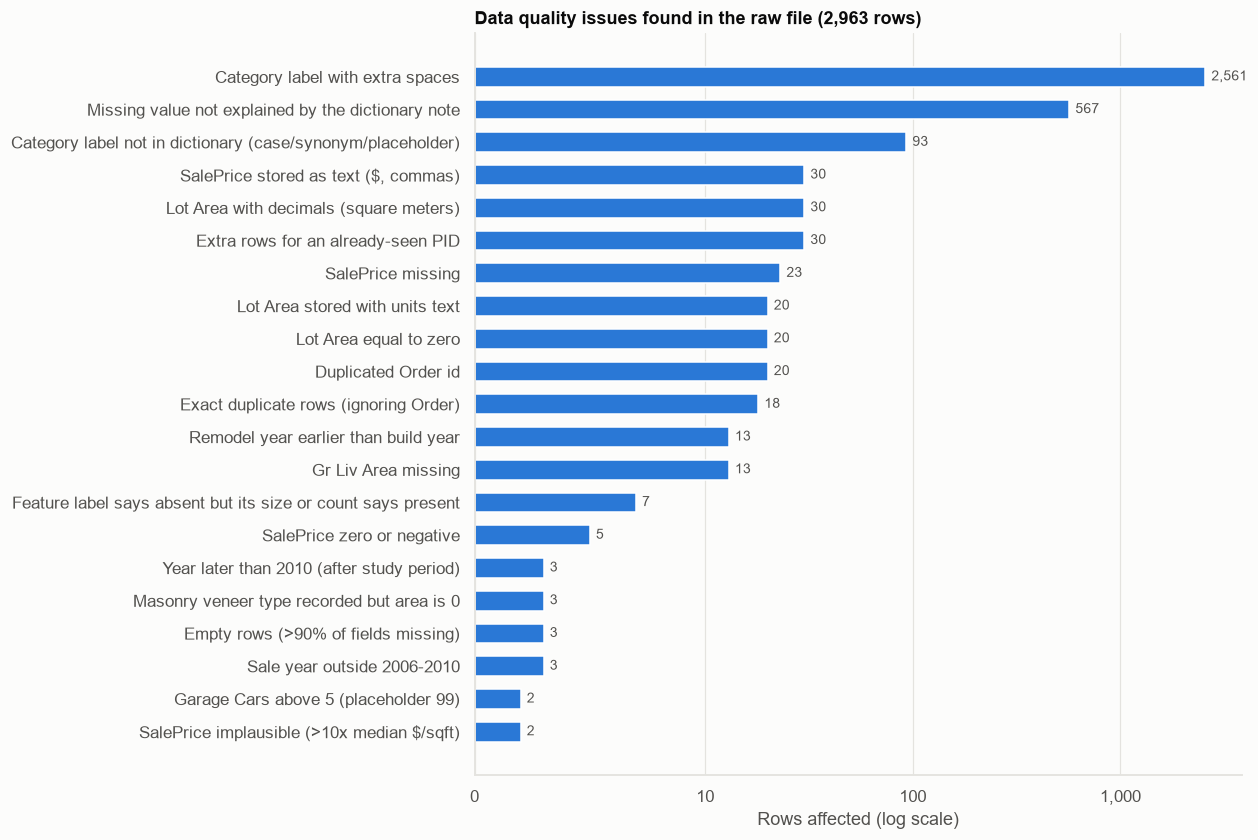

In [10]:
issues = audit_raw[audit_raw > 0].sort_values()
fig, ax = plt.subplots(figsize=(9, 0.36 * len(issues) + 1.2))
ax.barh(issues.index, issues.values, color=COLORS["blue"], height=0.6)
for y, v in enumerate(issues.values):
    ax.annotate(f"{v:,}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=COLORS["text2"])
ax.set_xscale("symlog", linthresh=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Rows affected (log scale)")
ax.set_title(f"Data quality issues found in the raw file ({len(raw):,} rows)")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_raw_data_quality_issues")
plt.show()

The structural missing values (no pool, no garage, and so on) are **not** counted as issues. The dictionary defines them as "the feature does not exist", and step 9 encodes them explicitly.

<a id="s1-3"></a>

### 1.3 Repair pipeline

Each step works on a copy of the raw data and appends one or more entries to `QUALITY_LOG`: the issue, the rows affected, the action taken and the rationale.

In [11]:
QUALITY_LOG = []


def log(step, issue, rows, action, rationale):
    QUALITY_LOG.append({"step": step, "issue": issue, "rows_affected": int(rows),
                        "action": action, "rationale": rationale})


df = raw.copy()

**Step 1: Empty rows.** A few rows (count printed below) have no PID, no price and almost every field blank. They carry no information.

In [12]:
empty = df.isna().mean(axis=1) > 0.9
log(1, "Empty rows", empty.sum(), "Dropped", "No PID, no price, >90% of fields blank")
df = df.loc[~empty].copy()
print(f"Dropped {empty.sum()} empty rows -> {len(df):,} rows")

Dropped 3 empty rows -> 2,960 rows


**Step 2: Numbers stored as text, and wrong units.**
- `SalePrice` written as `"$215,000"` and `Lot Area` written as `"5362 sqft"`: the text is stripped; the values themselves are correct.
- `Lot Area` values with a decimal point (e.g. `713.2`) were recorded in **square meters**. They are about ten times smaller than typical lots, and one sale appears again in square feet (both checks printed below). They are converted (1 m² = 10.764 sqft).
- `Lot Area = 0` is impossible and becomes missing.

In [13]:
SQM_TO_SQFT = 10.7639

# SalePrice: remove "$" and thousands separators
price_txt = df["SalePrice"].astype("string")
has_symbols = price_txt.str.contains(r"[$,]", na=False)
df["SalePrice"] = pd.to_numeric(price_txt.str.replace(r"[$,\s]", "", regex=True), errors="coerce")
log(2, "SalePrice stored as text", has_symbols.sum(), "Removed '$' and ',' and converted to number",
    "Formatting problem only; the amount is valid")

# Lot Area: units text, square meters, zeros
lot_txt = df["Lot Area"].astype("string").str.strip()
has_units = lot_txt.str.contains(r"[A-Za-z]", na=False)
in_sqm = lot_txt.str.contains(r"\.", na=False)
lot = pd.to_numeric(lot_txt.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
lot_before_conversion = lot.copy()
lot = lot.where(~in_sqm, (lot * SQM_TO_SQFT).round())
zero_lot = lot == 0
df["Lot Area"] = lot.mask(zero_lot)
log(2, "Lot Area with units text ('sqft')", has_units.sum(), "Removed text, kept the number",
    "Formatting problem only")
log(2, "Lot Area recorded in square meters", in_sqm.sum(), "Multiplied by 10.764 and rounded",
    "Only decimal values in a whole-number column, ~10x below typical lots, confirmed by a duplicate record")
log(2, "Lot Area equal to zero", zero_lot.sum(), "Set to missing (imputed later in the pipeline)",
    "A lot cannot have zero area")

# Identifier-like numeric codes read as floats -> integers
df["PID"] = df["PID"].astype("Int64")
df["MS SubClass"] = df["MS SubClass"].astype("Int64")

In [14]:
# Evidence for the square-meter conversion: corrupted values vs. their neighborhood's typical lot
nbhd_median_lot = lot.where(~in_sqm).groupby(df["Neighborhood"]).median()
sqm_evidence = pd.DataFrame({
    "PID": df.loc[in_sqm, "PID"],
    "Neighborhood": df.loc[in_sqm, "Neighborhood"],
    "value as recorded": lot_before_conversion[in_sqm],
    "converted to sqft": lot[in_sqm],
    "neighborhood median (sqft)": df.loc[in_sqm, "Neighborhood"].map(nbhd_median_lot),
})
sqm_evidence["recorded / median"] = (sqm_evidence["value as recorded"] / sqm_evidence["neighborhood median (sqft)"]).round(2)
sqm_evidence["converted / median"] = (sqm_evidence["converted to sqft"] / sqm_evidence["neighborhood median (sqft)"]).round(2)
print("Median ratio to the neighborhood's typical lot -> as recorded: "
      f"{sqm_evidence['recorded / median'].median():.2f} | after conversion: {sqm_evidence['converted / median'].median():.2f}")
# The same sale recorded a second time in square feet confirms the unit
raw_lot_txt = raw["Lot Area"].astype("string")
twins = raw.loc[raw["PID"].isin(df.loc[in_sqm, "PID"].astype(float)) & ~raw_lot_txt.str.contains(r"\.", na=False),
                ["PID", "Lot Area"]]
for pid, sqft_text in twins.itertuples(index=False):
    sqm = lot_before_conversion[in_sqm & df["PID"].eq(int(pid))].iloc[0]
    print(f"PID {int(pid)}: {sqm} in one record, {sqft_text} in its duplicate -> "
          f"{sqm} x {SQM_TO_SQFT} = {sqm * SQM_TO_SQFT:,.0f} sqft")
sqm_evidence.head(10)

Median ratio to the neighborhood's typical lot -> as recorded: 0.10 | after conversion: 1.02
PID 535305160: 713.2 in one record, 7677 in its duplicate -> 713.2 x 10.7639 = 7,677 sqft


,PID,Neighborhood,value as recorded,converted to sqft,neighborhood median (sqft),recorded / median,converted / median
27,533350120,Veenker,1512.4,16279.0,13165.0,0.11,1.24
45,907192030,CollgCr,830.1,8935.0,9675.0,0.09,0.92
82,905107240,Sawyer,960.1,10334.0,9402.0,0.1,1.1
246,905300020,Sawyer,947.6,10200.0,9402.0,0.1,1.08
427,527402380,NAmes,868.9,9353.0,9486.0,0.09,0.99
460,528427020,Somerst,893.0,9612.0,8125.0,0.11,1.18
483,923277030,Mitchel,613.1,6599.0,10172.0,0.06,0.65
639,902406020,OldTown,905.8,9750.0,7830.0,0.12,1.25
664,535305160,NAmes,713.2,7677.0,9486.0,0.08,0.81
747,534251320,NWAmes,909.5,9790.0,10944.0,0.08,0.89


**Step 3: Category labels.** Labels are matched to the dictionary codes after removing surrounding spaces and ignoring case (`rl`, `Rl`, ` RL` → `RL`). Two synonyms not in the dictionary are mapped explicitly: `paved` → `Pave` and `yes` → `Y`. Placeholders that mean "unknown" (`NA`, `N/A`, `??`, `unknown`) become missing; step 8 recovers them. The cell **asserts** that nothing else is left unmatched, so no label is dropped silently.

In [15]:
SYNONYMS = {"Street": {"paved": "Pave"}, "Central Air": {"yes": "Y"}}
PLACEHOLDERS = {"na", "n/a", "??", "unknown"}

changes = []
for col in CODED_TEXT_COLS:
    original = df[col].astype("string")
    lookup = {code.lower(): code for code in VALID_CODES[col]} | SYNONYMS.get(col, {})
    key = original.str.strip().str.lower()
    mapped = key.map(lookup)
    unmatched = original.notna() & mapped.isna()
    assert key[unmatched].isin(PLACEHOLDERS).all(), f"{col}: unexpected labels {set(original[unmatched])}"
    changed = original.notna() & (original != mapped).fillna(True)
    if changed.any():
        changes.append(pd.DataFrame({"column": col, "original": original[changed],
                                     "cleaned": mapped[changed].fillna("<missing>")}))
    df[col] = mapped.astype(object).where(mapped.notna(), np.nan)

label_changes = pd.concat(changes)
summary = (label_changes.assign(original=label_changes["original"].map(repr))
           .groupby(["column", "original", "cleaned"]).size().rename("rows").reset_index())
log(3, "Category labels with extra spaces / wrong case / synonyms", label_changes.index.nunique(),
    "Mapped to the dictionary code", "Same category written differently; would otherwise split one category into several")
summary

,column,original,cleaned,rows
0,Central Air,'YES',Y,8
1,Central Air,'Yes',Y,8
2,Central Air,'y',Y,7
3,Central Air,'yes',Y,8
4,MS Zoning,' RL',RL,10
5,MS Zoning,'RL ',RL,10
6,MS Zoning,'Rl',RL,10
7,MS Zoning,'rl',RL,10
8,Neighborhood,'??',<missing>,4
9,Neighborhood,'N/A',<missing>,4


**Step 4: Duplicates.** Once formats are normalized (step 2), more rows become exact copies: `"$330,000"` and `330000` now match. Exact copies are dropped first. Then we look at PIDs that still appear more than once. A PID identifies a property, and a property could legitimately sell twice, so we check whether the repeated rows describe the **same sale** (same month and year).

In [16]:
exact_dup = df.drop(columns="Order").duplicated()
log(4, "Exact duplicate rows", exact_dup.sum(), "Dropped (kept first)", "Same sale recorded twice")
df = df.loc[~exact_dup].copy()

repeated = df[df["PID"].duplicated(keep=False)].sort_values(["PID", "Order"])
same_sale = repeated.groupby("PID")[["Yr Sold", "Mo Sold"]].nunique().max(axis=1).eq(1)
print(f"PIDs still repeated: {repeated['PID'].nunique()} | all repeats share the same sale month: {same_sale.all()}")


def describe_differences(group):
    cols = [c for c in group.columns.drop("Order") if group[c].astype("string").nunique(dropna=False) > 1]
    return "; ".join(f"{c}: " + " vs ".join(group[c].astype("string").fillna("NaN")) for c in cols)


near_dup_table = repeated.groupby("PID").apply(describe_differences, include_groups=False).rename("differences").to_frame()
spread = repeated.groupby("PID").agg(price=("SalePrice", lambda s: (s.max() - s.min()) / s.max()),
                                     lot=("Lot Area", lambda s: s.max() - s.min()))
print(f"Largest difference between copies of the same sale: price {spread['price'].max():.2%}, "
      f"lot area {spread['lot'].max():.0f} sqft")
near_dup_table

PIDs still repeated: 11 | all repeats share the same sale month: True
Largest difference between copies of the same sale: price 0.22%, lot area 1 sqft


,differences
PID,
531367010,Lot Area: 11024.0 vs 11023.0; SalePrice: 18680...
533208020,Garage Yr Blt: 2006.0 vs 1987.0
533213120,Lot Area: 2281.0 vs 2280.0; SalePrice: 173000 ...
533221040,Lot Area: 2999.0 vs 2998.0; SalePrice: 180100 ...
535353060,Lot Area: 9532.0 vs 9533.0; SalePrice: 102800 ...
902205010,Lot Area: 5926.0 vs 5925.0; SalePrice: 45100 v...
903231090,Lot Area: 6240.0 vs 6239.0; SalePrice: 126000 ...
903454100,Lot Area: 6875.0 vs 6876.0; SalePrice: 140900 ...
907202160,Lot Area: 10971.0 vs 10970.0; SalePrice: NaN v...


Every repeated PID is the same sale recorded twice (same sale month). The copies differ only slightly, or by a missing value in one copy: the largest differences are printed above, far too small to change any conclusion. We keep **one record per sale**: the copy with a valid price and the fewest missing values, and on a tie the lowest `Order` (the first recorded).

In [17]:
ranked = (df.assign(_price_ok=df["SalePrice"].gt(0), _n_missing=df.isna().sum(axis=1))
            .sort_values(["PID", "_price_ok", "_n_missing", "Order"], ascending=[True, False, True, True]))
keep = ranked.drop_duplicates("PID").index
n_near = len(df) - len(keep)
log(4, "Same sale recorded twice with small differences (same PID & sale month)", n_near,
    "Kept one record: valid price, fewest missing values, then first Order",
    "Differences <0.1% (about $100 / 1 sqft), so the choice does not affect results")
df = df.loc[df.index.isin(keep)].copy()
assert df["PID"].is_unique and df["Order"].is_unique
print(f"Removed {exact_dup.sum()} exact + {n_near} near duplicates -> {len(df):,} rows; PID and Order are now unique")

Removed 19 exact + 11 near duplicates -> 2,930 rows; PID and Order are now unique


**Step 5: Rebuild missing `Gr Liv Area`.** Above-ground living area is, by definition, 1st floor + 2nd floor + low-quality finished area. The cell below confirms the identity holds in every row where all four values are present, so the missing values can be computed rather than guessed.

In [18]:
components = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
mismatch = ((components - df["Gr Liv Area"]).abs() > 1).sum()
rebuild = df["Gr Liv Area"].isna() & components.notna()
df.loc[rebuild, "Gr Liv Area"] = components[rebuild]
log(5, "Gr Liv Area missing", rebuild.sum(), "Computed as 1st + 2nd + low-quality floor area",
    "Exact identity, verified with 0 mismatches in complete rows")
print(f"Rows where Gr Liv Area differs from the sum of its parts: {mismatch} | "
      f"rebuilt {rebuild.sum()} values; still missing: {df['Gr Liv Area'].isna().sum()}")

Rows where Gr Liv Area differs from the sum of its parts: 0 | rebuilt 10 values; still missing: 0


**Step 6: Invalid sale prices (agreed: drop).** The sale price is what the models learn from, so we do not invent it. There are three kinds of invalid price:
- **missing**;
- **zero or negative**: plausible amounts with a flipped sign, but we cannot verify that;
- **implausible**: price per sqft (`price_per_sqft`) above 10× the median. The table below shows these are placeholder-looking values on ordinary houses.

In [19]:
price_per_sqft = df["SalePrice"] / df["Gr Liv Area"]
target_issue = pd.Series(pd.NA, index=df.index, dtype="string")
target_issue[df["SalePrice"].isna()] = "missing"
target_issue[df["SalePrice"] <= 0] = "zero or negative"
target_issue[price_per_sqft > 10 * price_per_sqft.median()] = "implausible (>10x median $/sqft)"
bad_target = target_issue.notna()

display(df.loc[bad_target & target_issue.ne("missing"),
               ["PID", "Neighborhood", "Gr Liv Area", "Overall Qual", "SalePrice"]]
        .assign(price_per_sqft=price_per_sqft.round(0), issue=target_issue))
print(f"Median $/sqft of valid sales: {price_per_sqft[~bad_target].median():.0f}")
for kind, n in target_issue.value_counts().items():
    log(6, f"SalePrice {kind}", n, "Dropped", "The target is never invented; see the agreed decision")
df = df.loc[~bad_target].copy()
print(f"Dropped {bad_target.sum()} rows with an invalid price -> {len(df):,} rows")

,PID,Neighborhood,Gr Liv Area,Overall Qual,SalePrice,price_per_sqft,issue
300,914476520,Mitchel,1560.0,7.0,12500000,8013.0,implausible (>10x median $/sqft)
660,907135180,CollgCr,990.0,4.0,-129000,-130.0,zero or negative
1360,911204100,IDOTRR,952.0,4.0,9999999,10504.0,implausible (>10x median $/sqft)
1629,903427090,OldTown,1666.0,8.0,-62500,-38.0,zero or negative
1710,910200080,IDOTRR,919.0,6.0,-105000,-114.0,zero or negative
2289,527450460,BrDale,1030.0,6.0,-167900,-163.0,zero or negative
2361,908128100,Edwards,1724.0,7.0,-138400,-80.0,zero or negative


Median $/sqft of valid sales: 120
Dropped 26 rows with an invalid price -> 2,904 rows


**Step 7: Impossible years** (repaired with evidence in the same record).
- **Sold before 2006:** these new homes would be "sold before being built", outside the documented period. The true year is unknown, so the rows are dropped.
- **Built after 2010:** replaced with the garage year if plausible, otherwise the remodel year. **Garage built after 2010:** replaced with the build year.
- **Build year missing:** the earlier of the garage and remodel years (a house is remodeled after it is built, and usually built no later than its garage). The cell tests this rule against a median fill.
- **Remodeled before built:** the remodel year is set to the build year, as the dictionary prescribes for "no remodel".

Homes built one year after their sale are kept: they were sold under construction (`Sale Condition = Partial`).

In [20]:
year_cols = ["Year Built", "Year Remod/Add", "Garage Yr Blt", "Yr Sold", "Sale Condition"]

bad_sale_year = ~df["Yr Sold"].between(2006, 2010)
display(df.loc[bad_sale_year, year_cols])
log(7, "Sale year outside 2006-2010", bad_sale_year.sum(), "Dropped",
    "New homes 'sold before being built' and outside the documented period; true year unrecoverable")
df = df.loc[~bad_sale_year].copy()

bad_built = df["Year Built"] > 2010
before = df.loc[bad_built, year_cols].copy()
garage_ok = df["Garage Yr Blt"].between(1800, 2010)
df.loc[bad_built, "Year Built"] = np.where(garage_ok[bad_built], df.loc[bad_built, "Garage Yr Blt"],
                                           df.loc[bad_built, "Year Remod/Add"])
log(7, "Build year after 2010", bad_built.sum(), "Replaced with garage year (or remodel year)",
    "Same-row evidence: garage and remodel years agree with each other")

bad_garage = df["Garage Yr Blt"] > 2010
before = pd.concat([before, df.loc[bad_garage, year_cols]])
df.loc[bad_garage, "Garage Yr Blt"] = df.loc[bad_garage, "Year Built"]
log(7, "Garage year after 2010", bad_garage.sum(), "Replaced with build year",
    "Garage built with the house (new home); 2207 is a typo")

remod_before_built = df["Year Remod/Add"] < df["Year Built"]
df.loc[remod_before_built, "Year Remod/Add"] = df.loc[remod_before_built, "Year Built"]
log(7, "Remodel year earlier than build year", remod_before_built.sum(), "Set remodel year = build year",
    "Dictionary rule: equal to build year when there was no remodel")

# Missing build year: earlier of garage year and remodel year, tested where all three years are known
known_years = df[["Year Built", "Garage Yr Blt", "Year Remod/Add"]].dropna()
rule_estimate = known_years[["Garage Yr Blt", "Year Remod/Add"]].min(axis=1)
rule_exact = (rule_estimate == known_years["Year Built"]).mean()
rule_mae = (rule_estimate - known_years["Year Built"]).abs().mean()
median_mae = (known_years["Year Built"].median() - known_years["Year Built"]).abs().mean()
missing_built = df["Year Built"].isna() & df[["Garage Yr Blt", "Year Remod/Add"]].notna().any(axis=1)
df.loc[missing_built, "Year Built"] = df.loc[missing_built, ["Garage Yr Blt", "Year Remod/Add"]].min(axis=1)
log(7, "Build year missing", missing_built.sum(), "Filled with the earlier of garage year and remodel year",
    "Same-row evidence; tested on houses where all three years are known (see Key results)")

print("Rows with an impossible build/garage year - before and after:")
display(before.join(df[["Year Built", "Garage Yr Blt"]].add_suffix(" (repaired)")))
built_after_sale = df["Year Built"] > df["Yr Sold"]
assert df.loc[built_after_sale, "Sale Condition"].eq("Partial").all()   # all are sales of homes under construction
print(f"Remodel years corrected: {remod_before_built.sum()} | "
      f"homes built after the sale year (kept, all 'Partial' = under construction): {built_after_sale.sum()}")
print(f"Build year filled for {missing_built.sum()} houses. Rule check on {len(known_years):,} houses with all three "
      f"years: exact for {rule_exact:.1%}, mean error {rule_mae:.1f} years (median imputer: {median_mae:.1f} years)")


,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Sale Condition
629,2006.0,2006.0,2006.0,2005.0,Partial
1800,2006.0,2007.0,2006.0,2005.0,Partial
2181,2007.0,2008.0,2008.0,2005.0,Partial


Rows with an impossible build/garage year - before and after:


,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Sale Condition,Year Built (repaired),Garage Yr Blt (repaired)
510,2099.0,2006.0,2006.0,2007.0,Partial,2006.0,2006.0
1697,2050.0,1968.0,1968.0,2007.0,Normal,1968.0,1968.0
2864,2006.0,2007.0,2207.0,2007.0,Partial,2006.0,2006.0


Remodel years corrected: 11 | homes built after the sale year (kept, all 'Partial' = under construction): 3
Build year filled for 10 houses. Rule check on 2,733 houses with all three years: exact for 84.7%, mean error 3.8 years (median imputer: 24.5 years)


**Step 7b: Placeholder garage capacity.** `Garage Cars` (garage size in car capacity) holds the value 99 in a few rows. That is a placeholder, not a garage. The same row's `Garage Area` (garage size in sqft) shows the real size, so we replace 99 with the capacity whose typical (median) garage area is closest to it.

In [21]:
MAX_REAL_CAPACITY = 5   # the largest real garage in the data holds 5 cars; anything above is a placeholder
bad_capacity = df["Garage Cars"] > MAX_REAL_CAPACITY
valid_garage = df["Garage Cars"].between(1, MAX_REAL_CAPACITY) & df["Garage Area"].gt(0)
median_area = df.loc[valid_garage].groupby("Garage Cars")["Garage Area"].median()
repaired = df.loc[bad_capacity, "Garage Area"].apply(lambda area: (median_area - area).abs().idxmin())

print("Median garage area by capacity (sqft):", median_area.round(0).astype(int).to_dict())
display(pd.DataFrame({"Garage Area (sqft)": df.loc[bad_capacity, "Garage Area"],
                      "Garage Cars as recorded": df.loc[bad_capacity, "Garage Cars"],
                      "Garage Cars repaired": repaired}))
df.loc[bad_capacity, "Garage Cars"] = repaired
log("7b", "Garage Cars placeholder (99)", bad_capacity.sum(),
    "Replaced with the capacity whose median Garage Area is closest", "Same-row evidence: the garage's area shows its real size")

Median garage area by capacity (sqft): {1.0: 288, 2.0: 505, 3.0: 806, 4.0: 892, 5.0: 1184}


,Garage Area (sqft),Garage Cars as recorded,Garage Cars repaired
313,264.0,99.0,1.0
2349,336.0,99.0,1.0


**Step 8: Unknown location codes (agreed: nearest parcel ID).** A PID is a tax-map parcel number, so parcels with close numbers sit close together. Before using this, we **test it**: for every property with a known code, we hide the code and predict it from the nearest other PID (leave-one-out validation). A code is recovered this way only if that accuracy is at least `MIN_LOCATION_ACCURACY` (95%).
- `Neighborhood` (physical location within city limits): placeholders such as `NA` or `??`, set to missing in step 3.
- `MS Zoning` (general zoning classification): empty values. The dictionary note does not list this column, so its gaps are data quality issues. Zoning is tied to location, so the same method applies.

In [22]:
def nearest_pid_label(query, ref_pids, ref_labels):
    """Label of the reference parcel whose PID is numerically closest to each query PID."""
    order = np.argsort(ref_pids)
    p, lab = ref_pids[order], ref_labels[order]
    pos = np.searchsorted(p, query)
    left, right = np.clip(pos - 1, 0, len(p) - 1), np.clip(pos, 0, len(p) - 1)
    use_left = np.abs(query - p[left]) <= np.abs(p[right] - query)
    return np.where(use_left, lab[left], lab[right])


def nearest_pid_loo_accuracy(pids, labels):
    """Leave-one-out: predict each known label from its nearest *other* parcel."""
    order = np.argsort(pids)
    p, lab = pids[order], labels[order]
    d_prev, d_next = np.r_[np.inf, np.diff(p)], np.r_[np.diff(p), np.inf]
    prev_lab, next_lab = np.r_[lab[:1], lab[:-1]], np.r_[lab[1:], lab[-1:]]
    return (np.where(d_prev <= d_next, prev_lab, next_lab) == lab).mean()


MIN_LOCATION_ACCURACY = 0.95   # recover a code from the nearest parcel only if leave-one-out accuracy reaches this

known = df["Neighborhood"].notna()
ref_pids = df.loc[known, "PID"].to_numpy(dtype="int64")
ref_labels = df.loc[known, "Neighborhood"].to_numpy(dtype=object)
loo_acc = nearest_pid_loo_accuracy(ref_pids, ref_labels)
majority_acc = df.loc[known, "Neighborhood"].value_counts(normalize=True).iloc[0]
print(f"Leave-one-out accuracy, nearest PID: {loo_acc:.1%}  (baseline 'most common neighborhood': {majority_acc:.1%})")

assert loo_acc >= MIN_LOCATION_ACCURACY, "nearest-parcel recovery not accurate enough for Neighborhood"
unknown = ~known
df.loc[unknown, "Neighborhood"] = nearest_pid_label(df.loc[unknown, "PID"].to_numpy(dtype="int64"), ref_pids, ref_labels)
log(8, "Neighborhood unknown (NA, N/A, ??, unknown)", unknown.sum(), "Assigned the neighborhood of the nearest parcel ID",
    f"PIDs are spatial; validated at {loo_acc:.1%} leave-one-out accuracy")
display(df.loc[unknown, ["PID", "Neighborhood"]].value_counts("Neighborhood").rename("rows recovered").to_frame().T)

# MS Zoning: same method, same test
known_zone = df["MS Zoning"].notna()
zone_pids = df.loc[known_zone, "PID"].to_numpy(dtype="int64")
zone_labels = df.loc[known_zone, "MS Zoning"].to_numpy(dtype=object)
zone_acc = nearest_pid_loo_accuracy(zone_pids, zone_labels)
zone_majority = df.loc[known_zone, "MS Zoning"].value_counts(normalize=True).iloc[0]
print(f"MS Zoning, leave-one-out accuracy, nearest PID: {zone_acc:.1%}  (baseline 'most common zone': {zone_majority:.1%})")
missing_zone = ~known_zone
if zone_acc >= MIN_LOCATION_ACCURACY:
    df.loc[missing_zone, "MS Zoning"] = nearest_pid_label(df.loc[missing_zone, "PID"].to_numpy(dtype="int64"),
                                                          zone_pids, zone_labels)
    log(8, "MS Zoning missing", missing_zone.sum(), "Assigned the zoning of the nearest parcel ID",
        f"Zoning is tied to location; validated at {zone_acc:.1%} leave-one-out accuracy")
else:
    print("Accuracy below the threshold: MS Zoning gaps are left for the imputer")

Leave-one-out accuracy, nearest PID: 98.8%  (baseline 'most common neighborhood': 15.2%)


Neighborhood,NAmes,BrkSide,Sawyer,Edwards,Gilbert,Timber,IDOTRR,Blmngtn,OldTown,SawyerW,Crawfor
rows recovered,4,2,2,2,2,2,1,1,1,1,1


MS Zoning, leave-one-out accuracy, nearest PID: 98.9%  (baseline 'most common zone': 77.8%)


**Step 9: Features that do not exist.** Per the dictionary's note, an empty value means "the house does not have it" for pools, alleys, fences, fireplaces, masonry veneer, garages, basements and miscellaneous features. These become `"Absent"`, with areas and counts set to 0.
- **Garage and basement fields** count as absent only when the whole feature is absent. A missing garage *finish* on a house that has a garage is a real gap, left for the imputer.
- **Masonry veneer:** an empty type with an area above 0 contradicts the note, because the area shows a veneer exists. The type becomes `"Unknown"` and the area is kept. A recorded type with zero area is kept as recorded and reported by the audit.

In [23]:
STRUCTURAL = {
    # group: (rows where the feature is absent, text columns -> "Absent", numeric columns -> 0)
    "basement": (df["Bsmt Qual"].isna() & df["Total Bsmt SF"].fillna(0).eq(0),
                 ["Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"],
                 ["BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath"]),
    "garage": (df["Garage Type"].isna() & df["Garage Area"].fillna(0).eq(0),
               ["Garage Type", "Garage Finish", "Garage Qual", "Garage Cond"], ["Garage Cars", "Garage Area"]),
    "fireplace": (df["Fireplace Qu"].isna() & df["Fireplaces"].eq(0), ["Fireplace Qu"], []),
    "pool": (df["Pool QC"].isna() & df["Pool Area"].eq(0), ["Pool QC"], []),
    "masonry veneer": (df["Mas Vnr Type"].isna() & ~df["Mas Vnr Area"].gt(0), ["Mas Vnr Type"], ["Mas Vnr Area"]),
    "alley": (df["Alley"].isna(), ["Alley"], []),
    "fence": (df["Fence"].isna(), ["Fence"], []),
    "misc feature": (df["Misc Feature"].isna() & df["Misc Val"].eq(0), ["Misc Feature"], []),
}
for group, (absent, text_cols, num_cols) in STRUCTURAL.items():
    for c in text_cols:
        df.loc[absent & df[c].isna(), c] = ABSENT
    for c in num_cols:
        df.loc[absent & df[c].isna(), c] = 0
    log(9, f"No {group} (NaN by design)", absent.sum(), f"Encoded as '{ABSENT}' (areas/counts = 0)",
        "Dictionary: NaN means the feature does not exist")
print({g: int(m.sum()) for g, (m, _, _) in STRUCTURAL.items()})

# Masonry veneer contradictions (dictionary note: an empty type means no veneer)
veneer_type_unknown = df["Mas Vnr Type"].isna() & df["Mas Vnr Area"].gt(0)
df.loc[veneer_type_unknown, "Mas Vnr Type"] = UNKNOWN
log(9, "Masonry veneer: type empty but area above 0", veneer_type_unknown.sum(),
    f"Type set to '{UNKNOWN}', area kept", "Contradicts the dictionary note; the area shows a veneer exists")
type_without_area = df["Mas Vnr Type"].notna() & ~df["Mas Vnr Type"].isin([ABSENT, UNKNOWN]) & df["Mas Vnr Area"].eq(0)
log(9, "Masonry veneer: type recorded but area is 0", type_without_area.sum(), "Kept as recorded",
    "The data does not show which of the two fields is wrong")
print(f"Masonry veneer: type set to '{UNKNOWN}' for {veneer_type_unknown.sum()} rows; "
      f"type recorded with zero area (kept as recorded): {type_without_area.sum()} rows")

{'basement': 79, 'garage': 156, 'fireplace': 1407, 'pool': 2888, 'masonry veneer': 1754, 'alley': 2706, 'fence': 2333, 'misc feature': 2796}


Masonry veneer: type set to 'Unknown' for 7 rows; type recorded with zero area (kept as recorded): 3 rows


<a id="s1-4"></a>

### 1.4 Verification: re-run the audit on the cleaned data

Every check must reach zero after cleaning, except two that remain **by design**: real gaps that are investigated in 1.7 and filled by the imputer inside the model pipeline, and a masonry inconsistency kept as recorded (step 9). The table states the reason next to each.

In [24]:
audit_clean = audit(df)
REMAIN_BY_DESIGN = {
    "Missing value not explained by the dictionary note":
        "real gaps: Lot Frontage (dropped in 1.6) and the gaps investigated in 1.7, filled by the imputer",
    "Masonry veneer type recorded but area is 0": "kept as recorded: the data does not show which field is wrong",
}
must_be_zero = audit_clean.drop(list(REMAIN_BY_DESIGN))
assert must_be_zero.eq(0).all(), must_be_zero[must_be_zero > 0]

audit_compare = pd.DataFrame({"raw": audit_raw, "cleaned": audit_clean})
audit_compare["after cleaning"] = [
    "remains by design: " + REMAIN_BY_DESIGN[check] if check in REMAIN_BY_DESIGN else "none left"
    for check in audit_compare.index]
print(f"Rows: {len(raw):,} raw -> {len(df):,} cleaned ({len(raw) - len(df)} removed). "
      f"All {len(must_be_zero)} checks that must reach zero do; {len(REMAIN_BY_DESIGN)} remain by design.")
unexplained_rows = unexplained_missing(df)
print(f"Sales with a gap the dictionary note does not explain: {unexplained_rows.any(axis=1).sum():,}; "
      f"excluding Lot Frontage (dropped in 1.6): {unexplained_rows.drop(columns='Lot Frontage').any(axis=1).sum():,}")
with pd.option_context("display.max_colwidth", None):
    display(audit_compare)

Rows: 2,963 raw -> 2,901 cleaned (62 removed). All 20 checks that must reach zero do; 2 remain by design.

Sales with a gap the dictionary note does not explain: 524; excluding Lot Frontage (dropped in 1.6): 42


,raw,cleaned,after cleaning
Empty rows (>90% of fields missing),3,0,none left
Exact duplicate rows (ignoring Order),18,0,none left
Extra rows for an already-seen PID,30,0,none left
Duplicated Order id,20,0,none left
"SalePrice stored as text ($, commas)",30,0,none left
SalePrice missing,23,0,none left
SalePrice zero or negative,5,0,none left
SalePrice implausible (>10x median $/sqft),2,0,none left
Lot Area stored with units text,20,0,none left
Lot Area with decimals (square meters),30,0,none left


In [25]:
df.to_csv(PROCESSED_DIR / "clean_all_sales.csv", index=False)
print(f"Saved {len(df):,} valid sales to {(PROCESSED_DIR / 'clean_all_sales.csv').relative_to(ROOT)}")

Saved 2,901 valid sales to data\processed\clean_all_sales.csv


<a id="s1-5"></a>

### 1.5 Analysis sample: which sales the price models learn from

**Agreed decision:** model **Normal** and **Partial** (new home) sales, with an `is_new_home` flag, and exclude houses above 4,000 sqft. Q3 will be re-checked on Normal sales only. The evidence follows.

**a) Non-market sales sell at a discount.** We fit a simple reference model on Normal sales only (log price ~ log living area + overall quality + build year). We then compare each sale type with the price that model expects for a comparable house. The 95% intervals come from a bootstrap of the median gap (using `rng_for`, so they are reproducible).

In [26]:
ref = df.dropna(subset=["Gr Liv Area", "Overall Qual", "Year Built"]).copy()
X_ref = sm.add_constant(np.column_stack([np.log(ref["Gr Liv Area"]), ref["Overall Qual"], ref["Year Built"]]))
y_ref = np.log(ref["SalePrice"].to_numpy())
is_normal = ref["Sale Condition"].eq("Normal").to_numpy()
ref_fit = sm.OLS(y_ref[is_normal], X_ref[is_normal]).fit()
ref["gap_vs_normal_sale"] = y_ref - ref_fit.predict(X_ref)


rows = []
for cond, g in ref.groupby("Sale Condition"):
    _, lo, hi = bootstrap_ci(np.median, g["gap_vs_normal_sale"], task=f"1.5 sale condition bootstrap: {cond}")
    rows.append({"Sale Condition": cond, "n": len(g), "median price": g["SalePrice"].median(),
                 "median $/sqft": (g["SalePrice"] / g["Gr Liv Area"]).median(),
                 "% vs comparable Normal sale": 100 * np.expm1(g["gap_vs_normal_sale"].median()),
                 "95% CI low": 100 * np.expm1(lo), "95% CI high": 100 * np.expm1(hi)})
cond_effect = pd.DataFrame(rows).set_index("Sale Condition").sort_values("% vs comparable Normal sale")
print(f"Reference model on Normal sales: R² = {ref_fit.rsquared:.3f}")
format_table(cond_effect, ints=["n"], money=["median price", "median $/sqft"],
             pct_signed=["% vs comparable Normal sale", "95% CI low", "95% CI high"])

Reference model on Normal sales: R² = 0.815


,n,median price,median $/sqft,% vs comparable Normal sale,95% CI low,95% CI high
Sale Condition,,,,,,
AdjLand,12,"$110,000",$84,-11.1%,-26.6%,-1.6%
Abnorml,189,"$129,000",$101,-8.2%,-11.2%,-5.0%
Family,44,"$144,900",$110,-4.6%,-11.1%,+2.1%
Normal,"2,392","$158,750",$119,+0.5%,-0.1%,+1.2%
Partial,241,"$250,000",$149,+4.2%,+1.2%,+6.9%
Alloca,23,"$150,909",$87,+4.7%,-21.8%,+7.3%


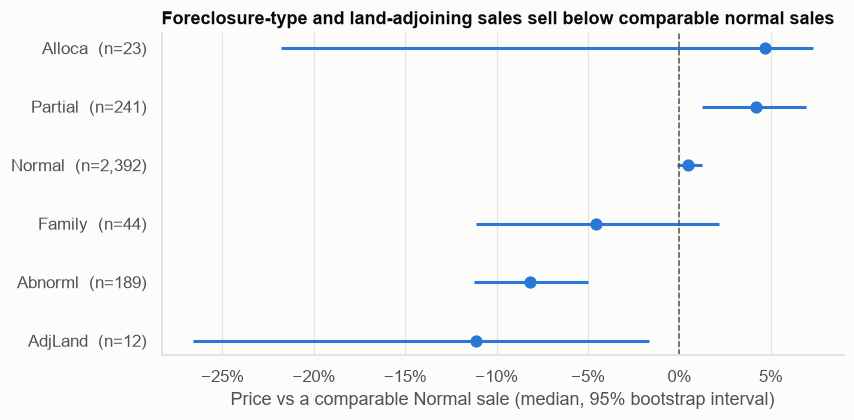

In [27]:
t = cond_effect.sort_values("% vs comparable Normal sale")
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(t))
ax.errorbar(t["% vs comparable Normal sale"], y,
            xerr=[t["% vs comparable Normal sale"] - t["95% CI low"], t["95% CI high"] - t["% vs comparable Normal sale"]],
            fmt="o", color=COLORS["blue"], ecolor=COLORS["blue"], elinewidth=2, markersize=7, capsize=0)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(y, labels=[f"{c}  (n={n:,})" for c, n in zip(t.index, t["n"])])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Price vs a comparable Normal sale (median, 95% bootstrap interval)")
ax.set_title("Foreclosure-type and land-adjoining sales sell below comparable normal sales")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_sale_condition_discount")
plt.show()

**b) Houses above 4,000 sqft.** These are rare (counts printed below). The dataset's author recommends removing all houses above 4,000 sqft. The table compares each market sale above that size with a reference model fitted *without* them. The new homes in Edwards sold for a fraction of what their size and quality imply, which points to incomplete transactions. The NoRidge sale is a genuine luxury home with no comparable houses to learn from.

In [28]:
market = df["Sale Condition"].isin(["Normal", "Partial"])
large = df["Gr Liv Area"] > 4000
fit_data = ref.loc[ref.index.isin(df.index[market & ~large])]
X_fit = sm.add_constant(np.column_stack([np.log(fit_data["Gr Liv Area"]), fit_data["Overall Qual"], fit_data["Year Built"]]))
fit_no_large = sm.OLS(np.log(fit_data["SalePrice"]), X_fit).fit()

big = df.loc[large & market]
X_big = sm.add_constant(np.column_stack([np.log(big["Gr Liv Area"]), big["Overall Qual"], big["Year Built"]]), has_constant="add")
outlier_table = big[["Neighborhood", "Gr Liv Area", "Overall Qual", "Sale Condition", "SalePrice"]].assign(
    expected_price=np.exp(fit_no_large.predict(X_big)).round(-3))
outlier_table["actual vs expected"] = (outlier_table["SalePrice"] / outlier_table["expected_price"] - 1).map("{:+.0%}".format)
print(f"Houses above 4,000 sqft: {large.sum()} among valid sales, {(large & market).sum()} of them market sales (listed below) | "
      f"houses above 3,000 sqft: {(df['Gr Liv Area'] > 3000).sum()}")
outlier_table

Houses above 4,000 sqft: 5 among valid sales, 4 of them market sales (listed below) | houses above 3,000 sqft: 25


,Neighborhood,Gr Liv Area,Overall Qual,Sale Condition,SalePrice,expected_price,actual vs expected
499,Edwards,5642.0,10.0,Partial,160000,621000.0,-74%
618,Edwards,4676.0,10.0,Partial,184750,562000.0,-67%
2276,Edwards,5095.0,10.0,Partial,183850,589000.0,-69%
2319,NoRidge,4316.0,10.0,Normal,755000,518000.0,+46%


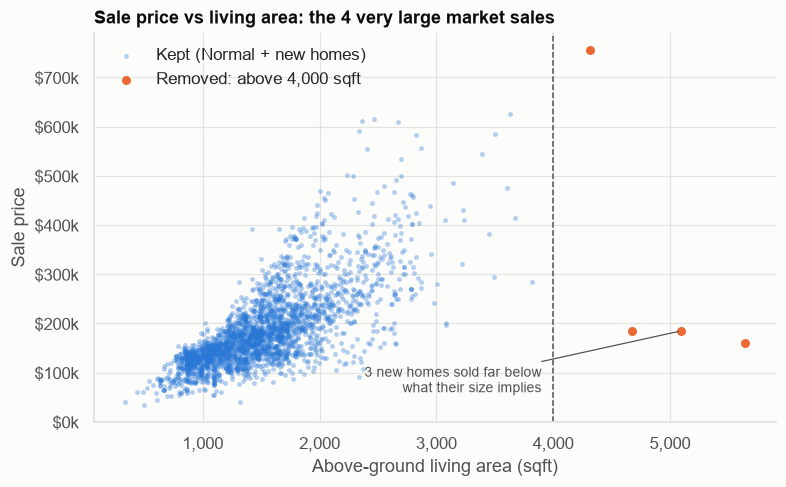

In [29]:
plot_df = df.loc[market]
fig, ax = plt.subplots(figsize=(8, 4.6))
kept = plot_df["Gr Liv Area"] <= 4000
ax.scatter(plot_df.loc[kept, "Gr Liv Area"], plot_df.loc[kept, "SalePrice"], s=10, alpha=0.35,
           color=COLORS["blue"], linewidths=0, label="Kept (Normal + new homes)")
ax.scatter(plot_df.loc[~kept, "Gr Liv Area"], plot_df.loc[~kept, "SalePrice"], s=55,
           color=COLORS["orange"], edgecolor=COLORS["surface"], linewidth=1.5, label="Removed: above 4,000 sqft")
ax.axvline(4000, color=COLORS["text2"], lw=1, ls="--")
ax.annotate("3 new homes sold far below\nwhat their size implies", xy=(5100, 185000), xytext=(3900, 60000),
            fontsize=9, color=COLORS["text2"], ha="right", arrowprops=dict(arrowstyle="-", color=COLORS["text2"], lw=0.8))
ax.yaxis.set_major_formatter(USD)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Above-ground living area (sqft)")
ax.set_ylabel("Sale price")
ax.set_title("Sale price vs living area: the 4 very large market sales")
ax.legend(frameon=False, loc="upper left")
save_fig(fig, "01_large_house_outliers")
plt.show()

In [30]:
sample = df.loc[market & ~large].copy()
# New variable (see "Variables used in this section"): flags new construction so its premium is modeled separately
sample["is_new_home"] = sample["Sale Condition"].eq("Partial").astype(int)
log("1.5", "Non-market sales (Abnorml, Family, Alloca, AdjLand)", (~market).sum(), "Excluded from the analysis sample",
    "Not open-market prices (e.g. foreclosure-type sales ~8% below comparable Normal sales)")
log("1.5", "Houses above 4,000 sqft", (market & large).sum(), "Excluded from the analysis sample",
    "3 incomplete-looking new-home sales, 1 luxury home with no comparables; model valid up to 4,000 sqft")
print(f"Analysis sample: {len(sample):,} sales ({sample['is_new_home'].sum()} new homes, "
      f"{(1 - sample['is_new_home']).sum():,} normal resales)")

Analysis sample: 2,629 sales (238 new homes, 2,391 normal resales)


<a id="s1-6"></a>

### 1.6 Lot Frontage: dropped (team decision)

`Lot Frontage` is the linear feet of street connected to the property. The team decided to drop it after reviewing the evidence below and the cross-validation check in Section 2.4 (model error with and without it).
- **What we give up:** the analysis says nothing about street frontage itself. The lot is still described by `Lot Area` (lot size) and `Lot Config` (inside, corner, cul-de-sac...).
- **Alternative considered:** fill it with the neighborhood median plus a "was missing" flag.

Evidence on the analysis sample:

In [31]:
lf_data = sample.dropna(subset=["Lot Frontage", "Lot Area", "Year Built"])
X_lf = sm.add_constant(np.column_stack([np.log(lf_data["Gr Liv Area"]), lf_data["Overall Qual"],
                                        lf_data["Year Built"], np.log(lf_data["Lot Area"])]))
resid_lf = sm.OLS(np.log(lf_data["SalePrice"]), X_lf).fit().resid
lf_evidence = pd.Series({
    "share missing": sample["Lot Frontage"].isna().mean(),
    "Spearman: Lot Frontage vs price": sample["Lot Frontage"].corr(sample["SalePrice"], method="spearman"),
    "Spearman: Lot Area vs price": sample["Lot Area"].corr(sample["SalePrice"], method="spearman"),
    "Spearman: Lot Frontage vs Lot Area": sample["Lot Frontage"].corr(sample["Lot Area"], method="spearman"),
    "Spearman: Lot Frontage vs price left unexplained by size, quality, age and lot area":
        lf_data["Lot Frontage"].corr(resid_lf, method="spearman"),
}).round(3)
lf_evidence.to_frame("value")

,value
share missing,0.172
Spearman: Lot Frontage vs price,0.416
Spearman: Lot Area vs price,0.438
Spearman: Lot Frontage vs Lot Area,0.671
"Spearman: Lot Frontage vs price left unexplained by size, quality, age and lot area",0.025


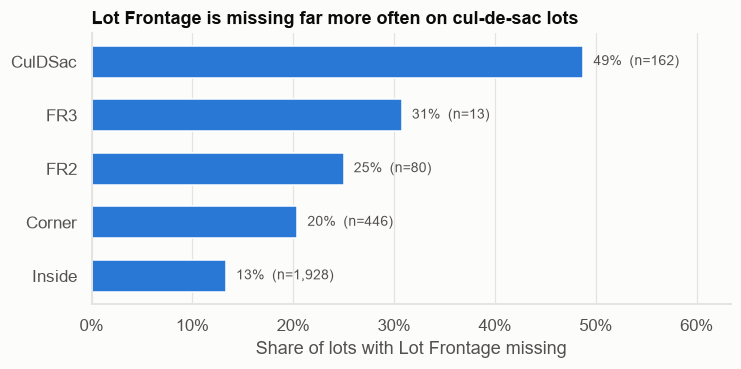

In [32]:
miss = sample.groupby("Lot Config")["Lot Frontage"].agg(share_missing=lambda s: s.isna().mean(), n="size").sort_values("share_missing")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(miss.index, miss["share_missing"], color=COLORS["blue"], height=0.6)
for y, (v, n) in enumerate(zip(miss["share_missing"], miss["n"])):
    ax.text(v + 0.01, y, f"{v:.0%}  (n={n:,})", va="center", fontsize=9, color=COLORS["text2"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_xlim(0, miss["share_missing"].max() * 1.3)
ax.set_xlabel("Share of lots with Lot Frontage missing")
ax.set_title("Lot Frontage is missing far more often on cul-de-sac lots")
ax.grid(axis="y", visible=False)
plt.show()

**Reading.** Lot Frontage tracks Lot Area closely, and once size, quality, age and lot area are accounted for, almost no relationship with price remains. Its gaps are **not random**: they are concentrated on cul-de-sac lots, where frontage is curved and hard to measure. Imputing it would invent values exactly where the measurement makes least sense.

In [33]:
DROP_LOT_FRONTAGE = True   # Team decision (Section 1 review); cross-validation check in Section 2.4

if DROP_LOT_FRONTAGE:
    lf_missing = sample["Lot Frontage"].isna().mean()
    sample = sample.drop(columns="Lot Frontage")
    log("1.6", f"Lot Frontage ({lf_missing:.0%} missing, not at random)", len(sample),
        "Column dropped (team decision; cross-validation check in Section 2.4)",
        "No price information beyond Lot Area; gaps concentrated on cul-de-sac lots")

<a id="s1-7"></a>

### 1.7 Remaining missing values: investigation

The dictionary's note says that empty values outside the listed "feature absent" cases *may indicate a data quality issue worth investigating*. The table classifies every gap left in the analysis sample: how many the note explains, how many are data quality issues, what was found, and how each is handled. These gaps are filled inside the model pipeline (Section 3), which is fitted on training data only, so the test data never influences the filling.

In [34]:
# Investigation of each remaining gap (the assert forces every new gap to be documented here)
INVESTIGATION = {
    "Garage Yr Blt": ("Houses without a garage: no year applies (dictionary note). The rest: a house with a garage "
                      "but no year recorded", "Column dropped in Section 2 (largely duplicates Year Built)"),
    "Lot Area": ("Recorded as 0 (set to missing in step 2) or not recorded. No same-row evidence of lot size, and "
                 "lot sizes vary widely within a neighborhood", "Imputed in the model pipeline"),
    "Bsmt Exposure": ("House has a basement but its exposure was not recorded", "Imputed in the model pipeline"),
    "BsmtFin Type 2": ("House has a basement but its second finish type was not recorded", "Imputed in the model pipeline"),
    "Electrical": ("Electrical system not recorded; no same-row evidence", "Imputed in the model pipeline"),
    "Garage Finish": ("House has a garage but its finish was not recorded", "Imputed in the model pipeline"),
    "Garage Qual": ("House has a garage but its quality was not recorded", "Imputed in the model pipeline"),
    "Garage Cond": ("House has a garage but its condition was not recorded", "Imputed in the model pipeline"),
}
gaps = sample.isna().sum()
gaps = gaps[gaps > 0].sort_values(ascending=False)
assert set(gaps.index) <= set(INVESTIGATION), f"Undocumented gaps: {set(gaps.index) - set(INVESTIGATION)}"
not_explained = unexplained_missing(sample).sum()
investigation = pd.DataFrame({
    "missing": gaps,
    "% of sample": (100 * gaps / len(sample)).round(2),
    "explained by dictionary note": gaps - not_explained[gaps.index],
    "data quality issue": not_explained[gaps.index],
    "finding": [INVESTIGATION[c][0] for c in gaps.index],
    "handling": [INVESTIGATION[c][1] for c in gaps.index],
})
sample.to_csv(PROCESSED_DIR / "analysis_sample.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(investigation)

,missing,% of sample,explained by dictionary note,data quality issue,finding,handling
Garage Yr Blt,120,4.56,119,1,Houses without a garage: no year applies (dictionary note). The rest: a house with a garage but no year recorded,Column dropped in Section 2 (largely duplicates Year Built)
Lot Area,30,1.14,0,30,"Recorded as 0 (set to missing in step 2) or not recorded. No same-row evidence of lot size, and lot sizes vary widely within a neighborhood",Imputed in the model pipeline
Bsmt Exposure,3,0.11,0,3,House has a basement but its exposure was not recorded,Imputed in the model pipeline
BsmtFin Type 2,1,0.04,0,1,House has a basement but its second finish type was not recorded,Imputed in the model pipeline
Electrical,1,0.04,0,1,Electrical system not recorded; no same-row evidence,Imputed in the model pipeline
Garage Finish,1,0.04,0,1,House has a garage but its finish was not recorded,Imputed in the model pipeline
Garage Qual,1,0.04,0,1,House has a garage but its quality was not recorded,Imputed in the model pipeline
Garage Cond,1,0.04,0,1,House has a garage but its condition was not recorded,Imputed in the model pipeline


<a id="s1-8"></a>

### 1.8 Key results and data quality log

The summary below is printed by code, so it always matches the current data. The full log lists every issue, the rows affected, the action taken and the reason.

In [35]:
quality_log = pd.DataFrame(QUALITY_LOG)
quality_log.to_csv(PROCESSED_DIR / "data_quality_log.csv", index=False)

abnormal = cond_effect.loc["Abnorml"]
print("Key results - Section 1")
print(f"  Rows: {len(raw):,} in the raw file -> {len(df):,} valid sales after cleaning ({len(raw) - len(df)} removed) "
      f"-> {len(sample):,} in the analysis sample ({sample['is_new_home'].sum()} new homes)")
print(f"  Audit checks with problems: {int((audit_raw > 0).sum())} of {len(audit_raw)} in the raw file -> "
      f"{int((must_be_zero > 0).sum())} after cleaning, plus {len(REMAIN_BY_DESIGN)} that remain by design (1.4)")
print(f"  Gaps left for the model pipeline: {int(investigation['data quality issue'].sum())} values that are data "
      f"quality issues and {int(investigation['explained by dictionary note'].sum())} explained by the dictionary note (1.7)")
print(f"  Neighborhood from nearest parcel ID: {loo_acc:.1%} leave-one-out accuracy "
      f"(most common neighborhood: {majority_acc:.1%})")
print(f"  Zoning from nearest parcel ID: {zone_acc:.1%} leave-one-out accuracy (most common zone: {zone_majority:.1%})")
print(f"  Build year from earlier of garage/remodel year: exact for {rule_exact:.1%} of checkable houses "
      f"(mean error {rule_mae:.1f} years vs {median_mae:.1f} for a median imputer)")
print(f"  Foreclosure-type sales vs comparable Normal sales: {abnormal['% vs comparable Normal sale']:+.1f}% "
      f"(95% interval {abnormal['95% CI low']:+.1f}% to {abnormal['95% CI high']:+.1f}%)")
print(f"  Saved to {PROCESSED_DIR.relative_to(ROOT)}: clean_all_sales.csv, analysis_sample.csv, data_quality_log.csv")
show_scrollable(quality_log)

Key results - Section 1
  Rows: 2,963 in the raw file -> 2,901 valid sales after cleaning (62 removed) -> 2,629 in the analysis sample (238 new homes)
  Audit checks with problems: 21 of 22 in the raw file -> 0 after cleaning, plus 2 that remain by design (1.4)
  Gaps left for the model pipeline: 39 values that are data quality issues and 119 explained by the dictionary note (1.7)
  Neighborhood from nearest parcel ID: 98.8% leave-one-out accuracy (most common neighborhood: 15.2%)
  Zoning from nearest parcel ID: 98.9% leave-one-out accuracy (most common zone: 77.8%)
  Build year from earlier of garage/remodel year: exact for 84.7% of checkable houses (mean error 3.8 years vs 24.5 for a median imputer)
  Foreclosure-type sales vs comparable Normal sales: -8.2% (95% interval -11.2% to -5.0%)
  Saved to data\processed: clean_all_sales.csv, analysis_sample.csv, data_quality_log.csv


,step,issue,rows_affected,action,rationale
0,1,Empty rows,3,Dropped,"No PID, no price, >90% of fields blank"
1,2,SalePrice stored as text,30,"Removed '$' and ',' and converted to number",Formatting problem only; the amount is valid
2,2,Lot Area with units text ('sqft'),20,"Removed text, kept the number",Formatting problem only
3,2,Lot Area recorded in square meters,30,Multiplied by 10.764 and rounded,"Only decimal values in a whole-number column, ~10x below typical lots, confirmed by a duplicate record"
4,2,Lot Area equal to zero,20,Set to missing (imputed later in the pipeline),A lot cannot have zero area
5,3,Category labels with extra spaces / wrong case / synonyms,2571,Mapped to the dictionary code,Same category written differently; would otherwise split one category into several
6,4,Exact duplicate rows,19,Dropped (kept first),Same sale recorded twice
7,4,Same sale recorded twice with small differences (same PID & sale month),11,"Kept one record: valid price, fewest missing values, then first Order","Differences <0.1% (about $100 / 1 sqft), so the choice does not affect results"
8,5,Gr Liv Area missing,10,Computed as 1st + 2nd + low-quality floor area,"Exact identity, verified with 0 mismatches in complete rows"
9,6,SalePrice missing,19,Dropped,The target is never invented; see the agreed decision


<a id="s1-decisions"></a>

### Decisions and rationale — Section 1


| Decision | Why |
|---|---|
| Remove rows with an invalid sale price. | The target cannot be verified, so it is never invented. |
| Repair values only with evidence from the same record. | Uses the record's own information. Every repair is logged (1.8). |
| Missing build year = the earlier of the garage and remodel years. | Far more accurate than a median fill (1.8). |
| Unknown neighborhood or zoning taken from the nearest parcel, only if at least 95% accurate. | Validated (1.8). Location drives price. |
| "Absent" only where the dictionary says so. Other gaps are investigated (1.7). | Follows the client's dictionary note. |
| One record per duplicated sale. | The copies differ negligibly (step 4). |
| Analysis sample: open-market sales up to 4,000 sqft. | Non-market sales sell at a discount, and very large houses are one-offs (1.5). |
| Lot Frontage dropped. | It adds no information beyond lot size, and its gaps are not random (1.6, 2.8). |

<a id="s2"></a>

## 2. Exploratory data analysis and feature engineering

> **In brief.** *Question:* what do the data show before modeling, and which variables should the models use? *Answer:* prices are skewed, so the models predict log price. Compared like for like, prices were flat over 2006–2010, and they are strongly tied to location and age. After removing constant and duplicated variables, the models keep a set that is as accurate as using every variable. *Numbers:* [Key results](#s2-9). *Decisions:* [end of section](#s2-decisions).

**Approach.** New variables (2.1); the train/test split, **after which everything uses the training set only** (2.2); exploratory figures, each opening with the question it answers (2.3–2.5); shared modeling tools (2.6); variable selection with a glossary of every candidate (2.7); the Lot Frontage check (2.8). Figures on which characteristics move price belong to Q2 and Q3 (Sections 4–5).

<a id="s2-1"></a>

### 2.1 New variables computed from the data

Buyers reason with quantities that are not columns in the data: age at sale, total floor area including the basement, bathrooms counted together. We compute them from each row's own values only, so no information passes between rows. The table gives each one's meaning, formula and purpose; the selection in 2.7 decides which version the models use. `MS SubClass` (dwelling type) is a code, not a quantity, so it is treated as a category.

In [36]:
def engineer_features(df_in):
    """Row-level new variables (each uses only the row's own values, so there is no leakage)."""
    d = df_in.copy()
    d["house_age"] = d["Yr Sold"] - d["Year Built"]
    d["years_since_remod"] = (d["Yr Sold"] - d["Year Remod/Add"]).clip(lower=0)
    d["is_remodeled"] = (d["Year Remod/Add"] > d["Year Built"]).astype(int)
    d["total_sf"] = d["Gr Liv Area"] + d["Total Bsmt SF"]
    d["log_lot_area"] = np.log1p(d["Lot Area"])
    d["log_gr_liv_area"] = np.log1p(d["Gr Liv Area"])
    d["log_total_sf"] = np.log1p(d["total_sf"])
    d["total_baths"] = d["Full Bath"] + 0.5 * d["Half Bath"] + d["Bsmt Full Bath"] + 0.5 * d["Bsmt Half Bath"]
    d["porch_sf"] = d["Wood Deck SF"] + d["Open Porch SF"] + d["Enclosed Porch"] + d["3Ssn Porch"] + d["Screen Porch"]
    d["MS SubClass"] = d["MS SubClass"].astype(str)   # a dwelling-type code, not a quantity
    return d


data_fe = engineer_features(sample)

In [37]:
define_variable("house_age", "Age of the house when it was sold (years)", "Yr Sold - Year Built",
                "Buyers react to a house's age at the time of sale, not to its construction year as such.")
define_variable("years_since_remod", "Years since the last remodel or addition, or since construction if there was none",
                "Yr Sold - Year Remod/Add (minimum 0)",
                "How recently the house was updated; needed for the remodeling question (Q3).")
define_variable("is_remodeled", "1 if the house was remodeled or extended after it was built, otherwise 0",
                "Year Remod/Add > Year Built",
                "Separates updated houses from original-condition ones (Q3). Caveat: about half of the houses built "
                "before 1950 record a remodel year of exactly 1950, the earliest year in the records, so for them the "
                "flag may not reflect a real remodel (team decision: documented, not changed; see 2.5).")
define_variable("total_sf", "Total floor area: above-ground living area plus basement (sqft)", "Gr Liv Area + Total Bsmt SF",
                "Buyers compare houses on total usable space; Gr Liv Area alone leaves out the basement.")
define_variable("log_lot_area", "Lot size on a logarithmic scale", "log(1 + Lot Area)",
                "Very large lots would otherwise dominate a linear model; on a log scale, effects read as % per %.")
define_variable("log_gr_liv_area", "Above-ground living area on a logarithmic scale", "log(1 + Gr Liv Area)",
                "Same information as Gr Liv Area on a compressed scale (see log_lot_area).")
define_variable("log_total_sf", "Total floor area on a logarithmic scale", "log(1 + total_sf)",
                "Same information as total_sf on a compressed scale (see log_lot_area).")
define_variable("total_baths", "All bathrooms, half baths counted as one half",
                "Full Bath + 0.5 Half Bath + Bsmt Full Bath + 0.5 Bsmt Half Bath",
                "Buyers count bathrooms as one feature; four separate counts split that information.")
define_variable("porch_sf", "All outdoor living area: deck and porches (sqft)",
                "Wood Deck SF + Open Porch SF + Enclosed Porch + 3Ssn Porch + Screen Porch",
                "Each porch type alone is rare; together they describe outdoor living space.")


variables_table({
    "SalePrice": "Target (2.3); price per sqft (2.5)",
    "Yr Sold": "Time trend (2.4); house age",
    "Mo Sold": "Seasonality (2.4)",
    "Neighborhood": "Location effect (2.5)",
    "Gr Liv Area": "Size control in the like-for-like index (2.4); price per sqft (2.5)",
    "Overall Qual": "Quality control in the like-for-like index (2.4)",
    "Year Built": "Age control in the like-for-like index (2.4); house age",
    "Year Remod/Add": "Remodel status (2.5)",
    "MS SubClass": "Converted from number to category",
    "is_new_home": "New-home control in the like-for-like index (2.4)",
    "price_per_sqft": "Location and age figures (2.5)",
    "house_age": None, "years_since_remod": None, "is_remodeled": None, "total_sf": None,
    "log_lot_area": None, "log_gr_liv_area": None, "log_total_sf": None, "total_baths": None, "porch_sf": None,
})

,Plain name,Source,Meaning,Codes / formula,Role in this section
Variable,,,,,
SalePrice,Sale price ($),Data dictionary,Sale price of the property in US dollars (numeric).,numeric,Target (2.3); price per sqft (2.5)
Yr Sold,Year of sale,Data dictionary,Year of sale (integer).,numeric,Time trend (2.4); house age
Mo Sold,Month of sale,Data dictionary,Month of sale (integer 1 to 12).,numeric,Seasonality (2.4)
Neighborhood,Neighborhood,Data dictionary,Physical location within city limits.,Blmngtn; Blueste; BrDale; BrkSide; ClearCr; CollgCr; Crawfor; Edwards; ... (28 codes),Location effect (2.5)
Gr Liv Area,Living area above ground (sqft),Data dictionary,Above-grade (ground) living area square feet (numeric).,numeric,Size control in the like-for-like index (2.4); price per sqft (2.5)
Overall Qual,Overall quality (1-10),Data dictionary,Rates the overall material and finish of the house.; Integer from 1 (Very Poor) to 10 (Very Excellent).,numeric,Quality control in the like-for-like index (2.4)
Year Built,Year built,Data dictionary,Original construction year.,numeric,Age control in the like-for-like index (2.4); house age
Year Remod/Add,Year of last remodel,Data dictionary,Remodel year (same as Year Built if no remodel or addition).,numeric,Remodel status (2.5)
MS SubClass,Dwelling type (class code),Data dictionary,Type of dwelling involved in the sale (integer code),120 = 1-STORY PUD 1946 & NEWER; 150 = 1-1/2 STORY PUD ALL AGES; 160 = 2-STORY PUD 1946 & NEWER; 180 = PUD MULTILEVEL - INCL SPLIT LEV/FOYER; 190 = 2 FAMILY CONVERSION ALL STYLES AND AGES; 20 = 1-STORY 1946 & NEWER ALL STYLES; 30 = 1-STORY 1945 & OLDER; 40 = 1-STORY W/FINISHED ATTIC ALL AGES; ... (16 codes),Converted from number to category


<a id="s2-2"></a>

### 2.2 Train/test split (before any analysis)

We hold out 20% of the analysis sample as a **test set**, used only to measure the final models in Section 3. The split is **stratified by price decile**, so both sets cover cheap and expensive homes in the same proportions. Everything below this cell uses `train_df` only.

In [38]:
from sklearn.model_selection import StratifiedShuffleSplit

TEST_SHARE = 0.20
price_deciles = pd.qcut(data_fe["SalePrice"], q=10, labels=False)
splitter = StratifiedShuffleSplit(n_splits=1, test_size=TEST_SHARE, random_state=SEED)
train_idx, test_idx = next(splitter.split(data_fe, price_deciles))
train_df = data_fe.iloc[train_idx].copy()
test_df = data_fe.iloc[test_idx].copy()

pd.DataFrame({
    "sales": [len(train_df), len(test_df)],
    "median price": [train_df["SalePrice"].median(), test_df["SalePrice"].median()],
    "share of new homes": [train_df["is_new_home"].mean().round(3), test_df["is_new_home"].mean().round(3)],
}, index=["train", "test"])

,sales,median price,share of new homes
train,2103,165000.0,0.095
test,526,165000.0,0.072


<a id="s2-3"></a>

### 2.3 Target: model the price or its logarithm?

**Question.** Is the sale price spread evenly enough to model directly? If a few very expensive homes form a long right tail, they dominate a model's squared errors, and a $20,000 error counts the same on a $90,000 house as on a $450,000 one.

**What to look at.** The skewness printed above each panel (0 = symmetric) and the length of the right tail.

**Decision it informs.** The target of every model.

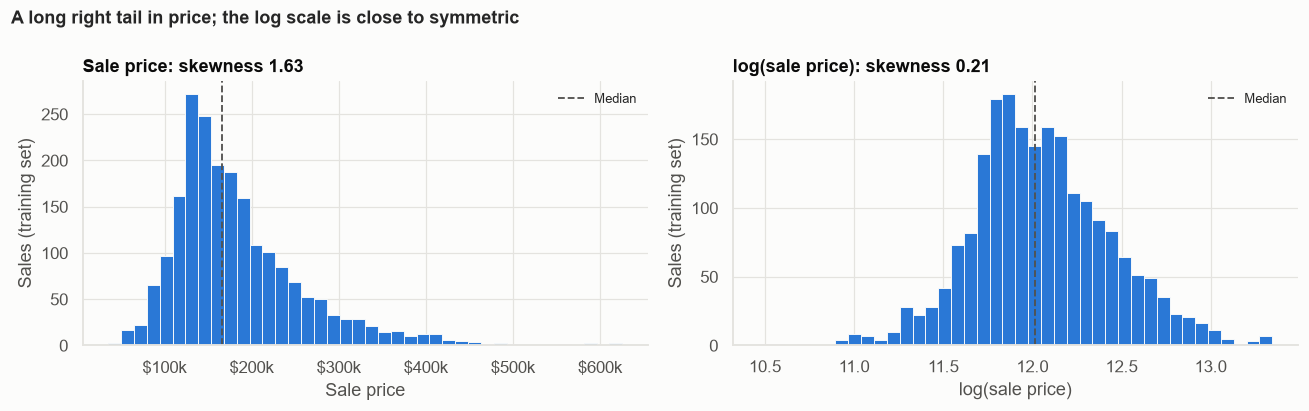

Skewness: price 1.63 -> log(price) 0.21
Price percentiles (training set): 5% $93,540 | 25% $132,000 | median $165,000 | 75% $216,250 | 95% $338,888


In [39]:
log_price_train = np.log(train_df["SalePrice"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, values, label, fmt in [(axes[0], train_df["SalePrice"], "Sale price", USD),
                               (axes[1], log_price_train, "log(sale price)", None)]:
    ax.hist(values, bins=40, color=COLORS["blue"], edgecolor=COLORS["surface"], linewidth=0.6)
    ax.axvline(values.median(), color=COLORS["text2"], lw=1.2, ls="--", label="Median")
    ax.set_title(f"{label}: skewness {values.skew():.2f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Sales (training set)")
    ax.legend(frameon=False, fontsize=8.5)
    if fmt is not None:
        ax.xaxis.set_major_formatter(fmt)
fig.suptitle("A long right tail in price; the log scale is close to symmetric", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
plt.tight_layout()
save_fig(fig, "02_target_distribution")
plt.show()

q = train_df["SalePrice"].quantile([0.05, 0.25, 0.5, 0.75, 0.95])
print(f"Skewness: price {train_df['SalePrice'].skew():.2f} -> log(price) {log_price_train.skew():.2f}")
print(f"Price percentiles (training set): 5% ${q[0.05]:,.0f} | 25% ${q[0.25]:,.0f} | median ${q[0.5]:,.0f} | "
      f"75% ${q[0.75]:,.0f} | 95% ${q[0.95]:,.0f}")

**Reading.** Price is strongly right-skewed. On the log scale the distribution is close to symmetric (skewness printed above).

**Decision.** All models predict **log(price)**, and predictions are converted back to dollars. Errors then behave as percentages: a 10% error means the same on a starter home as on an executive home. That matches how brokers judge a valuation ("within 10%").

<a id="s2-4"></a>

### 2.4 Time: did prices move between 2006 and 2010?

**Question.** The data spans the 2008 financial crisis. If prices drifted, the models would need time variables.

**Method.** Raw medians can mislead, because the *mix* of homes sold changes from year to year. The **like-for-like index** compares each sale with the price expected for a comparable house (same size, quality, build year and new/resale status), from a regression (a statistical model of log price on these characteristics) fitted on the training set. Above zero means "sold above a comparable house". Seasonality is checked by month.

**Decision it informs.** Whether to add time variables, and whether to keep the time-based check in Section 3.

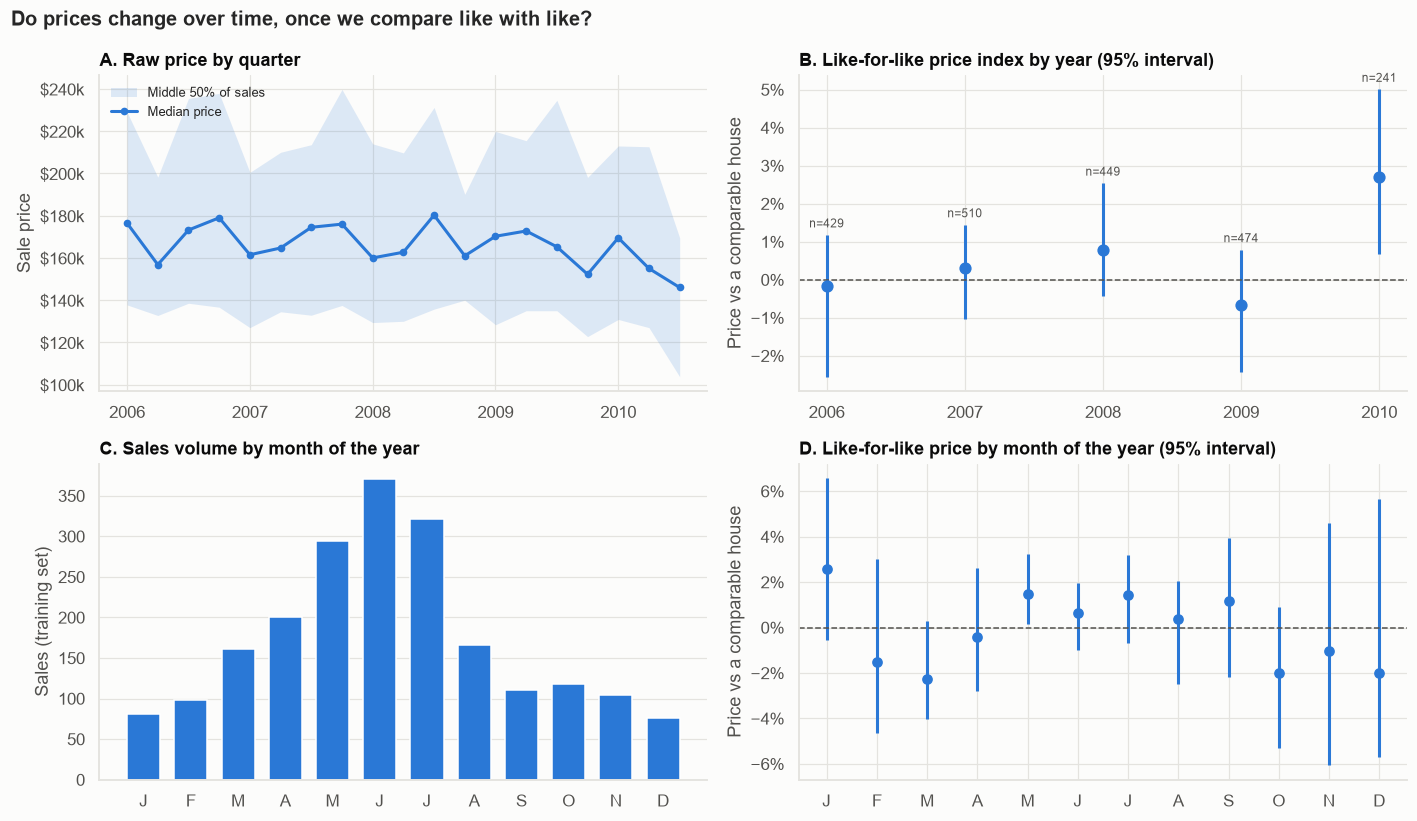

Reference regression for the like-for-like index: R² = 0.833 on 2,103 training sales


,sales,first month,last month,median price,like-for-like %,95% CI low,95% CI high
year,,,,,,,
2006,429,1,12,"$166,000",-0.2%,-2.6%,+1.2%
2007,510,1,12,"$167,150",+0.3%,-1.0%,+1.4%
2008,449,1,12,"$165,000",+0.8%,-0.4%,+2.5%
2009,474,1,12,"$164,750",-0.7%,-2.4%,+0.8%
2010,241,1,7,"$159,900",+2.7%,+0.7%,+5.0%


In [40]:
define_variable(
    "like_for_like_gap",
    "Difference between a sale's log price and the log price expected for a comparable house sold in the same period "
    "(exp(gap) - 1 = % above or below)",
    "log(SalePrice) - reference prediction; reference: log(SalePrice) ~ log(Gr Liv Area) + Overall Qual + Year Built "
    "+ is_new_home, fitted on the training set",
    "Section 2.4: compares prices across periods without the effect of the changing mix of homes sold. Not a model input.")

time_df = train_df[["SalePrice", "Yr Sold", "Mo Sold", "Gr Liv Area", "Overall Qual", "Year Built", "is_new_home"]].copy()
X_time = sm.add_constant(np.column_stack([np.log(time_df["Gr Liv Area"]), time_df["Overall Qual"],
                                          time_df["Year Built"], time_df["is_new_home"]]))
time_ref = sm.OLS(np.log(time_df["SalePrice"]), X_time).fit()
time_df["like_for_like_gap"] = np.log(time_df["SalePrice"]) - time_ref.predict(X_time)
time_df["quarter"] = time_df["Yr Sold"].astype(int).astype(str) + "-Q" + ((time_df["Mo Sold"] - 1) // 3 + 1).astype(int).astype(str)


by_quarter = time_df.groupby("quarter")["SalePrice"].agg(
    median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75), n="size")
by_year = pd.DataFrame([(int(y), len(g), int(g["Mo Sold"].min()), int(g["Mo Sold"].max()), g["SalePrice"].median(),
                         *(100 * np.expm1(bootstrap_ci(np.median, g["like_for_like_gap"], task=f"2.4 like-for-like year {y}"))))
                        for y, g in time_df.groupby("Yr Sold")],
                       columns=["year", "sales", "first month", "last month", "median price",
                                "like-for-like %", "95% CI low", "95% CI high"]).set_index("year")
by_month = pd.DataFrame([(int(m), len(g), *(100 * np.expm1(bootstrap_ci(np.median, g["like_for_like_gap"], task=f"2.4 like-for-like month {m}"))))
                         for m, g in time_df.groupby("Mo Sold")],
                        columns=["month", "sales", "like-for-like %", "95% CI low", "95% CI high"]).set_index("month")

fig, axes = plt.subplots(2, 2, figsize=(13, 7.6))
# A: raw median price by quarter
ax = axes[0, 0]
x = np.arange(len(by_quarter))
ax.fill_between(x, by_quarter["q25"], by_quarter["q75"], color=COLORS["blue"], alpha=0.15, linewidth=0,
                label="Middle 50% of sales")
ax.plot(x, by_quarter["median"], marker="o", ms=4, lw=2, color=COLORS["blue"], label="Median price")
year_starts = [i for i, qtr in enumerate(by_quarter.index) if qtr.endswith("Q1")]
ax.set_xticks(year_starts, labels=[by_quarter.index[i][:4] for i in year_starts])
ax.yaxis.set_major_formatter(USD)
ax.set_ylabel("Sale price")
ax.set_title("A. Raw price by quarter")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
# B: like-for-like index by year
ax = axes[0, 1]
ax.errorbar(by_year.index, by_year["like-for-like %"],
            yerr=[by_year["like-for-like %"] - by_year["95% CI low"], by_year["95% CI high"] - by_year["like-for-like %"]],
            fmt="o", ms=7, color=COLORS["blue"], elinewidth=2, capsize=0)
ax.axhline(0, color=COLORS["text2"], lw=1, ls="--")
for yr, row in by_year.iterrows():
    ax.annotate(f"n={int(row['sales'])}", (yr, row["95% CI high"]), xytext=(0, 5), textcoords="offset points",
                ha="center", fontsize=8, color=COLORS["text2"])
ax.set_xticks(by_year.index)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("Price vs a comparable house")
ax.set_title("B. Like-for-like price index by year (95% interval)")
# C: sales volume by calendar month
ax = axes[1, 0]
ax.bar(by_month.index, by_month["sales"], color=COLORS["blue"], width=0.7)
ax.set_xticks(range(1, 13), labels=["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_ylabel("Sales (training set)")
ax.set_title("C. Sales volume by month of the year")
ax.grid(axis="x", visible=False)
# D: like-for-like gap by calendar month
ax = axes[1, 1]
ax.errorbar(by_month.index, by_month["like-for-like %"],
            yerr=[by_month["like-for-like %"] - by_month["95% CI low"], by_month["95% CI high"] - by_month["like-for-like %"]],
            fmt="o", ms=6, color=COLORS["blue"], elinewidth=2, capsize=0)
ax.axhline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_xticks(range(1, 13), labels=["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("Price vs a comparable house")
ax.set_title("D. Like-for-like price by month of the year (95% interval)")
fig.suptitle("Do prices change over time, once we compare like with like?", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "02_time_and_seasonality")
plt.show()

print(f"Reference regression for the like-for-like index: R² = {time_ref.rsquared:.3f} on {len(time_df):,} training sales")
format_table(by_year, ints=["sales", "first month", "last month"], money=["median price"],
             pct_signed=["like-for-like %", "95% CI low", "95% CI high"])

**Reading.**
- **No market-wide trend.** Compared like for like, 2006–2009 sit close together, with intervals that include zero (panel B). The 2008 crisis left no visible mark on these prices.
- **The raw 2010 dip is a mix effect.** 2010's like-for-like index is slightly *above* the other years, while its raw median is the lowest (table). 2010 covers January–July only.
- **Volume is seasonal, prices are not** (panels C and D).

**Decision.** No time variables are needed; the selection in 2.7 tests sale year and month anyway. The 2006–2009 → 2010 check is kept in Section 3.

<a id="s2-5"></a>

### 2.5 Location and age

**Questions.** (1) Does location matter beyond size? Price per square foot removes most of the size effect, so differences between neighborhoods point to location (gray dots: fewer than 10 sales). (2) Does value fall with age, and do remodeled houses hold their value better? This matters for Q3.

**Decisions they inform.** Neighborhood as a model input; age and remodel variables as candidates.

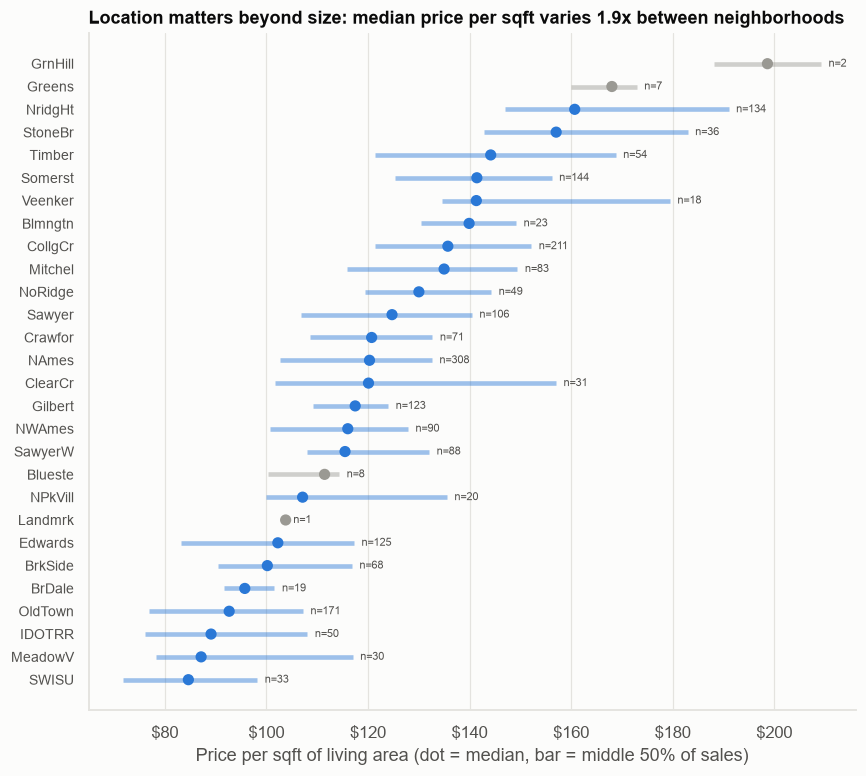

Neighborhoods with at least 10 training sales: 24 of 28 | highest / lowest median price per sqft: 1.90x | Kruskal-Wallis test of equal distributions: p = 4.3e-168


In [41]:
from scipy.stats import kruskal

MIN_SALES_RELIABLE = 10
ppsf_train = train_df["SalePrice"] / train_df["Gr Liv Area"]
nbhd = ppsf_train.groupby(train_df["Neighborhood"]).agg(
    median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75), n="size").sort_values("median")
reliable = nbhd["n"] >= MIN_SALES_RELIABLE
spread_ratio = nbhd.loc[reliable, "median"].max() / nbhd.loc[reliable, "median"].min()
kw_p = kruskal(*[g.to_numpy() for _, g in ppsf_train.groupby(train_df["Neighborhood"]) if len(g) >= MIN_SALES_RELIABLE]).pvalue

fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(nbhd))
colors = np.where(reliable, COLORS["blue"], COLORS["gray"])
ax.hlines(y, nbhd["q25"], nbhd["q75"], colors=colors, lw=3, alpha=0.45)
ax.scatter(nbhd["median"], y, c=colors, s=40, zorder=3)
for yi, (name, row) in zip(y, nbhd.iterrows()):
    ax.annotate(f"n={int(row['n'])}", (row["q75"], yi), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=7.5, color=COLORS["text2"])
ax.set_yticks(y, labels=nbhd.index, fontsize=9)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Price per sqft of living area (dot = median, bar = middle 50% of sales)")
ax.set_title(f"Location matters beyond size: median price per sqft varies {spread_ratio:.1f}x between neighborhoods")
ax.grid(axis="y", visible=False)
save_fig(fig, "02_neighborhood_price_per_sqft")
plt.show()
print(f"Neighborhoods with at least {MIN_SALES_RELIABLE} training sales: {reliable.sum()} of {len(nbhd)} | "
      f"highest / lowest median price per sqft: {spread_ratio:.2f}x | "
      f"Kruskal-Wallis test of equal distributions: p = {kw_p:.1e}")

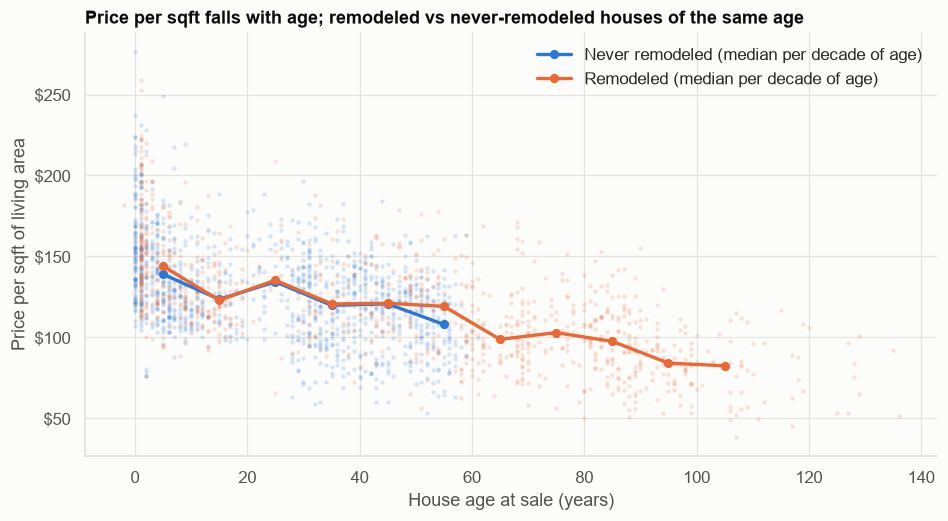

Spearman correlation, house age vs price per sqft: -0.59
Houses built before 1950 with a remodel year of exactly 1950 (earliest year in the records): 203 of 418 (49%); they count as 'remodeled' in this figure


group,Never remodeled,Remodeled
age_bin,,
5.0,139.0,144.0
15.0,124.0,123.0
25.0,134.0,135.0
35.0,120.0,121.0
45.0,121.0,121.0
55.0,108.0,119.0
65.0,<NA>,99.0
75.0,<NA>,103.0
85.0,<NA>,98.0


In [42]:
AGE_BIN_YEARS = 10
MIN_SALES_PER_BIN = 15
age_df = pd.DataFrame({"age": train_df["house_age"], "ppsf": ppsf_train,
                       "group": np.where(train_df["is_remodeled"].eq(1), "Remodeled", "Never remodeled")})
age_df["age_bin"] = (age_df["age"] // AGE_BIN_YEARS) * AGE_BIN_YEARS + AGE_BIN_YEARS / 2
binned = (age_df.groupby(["group", "age_bin"])["ppsf"].agg(median="median", n="size").reset_index()
          .query("n >= @MIN_SALES_PER_BIN"))

fig, ax = plt.subplots(figsize=(10, 5))
group_colors = {"Never remodeled": COLORS["blue"], "Remodeled": COLORS["orange"]}
for group, color in group_colors.items():
    pts = age_df[age_df["group"] == group]
    ax.scatter(pts["age"], pts["ppsf"], s=8, alpha=0.18, color=color, linewidths=0)
    line = binned[binned["group"] == group]
    ax.plot(line["age_bin"], line["median"], marker="o", ms=5, lw=2.2, color=color, label=f"{group} (median per decade of age)")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("House age at sale (years)")
ax.set_ylabel("Price per sqft of living area")
ax.set_title("Price per sqft falls with age; remodeled vs never-remodeled houses of the same age")
ax.legend(frameon=False, loc="upper right")
save_fig(fig, "02_age_and_remodel")
plt.show()

age_rho = age_df["age"].corr(age_df["ppsf"], method="spearman")
built_pre1950 = train_df["Year Built"] < 1950
floor_1950 = built_pre1950 & train_df["Year Remod/Add"].eq(1950)
print(f"Spearman correlation, house age vs price per sqft: {age_rho:.2f}")
print(f"Houses built before 1950 with a remodel year of exactly 1950 (earliest year in the records): "
      f"{floor_1950.sum()} of {built_pre1950.sum()} ({floor_1950.sum() / built_pre1950.sum():.0%}); "
      f"they count as 'remodeled' in this figure")
binned.pivot(index="age_bin", columns="group", values="median").round(0)

**Reading.**
- **Location matters beyond size.** Price per sqft differs strongly between neighborhoods (ratio and test printed above).
- **Price per sqft falls with age** (correlation printed above).
- **A recorded remodel alone is not associated with a higher price per sqft.** Remodeled and never-remodeled houses of the same age sell at similar prices (table). Caution: about half of the houses built before 1950 record a remodel year of exactly 1950, the earliest year in the records, so for old houses the flag partly reflects record keeping (team decision: documented, not changed). What a remodel adds, other things equal, is Q3.

<a id="s2-6"></a>

### 2.6 Shared modeling tools

Used by the selection below and by every model in Sections 3–6. Every step that learns from data sits inside a scikit-learn `Pipeline`, so in cross-validation it is fitted on the training folds only.
- **Ordered categories** (`ORDINAL_MAP`, e.g. Poor < Fair < Typical < Good < Excellent) become ranks. Orderings are kept as defined (team decision). `Bsmt Qual` is the basement's **height**, per the dictionary.
- **Unordered categories** are one-hot encoded (one yes/no column per category value); categories with fewer than 5 sales are grouped together.
- **Missing values** get the median (numbers) or the most frequent value (categories).
- **Linear models** (Ridge, ElasticNet) take skewed amounts (`SKEWED_COLS`, skewness above 1) on a log scale and standardize all inputs. Tree models use the original values.
- **Back to dollars.** A model of log(price) predicts the *typical* (median) price, which is what we report (team decision).

In [43]:
# Ordered categories, in increasing order (codes from the data dictionary)
ORDINAL_MAP = {
    "Lot Shape": ["IR3", "IR2", "IR1", "Reg"],
    "Land Slope": ["Sev", "Mod", "Gtl"],
    "Exter Qual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Exter Cond": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Qual": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Cond": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Exposure": ["Absent", "No", "Mn", "Av", "Gd"],
    "BsmtFin Type 1": ["Absent", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFin Type 2": ["Absent", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "Heating QC": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Kitchen Qual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "Fireplace Qu": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Garage Finish": ["Absent", "Unf", "RFn", "Fin"],
    "Garage Qual": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Garage Cond": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Paved Drive": ["N", "P", "Y"],
    "Pool QC": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Fence": ["Absent", "MnWw", "GdWo", "MnPrv", "GdPrv"],
    "Electrical": ["FuseP", "FuseF", "FuseA", "Mix", "SBrkr"],
}


# Skewed, non-negative amounts (decided on the training set): log scale for the linear models
SKEWED_COLS = [c for c in train_df.columns
               if c not in ("Order", "PID", "SalePrice") and pd.api.types.is_numeric_dtype(train_df[c])
               and train_df[c].min() >= 0 and train_df[c].skew() > 1]


kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
y_train_log = np.log(train_df["SalePrice"].to_numpy())
p_train_usd = train_df["SalePrice"].to_numpy()
y_test_log = np.log(test_df["SalePrice"].to_numpy())
p_test_usd = test_df["SalePrice"].to_numpy()

LGB_PARAMS = dict(
    n_estimators=500, learning_rate=0.03, num_leaves=24, colsample_bytree=0.7,
    subsample=0.8, subsample_freq=1, min_child_samples=15, reg_alpha=0.1, reg_lambda=1.0,
    random_state=SEED, verbose=-1, n_jobs=-1,
    deterministic=True, force_row_wise=True,  # bit-for-bit repeatable results regardless of thread count
)
RIDGE_ALPHA = 15.0

<a id="s2-7"></a>

### 2.7 Variable selection

**Why select?** About 85 candidates are available: many are nearly constant, several are duplicates. Using them all would mean more inputs for brokers, importance split between near-copies (Q2) and harder explanations. The selection has five stages, run **on the training set only**:

| Stage | Rule |
|---|---|
| 1. Information | Drop variables where one value covers more than 95% of sales. |
| 2. Relevance | Rank variables by their link to log price, from 0 to 1 (rank correlation for numbers and ordered categories; correlation ratio η for unordered categories). |
| 3. Redundancy | For pairs above 0.90 (rank correlation, or Cramér's V for categories), keep the one more linked to price; on a tie, keep the original dictionary variable. This targets true duplicates; related measures such as living vs total area are both kept (team decision). |
| 4. How many | Add variables in order of relevance and measure the cross-validated error. Keep the smallest set within one standard error of the best option, **the full set included**; if none qualifies, use all. Done for Ridge and LightGBM; the larger requirement wins. |
| 5. Business override | Re-add any variable that a Q3 improvement scenario changes, unless a kept duplicate represents it. |

In [44]:
from scipy.stats import chi2_contingency

NEAR_CONSTANT = 0.95
REDUNDANT = 0.90
EXCLUDE = {"Order": "row identifier", "PID": "parcel identifier", "SalePrice": "target",
           "Sale Condition": "defines the sample; its information is in is_new_home"}
CANDIDATES = [c for c in train_df.columns if c not in EXCLUDE]
log_price = np.log(train_df["SalePrice"])
outcome = {}   # variable -> (stage, outcome text)


def kind_of(col):
    if col in ORDINAL_MAP:
        return "ordered category"
    return "number" if pd.api.types.is_numeric_dtype(train_df[col]) else "category"


def as_ranked_number(col):
    """Numbers as they are; ordered categories as their rank in ORDINAL_MAP."""
    if col in ORDINAL_MAP:
        return train_df[col].map({level: i for i, level in enumerate(ORDINAL_MAP[col])})
    return train_df[col]


def link_to_price(col):
    """Strength of a variable's own link to log price, from 0 to 1."""
    if kind_of(col) == "category":
        groups = train_df[col].fillna("missing")
        group_mean = log_price.groupby(groups).transform("mean")
        return float(np.sqrt(((group_mean - log_price.mean()) ** 2).sum() / ((log_price - log_price.mean()) ** 2).sum()))
    return float(abs(as_ranked_number(col).corr(log_price, method="spearman")))


# Stage 1: information
top_share = {c: train_df[c].value_counts(normalize=True, dropna=False).iloc[0] for c in CANDIDATES}
for c, share in top_share.items():
    if share > NEAR_CONSTANT:
        outcome[c] = (1, f"Dropped: nearly constant ({share:.0%} of sales share one value)")
after_stage1 = [c for c in CANDIDATES if c not in outcome]

# Stage 2: relevance
LINK = {c: link_to_price(c) for c in CANDIDATES}
print(f"Stage 1: {len(CANDIDATES)} candidates -> {len(after_stage1)} after dropping nearly constant variables")
print("Stage 2: strongest links to log price:",
      ", ".join(f"{c} {LINK[c]:.2f}" for c in sorted(after_stage1, key=LINK.get, reverse=True)[:8]))

Stage 1: 87 candidates -> 74 after dropping nearly constant variables
Stage 2: strongest links to log price: total_sf 0.82, log_total_sf 0.82, Overall Qual 0.82, Neighborhood 0.77, Gr Liv Area 0.73, log_gr_liv_area 0.73, total_baths 0.71, Garage Cars 0.71


In [45]:
# Stage 3: redundancy
def cramers_v(a, b):
    table = pd.crosstab(a.fillna("missing"), b.fillna("missing"))
    if min(table.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))))


def simplicity(col):
    """Tie-break: prefer original dictionary variables, then computed ones, then log versions."""
    return 0 if col in VAR_DESCRIPTIONS else (2 if col.startswith("log_") else 1)


ranked_cols = [c for c in after_stage1 if kind_of(c) != "category"]
category_cols = [c for c in after_stage1 if kind_of(c) == "category"]
spearman = pd.DataFrame({c: as_ranked_number(c) for c in ranked_cols}).corr(method="spearman").abs()
pairs = [(spearman.loc[a, b], a, b, "Spearman") for i, a in enumerate(ranked_cols) for b in ranked_cols[i + 1:]]
pairs += [(cramers_v(train_df[a], train_df[b]), a, b, "Cramér's V")
          for i, a in enumerate(category_cols) for b in category_cols[i + 1:]]
redundant_pairs = sorted([p for p in pairs if p[0] > REDUNDANT], reverse=True)

alive = set(after_stage1)
for strength, a, b, measure in redundant_pairs:
    if a in alive and b in alive:
        keep, drop = sorted([a, b], key=lambda c: (-round(LINK[c], 6), simplicity(c)))
        alive.discard(drop)
        outcome[drop] = (3, f"Dropped: same information as {keep} ({measure} {strength:.2f}); weaker link to price")
after_stage3 = [c for c in after_stage1 if c in alive]
print(f"Stage 3: {len(redundant_pairs)} redundant pairs -> {len(after_stage1) - len(after_stage3)} variables dropped, "
      f"{len(after_stage3)} remain")
(pd.DataFrame(redundant_pairs, columns=["similarity", "variable A", "variable B", "measure"])
 .assign(**{"variable A": lambda d: d["variable A"].map(plain_name), "variable B": lambda d: d["variable B"].map(plain_name)})
 .round(2))

Stage 3: 8 redundant pairs -> 7 variables dropped, 67 remain


,similarity,variable A,variable B,measure
0,1.00,"Total floor area, living + basement (sqft)",Total floor area (log scale),Spearman
1,1.00,Lot size (sqft),Lot size (log scale),Spearman
2,1.00,Living area above ground (sqft),Living area (log scale),Spearman
3,1.00,Year built,House age at sale (years),Spearman
4,0.99,Year of last remodel,Years since last remodel,Spearman
5,0.92,Basement finish quality (second area),"Finished basement area, second (sqft)",Spearman
6,0.91,Year built,Year garage built,Spearman
7,0.90,Year garage built,House age at sale (years),Spearman


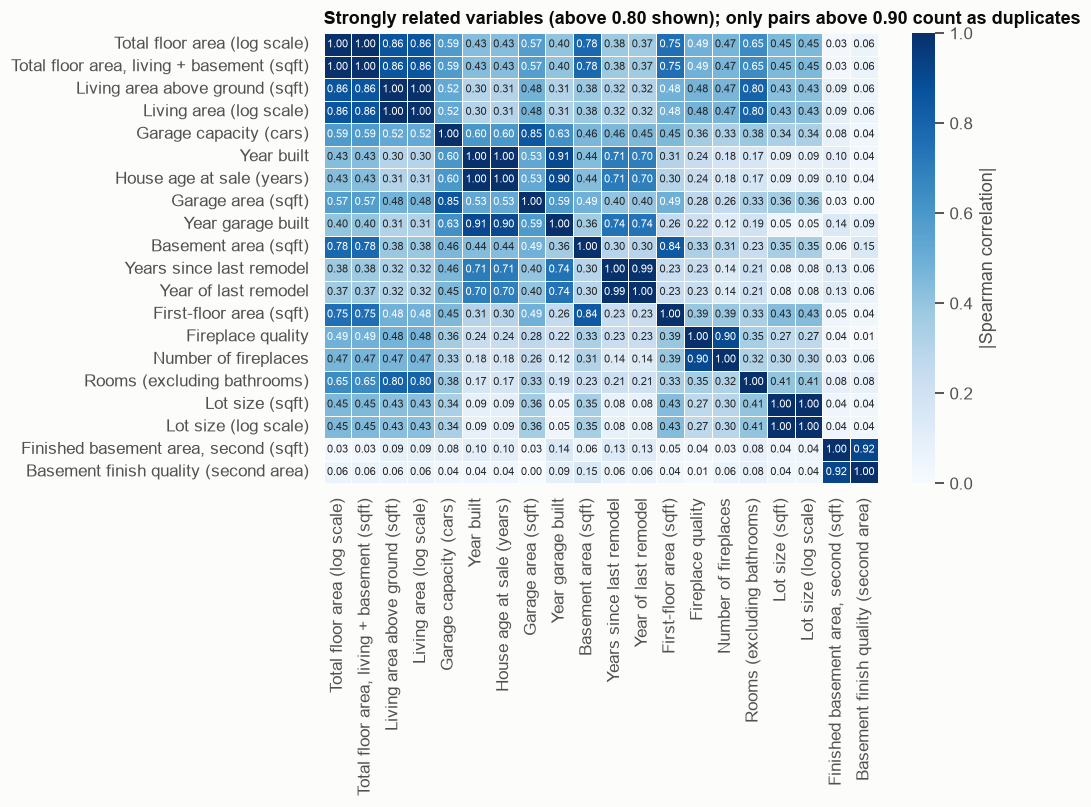

In [46]:
# Figure: the redundancy map for the numeric variables involved in a redundant pair
involved = sorted({v for s, a, b, m in pairs if m == "Spearman" and s > 0.8 for v in (a, b)},
                  key=lambda c: -LINK[c])
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(spearman.loc[involved, involved].rename(index=plain_name, columns=plain_name), cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f",
            annot_kws={"fontsize": 7.5}, linewidths=0.5, linecolor=COLORS["surface"],
            cbar_kws={"label": "|Spearman correlation|"}, ax=ax)
ax.set_title("Strongly related variables (above 0.80 shown); only pairs above 0.90 count as duplicates")
plt.tight_layout()
save_fig(fig, "02_redundancy_map")
plt.show()

**Stage 4: how many variables, and is it better to use all of them?** Variables are added in order of their link to price, and the cross-validated error is measured at each step. The error is the RMSE of log price, which reads roughly as a typical percentage error (0.10 ≈ 10%). The dashed lines show the error when **every candidate** is used. The rule is fixed in advance: keep the smallest set whose error is within one standard error of the best option, the full set included. Extra variables beyond that point add complexity without a gain we can distinguish from noise.

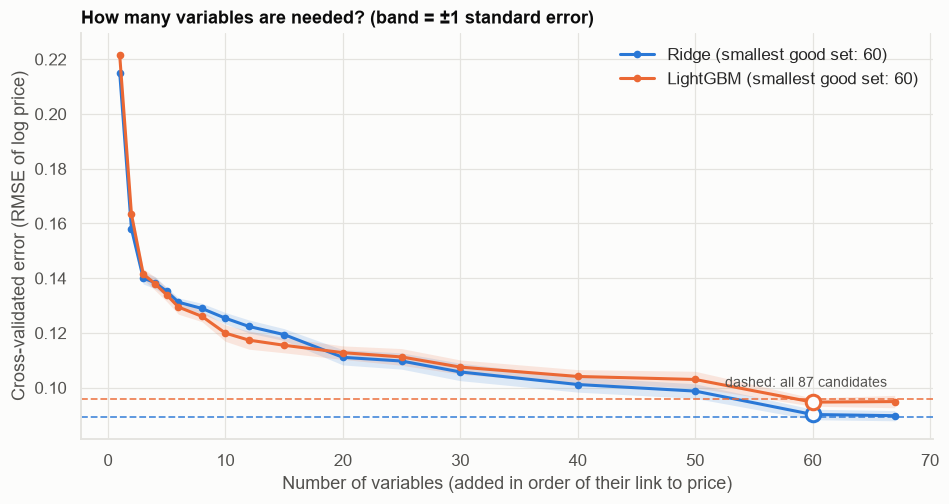

Smallest set within one standard error of the best option: {'LightGBM': 60, 'Ridge': 60} | selected: 60


In [47]:
def cv_log_rmse(model_kind, cols):
    """5-fold cross-validated RMSE of log price on the training set (one value per fold)."""
    X = train_df[cols]
    scores = []
    for tr, va in kf.split(X):
        model = make_model(model_kind, cols).fit(X.iloc[tr], y_train_log[tr])
        scores.append(root_mean_squared_error(y_train_log[va], model.predict(X.iloc[va])))
    return np.array(scores)


relevance_order = sorted(after_stage3, key=lambda c: (-LINK[c], simplicity(c)))
K_GRID = sorted({k for k in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60] if k < len(relevance_order)}
                | {len(relevance_order)})
MODELS_FOR_SELECTION = ["Ridge", "LightGBM"]
curve, all_ref = [], {}
for model_kind in MODELS_FOR_SELECTION:
    for k in K_GRID:
        s = cv_log_rmse(model_kind, relevance_order[:k])
        curve.append({"model": model_kind, "k": k, "mean": s.mean(), "se": s.std(ddof=1) / np.sqrt(len(s))})
    s = cv_log_rmse(model_kind, CANDIDATES)
    all_ref[model_kind] = {"mean": s.mean(), "se": s.std(ddof=1) / np.sqrt(len(s))}
curve = pd.DataFrame(curve)

# One-standard-error rule against the best option, the full candidate set included
chosen_k = {}
for model_kind, g in curve.groupby("model"):
    options = [(r["mean"], r["se"]) for _, r in g.iterrows()] + [(all_ref[model_kind]["mean"], all_ref[model_kind]["se"])]
    best_mean, best_se = min(options)
    good = g[g["mean"] <= best_mean + best_se]
    chosen_k[model_kind] = int(good["k"].min()) if len(good) else None   # None: only the full set is good enough
USE_ALL_CANDIDATES = any(k is None for k in chosen_k.values())
K_SELECTED = len(relevance_order) if USE_ALL_CANDIDATES else max(chosen_k.values())

fig, ax = plt.subplots(figsize=(10, 4.8))
for model_kind, color in [("Ridge", COLORS["blue"]), ("LightGBM", COLORS["orange"])]:
    g = curve[curve["model"] == model_kind]
    ax.fill_between(g["k"], g["mean"] - g["se"], g["mean"] + g["se"], color=color, alpha=0.15, linewidth=0)
    pick_text = "only the full set" if chosen_k[model_kind] is None else f"smallest good set: {chosen_k[model_kind]}"
    ax.plot(g["k"], g["mean"], marker="o", ms=4, lw=2, color=color, label=f"{model_kind} ({pick_text})")
    ax.axhline(all_ref[model_kind]["mean"], color=color, lw=1.2, ls="--", alpha=0.8)
    if chosen_k[model_kind] is not None:
        pick = g[g["k"] == chosen_k[model_kind]]
        ax.scatter(pick["k"], pick["mean"], s=90, facecolor=COLORS["surface"], edgecolor=color, linewidth=2, zorder=4)
ax.annotate(f"dashed: all {len(CANDIDATES)} candidates", (K_GRID[-1], max(r["mean"] for r in all_ref.values())),
            xytext=(-5, 8), textcoords="offset points", ha="right", fontsize=9, color=COLORS["text2"])
ax.set_xlabel("Number of variables (added in order of their link to price)")
ax.set_ylabel("Cross-validated error (RMSE of log price)")
ax.set_title("How many variables are needed? (band = ±1 standard error)")
ax.legend(frameon=False)
save_fig(fig, "02_selection_curve")
plt.show()
print("Smallest set within one standard error of the best option:", chosen_k,
      "| use all candidates:" if USE_ALL_CANDIDATES else "| selected:", "yes" if USE_ALL_CANDIDATES else K_SELECTED)

In [48]:
# Stage 5: business override (provisional list, reviewed in Sections 4-5): variables changed by Q3 scenarios
KEEP_FOR_Q2_Q3 = ["Overall Qual", "Overall Cond", "Kitchen Qual", "Exter Qual", "Central Air", "Heating QC",
                  "BsmtFin Type 1", "BsmtFin SF 1", "Bsmt Unf SF", "Year Remod/Add", "Full Bath", "Half Bath",
                  "Fireplaces", "Fireplace Qu", "Wood Deck SF", "Paved Drive", "Garage Finish", "Fence"]
if USE_ALL_CANDIDATES:
    selected = list(CANDIDATES)
    for c in CANDIDATES:
        stage, text = outcome.get(c, (4, ""))
        outcome[c] = (4, "Kept: all candidates are used (stage 4)" + (f"; flagged at stage {stage}: {text}" if text else ""))
else:
    selected = relevance_order[:K_SELECTED]
    for c in relevance_order[K_SELECTED:]:
        outcome[c] = (4, f"Dropped: not needed (beyond the {K_SELECTED} most price-related variables)")
    for c in KEEP_FOR_Q2_Q3:
        if c in selected:
            continue
        stage, text = outcome.get(c, (None, ""))
        partner = text.split("same information as ")[1].split(" (")[0] if "same information as" in text else None
        if partner in selected:
            outcome[c] = (5, f"{text}; for Q3 it is represented by {partner}")
        else:
            selected.append(c)
            outcome[c] = (5, f"Kept by business override: changed by an improvement scenario in Q3 (was: {text})")
    for c in selected:
        outcome.setdefault(c, (4, "Kept: among the most price-related variables"))

FULL_FEATURE_COLS = CANDIDATES
FEATURE_COLS = selected
NUM_COLS, ORD_COLS, NOM_COLS = split_by_kind(FEATURE_COLS)
print(f"Selected variables: {len(FEATURE_COLS)} ({len(NUM_COLS)} numbers, {len(ORD_COLS)} ordered categories, "
      f"{len(NOM_COLS)} unordered categories) out of {len(CANDIDATES)} candidates")

# Trade-off table: what each set size costs or gains (cross-validated, training set)
SETS = {"top 15": relevance_order[:15], "top 25": relevance_order[:25], f"selected ({len(FEATURE_COLS)})": FEATURE_COLS,
        f"all after stages 1-3 ({len(after_stage3)})": after_stage3, f"all candidates ({len(CANDIDATES)})": CANDIDATES}
tradeoff = []
for label, cols in SETS.items():
    row = {"variable set": label, "variables": len(cols)}
    for model_kind in MODELS_FOR_SELECTION:
        _, _, m = cv_oof_log_model(make_model(model_kind, cols), train_df[cols], y_train_log, p_train_usd, kf)
        row[f"{model_kind} MAPE (%)"] = round(m["MAPE (%)"], 2)
        row[f"{model_kind} MAE ($)"] = round(m["MAE ($)"], 0)
    tradeoff.append(row)
tradeoff = pd.DataFrame(tradeoff).set_index("variable set")
_, _, m_ridge_nolog = cv_oof_log_model(make_model("Ridge", FEATURE_COLS, log_skewed=False), train_df[FEATURE_COLS],
                                       y_train_log, p_train_usd, kf)
print(f"Log-scale check (Ridge, selected variables): MAPE {tradeoff.iloc[2]['Ridge MAPE (%)']:.2f}% with skewed amounts "
      f"on a log scale vs {m_ridge_nolog['MAPE (%)']:.2f}% without")
format_table(tradeoff, ints=["variables"], money=[c for c in tradeoff.columns if "MAE" in c],
             pct=[c for c in tradeoff.columns if "MAPE" in c])

Selected variables: 60 (27 numbers, 16 ordered categories, 17 unordered categories) out of 87 candidates


Log-scale check (Ridge, selected variables): MAPE 6.64% with skewed amounts on a log scale vs 6.76% without


,variables,Ridge MAPE (%),Ridge MAE ($),LightGBM MAPE (%),LightGBM MAE ($)
variable set,,,,,
top 15,15,8.93%,"$15,784",8.41%,"$14,958"
top 25,25,8.15%,"$14,570",8.09%,"$14,479"
selected (60),60,6.64%,"$12,023",6.88%,"$12,534"
all after stages 1-3 (67),67,6.63%,"$12,000",6.93%,"$12,650"
all candidates (87),87,6.56%,"$11,998",6.98%,"$12,681"


**How many variables, and why** (trade-off table):
1. **Removing constant and duplicated variables costs nothing** in accuracy.
2. **Beyond that, each variable adds a little.** The selected set is within one standard error of the best option for both models: slightly above all candidates for Ridge, slightly below for LightGBM.
3. **A compact set is clearly less accurate.** With 15 or 25 variables the typical error rises by more than a percentage point.

**Conclusion.** The models use the selected set: as accurate as every candidate, without the near-constant and duplicated variables. A shorter input for brokers would cost accuracy, so Section 3 uses this set. The log-scale check above shows why linear models take skewed amounts on a log scale.

**Glossary of candidate variables.** Every candidate variable appears below: its source, its meaning (word for word from the data dictionary, or the definition of a computed variable), its type, its link to price, and the outcome of the selection with the reason. Kept variables are listed first, in order of their link to price.

In [49]:
rows = []
for c in CANDIDATES:
    stage, text = outcome[c]
    if c in VAR_DESCRIPTIONS:
        source, meaning = "Data dictionary", VAR_DESCRIPTIONS[c]
    else:
        source, meaning = "Computed", f"{ENGINEERED[c]['meaning']} = {ENGINEERED[c]['formula']}"
    rows.append({"Variable": c, "Plain name": plain_name(c), "Kept": "yes" if c in FEATURE_COLS else "no", "Source": source, "Meaning": meaning,
                 "Type": kind_of(c), "Link to price": round(LINK[c], 2), "Stage": stage, "Outcome": text})
glossary = (pd.DataFrame(rows).sort_values(["Kept", "Link to price"], ascending=[False, False]).set_index("Variable"))
glossary.to_csv(PROCESSED_DIR / "variable_glossary.csv")
print(glossary["Kept"].value_counts().rename({"yes": "kept", "no": "dropped"}).to_dict(),
      "| dropped by stage:", glossary.loc[glossary["Kept"] == "no", "Stage"].value_counts().sort_index().to_dict())
show_scrollable(glossary, max_height=520)

{'kept': 60, 'dropped': 27} | dropped by stage: {1: 13, 3: 6, 4: 7, 5: 1}


,Plain name,Kept,Source,Meaning,Type,Link to price,Stage,Outcome
Variable,,,,,,,,
Overall Qual,Overall quality (1-10),yes,Data dictionary,Rates the overall material and finish of the house.; Integer from 1 (Very Poor) to 10 (Very Excellent).,number,0.82,4,Kept: among the most price-related variables
total_sf,"Total floor area, living + basement (sqft)",yes,Computed,Total floor area: above-ground living area plus basement (sqft) = Gr Liv Area + Total Bsmt SF,number,0.82,4,Kept: among the most price-related variables
Neighborhood,Neighborhood,yes,Data dictionary,Physical location within city limits.,category,0.77,4,Kept: among the most price-related variables
Gr Liv Area,Living area above ground (sqft),yes,Data dictionary,Above-grade (ground) living area square feet (numeric).,number,0.73,4,Kept: among the most price-related variables
Garage Cars,Garage capacity (cars),yes,Data dictionary,Size of garage in car capacity (integer).; dictionary note: NaN = no garage,number,0.71,4,Kept: among the most price-related variables
total_baths,Total bathrooms,yes,Computed,"All bathrooms, half baths counted as one half = Full Bath + 0.5 Half Bath + Bsmt Full Bath + 0.5 Bsmt Half Bath",number,0.71,4,Kept: among the most price-related variables
Exter Qual,Exterior material quality,yes,Data dictionary,Quality of the material on the exterior,ordered category,0.69,4,Kept: among the most price-related variables
Bsmt Qual,Basement height,yes,Data dictionary,Height of the basement; NaN = no basement,ordered category,0.69,4,Kept: among the most price-related variables
Year Built,Year built,yes,Data dictionary,Original construction year.,number,0.68,4,Kept: among the most price-related variables


<a id="s2-8"></a>

### 2.8 Lot Frontage: cross-validation check (Section 1.6)

The team dropped `Lot Frontage` (linear feet of street connected to the property) in Section 1.6. This check measures what it would add to the selected model: 5-fold cross-validated LightGBM on the training set, with and without it. When included, it is imputed with the median plus a "was missing" flag.

In [50]:
lf_map = df.set_index("PID")["Lot Frontage"]
train_with_lf = train_df[FEATURE_COLS].copy()
train_with_lf["Lot Frontage"] = train_df["PID"].map(lf_map)
_, _, m_no_lf = cv_oof_log_model(make_model("LightGBM", FEATURE_COLS), train_df[FEATURE_COLS], y_train_log, p_train_usd, kf)
_, _, m_with_lf = cv_oof_log_model(
    Pipeline([("prep", build_preprocessor(NUM_COLS + ["Lot Frontage"], ORD_COLS, NOM_COLS, scale=False, add_missing_ind=True)),
              ("reg", lgb.LGBMRegressor(**LGB_PARAMS))]),
    train_with_lf, y_train_log, p_train_usd, kf)
lf_check = pd.DataFrame({"Without Lot Frontage": m_no_lf, "With Lot Frontage (+ missing flag)": m_with_lf}).T
format_table(lf_check, money=["RMSE ($)", "MAE ($)", "MedAE ($)"], pct=["MAPE (%)"], decimals=3)

,RMSE ($),MAE ($),MedAE ($),MAPE (%),R2
Without Lot Frontage,"$19,325","$12,534","$8,437",6.88%,0.940
With Lot Frontage (+ missing flag),"$19,554","$12,601","$8,519",6.91%,0.939


<a id="s2-9"></a>

### 2.9 Key results

In [51]:
lfl = by_year["like-for-like %"]
print("Key results - Section 2")
print(f"  Split: {len(train_df):,} training and {len(test_df):,} test sales (stratified by price decile)")
print(f"  Target skewness: price {train_df['SalePrice'].skew():.2f} -> log(price) {log_price_train.skew():.2f}")
print(f"  Like-for-like price by year: from {lfl.min():+.1f}% to {lfl.max():+.1f}% vs a comparable house; "
      f"2010 covers months {by_year.loc[2010, 'first month']}-{by_year.loc[2010, 'last month']} only")
print(f"  Neighborhoods: median price per sqft varies {spread_ratio:.1f}x (neighborhoods with >= {MIN_SALES_RELIABLE} sales)")
print(f"  House age vs price per sqft: Spearman {age_rho:.2f}; houses built before 1950 with remodel year 1950: "
      f"{floor_1950.sum()} of {built_pre1950.sum()}")
print(f"  Variable selection: {len(CANDIDATES)} candidates -> {len(after_stage1)} (information) -> {len(after_stage3)} "
      f"(redundancy) -> {len(FEATURE_COLS)} used by the models (stage 4 rule: {chosen_k}"
      + ("; all candidates kept)" if USE_ALL_CANDIDATES else ")"))
sel_row, all_row = tradeoff.iloc[2], tradeoff.iloc[-1]
print("  Cross-validated MAPE, selected vs all candidates: " + "; ".join(
    f"{m} {sel_row[f'{m} MAPE (%)']:.2f}% vs {all_row[f'{m} MAPE (%)']:.2f}%" for m in MODELS_FOR_SELECTION))
print(f"  Log scale for linear models (Ridge MAPE, selected variables): {tradeoff.iloc[2]['Ridge MAPE (%)']:.2f}% with vs "
      f"{m_ridge_nolog['MAPE (%)']:.2f}% without")
print(f"  Lot Frontage check (LightGBM MAPE): without {m_no_lf['MAPE (%)']:.2f}% vs with {m_with_lf['MAPE (%)']:.2f}%")

Key results - Section 2
  Split: 2,103 training and 526 test sales (stratified by price decile)
  Target skewness: price 1.63 -> log(price) 0.21
  Like-for-like price by year: from -0.7% to +2.7% vs a comparable house; 2010 covers months 1-7 only
  Neighborhoods: median price per sqft varies 1.9x (neighborhoods with >= 10 sales)
  House age vs price per sqft: Spearman -0.59; houses built before 1950 with remodel year 1950: 203 of 418
  Variable selection: 87 candidates -> 74 (information) -> 67 (redundancy) -> 60 used by the models (stage 4 rule: {'LightGBM': 60, 'Ridge': 60})
  Cross-validated MAPE, selected vs all candidates: Ridge 6.64% vs 6.56%; LightGBM 6.88% vs 6.98%
  Log scale for linear models (Ridge MAPE, selected variables): 6.64% with vs 6.76% without
  Lot Frontage check (LightGBM MAPE): without 6.88% vs with 6.91%


<a id="s2-decisions"></a>

### Decisions and rationale — Section 2


| Decision | Why |
|---|---|
| Train/test split first. Everything after it uses training data only. | Keeps the test scores honest. |
| Models predict log(price). | Price is right-skewed. Errors become percentages (2.3). |
| No time variables. | Like-for-like prices were flat. Seasonality shows in volume, not price (2.4). |
| New variables: age, years since remodel, total floor area, total bathrooms, outdoor area. | Quantities buyers reason with. The selection keeps those that add information (2.1, 2.7). |
| Remodel flag kept as recorded, despite the 1950 pattern. | Team decision. Documented (2.5). |
| Category orderings kept as defined. | Team decision. Tree models are unaffected. |
| Linear models use the log of skewed amounts inside their pipeline. | Lowers their error (log-scale check, 2.7). |
| Variable selection: drop constant variables and true duplicates, then keep the smallest set as accurate as using every variable. | Same accuracy as all candidates, without the clutter (trade-off table, 2.7). |
| Lot Frontage stays dropped. | No gain in cross-validated error (2.8). |

<a id="s3"></a>

## 3. Q1 — Price range model

> **In brief.** *Question (Q1):* what is a reasonable listing range for a home? *Answer:* a blend of a linear model and tree models gives a reference price. Calibrated ranges around it, an 80% listing range and a 50% negotiation band, held their stated share of unseen sales in every price tier. A valuation card produces them for any home. *Numbers:* [Key results](#s3-6). *Decisions:* [end of section](#s3-decisions).

**Approach.** Candidate models tuned by cross-validation (3.1); a single model or a blend, by a rule fixed in advance (3.2); one check on the test set, plus a time-based check (3.3); the calibrated listing range and negotiation band (3.4); the valuation card (3.5). Inputs: the variables selected in 2.7. Target: log(price), reported back as the typical price.

In [52]:
define_variable(
    "predicted_price_tier", "Price tier of a home according to its predicted price: Starter, Mid-market or Upper",
    "Cut at the terciles (1/3 and 2/3 points) of the cross-validated predicted prices on the training set",
    "Section 3.4: the listing range is calibrated separately for each tier, so that each tier's range contains the "
    "stated share of sales. Uses the predicted price, which is known at listing time, not the sale price.")
variables_table({
    "SalePrice": "Target: the models predict log(SalePrice); results are reported in dollars",
    "predicted_price_tier": None,
})

,Plain name,Source,Meaning,Codes / formula,Role in this section
Variable,,,,,
SalePrice,Sale price ($),Data dictionary,Sale price of the property in US dollars (numeric).,numeric,Target: the models predict log(SalePrice); results are reported in dollars
predicted_price_tier,Predicted price tier,Computed,"Price tier of a home according to its predicted price: Starter, Mid-market or Upper",Cut at the terciles (1/3 and 2/3 points) of the cross-validated predicted prices on the training set,"Section 3.4: the listing range is calibrated separately for each tier, so that each tier's range contains the stated share of sales. Uses the predicted price, which is known at listing time, not the sale price."


<a id="s3-1"></a>

### 3.1 Candidate models and their tuning

| Model | In plain words |
|---|---|
| Naive baseline | Predicts the median training price for every home: the error of knowing nothing. |
| Simple baseline | A linear model on living area, overall quality and build year: roughly a broker's rule of thumb. |
| Ridge | A linear model on log price using all selected variables, with a penalty (`alpha`) that shrinks weak effects. |
| ElasticNet | Like Ridge, but it can also set weak effects exactly to zero (`l1_ratio` controls how much). |
| Random Forest | The average of many decision trees, each grown on a random part of the data. |
| HistGradientBoosting, LightGBM | Many small decision trees built one after another, each correcting the errors of the previous ones. |

**Tuning.** Each model's key settings are chosen by 5-fold cross-validation on the training set: the same folds for every model, and the lowest RMSE of log price wins. Settings are chosen and scored on the same folds, so these errors are slightly optimistic; the test set (3.3) gives the unbiased check.

In [53]:
CANDIDATE_MODELS = {   # name: (builder from a settings dict, settings grid explored by cross-validation)
    "Ridge": (lambda p: linear_pipe(Ridge(**p)), {"alpha": [1, 3, 10, 15, 30, 100]}),
    "ElasticNet": (lambda p: linear_pipe(ElasticNet(max_iter=20000, **p)),
                   {"alpha": [0.001, 0.003, 0.01], "l1_ratio": [0.2, 0.5, 0.8]}),
    "Random Forest": (lambda p: tree_pipe(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **p)),
                      {"min_samples_leaf": [1, 3], "max_features": [0.33, 1.0]}),
    "HistGradientBoosting": (lambda p: tree_pipe(HistGradientBoostingRegressor(
                                 max_iter=400, learning_rate=0.04, l2_regularization=1.0, random_state=SEED, **p)),
                             {"max_leaf_nodes": [15, 31], "min_samples_leaf": [10, 20]}),
    "LightGBM": (lambda p: tree_pipe(lgb.LGBMRegressor(**{**LGB_PARAMS, **p})),
                 {"num_leaves": [8, 16, 32], "min_child_samples": [10, 20, 40]}),
}

tuning_rows, best_params, oof_logs, fold_scores = [], {}, {}, {}
for name, (make, grid) in CANDIDATE_MODELS.items():
    results = []
    for values in product(*grid.values()):
        params = dict(zip(grid.keys(), values))
        oof = oof_log_predictions(make(params))
        results.append((fold_rmse(oof), params, oof))
    scores, params, oof = min(results, key=lambda r: r[0].mean())
    best_params[name], oof_logs[name], fold_scores[name] = params, oof, scores
    tuning_rows.append({"model": name, "settings tried": len(results), "best setting": params,
                        "CV RMSE (log), best": scores.mean(), "SE": scores.std(ddof=1) / np.sqrt(len(scores)),
                        "CV RMSE (log), worst setting": max(r[0].mean() for r in results)})
tuning = pd.DataFrame(tuning_rows).set_index("model").sort_values("CV RMSE (log), best")

# Baselines (no tuning)
SIMPLE_COLS = ["Gr Liv Area", "Overall Qual", "Year Built"]
oof_logs["Simple baseline"] = oof_log_predictions(linear_pipe(Ridge(alpha=1.0), SIMPLE_COLS), SIMPLE_COLS)
oof_logs["Naive baseline"] = np.zeros(len(train_df))
for tr, va in kf.split(train_df):
    oof_logs["Naive baseline"][va] = np.median(y_train_log[tr])
with pd.option_context("display.max_colwidth", None):
    display(tuning.round(4))

,settings tried,best setting,"CV RMSE (log), best",SE,"CV RMSE (log), worst setting"
model,,,,,
Ridge,6,{'alpha': 10},0.0901,0.0019,0.0935
ElasticNet,9,"{'alpha': 0.001, 'l1_ratio': 0.2}",0.0904,0.0020,0.1036
LightGBM,9,"{'num_leaves': 16, 'min_child_samples': 10}",0.0938,0.0021,0.0968
HistGradientBoosting,4,"{'max_leaf_nodes': 15, 'min_samples_leaf': 20}",0.0966,0.0018,0.0994
Random Forest,4,"{'min_samples_leaf': 1, 'max_features': 0.33}",0.1086,0.0028,0.1153


<a id="s3-2"></a>

### 3.2 A single model or a blend?

**Why a blend could help.** Linear models extrapolate smoothly; trees capture thresholds and interactions. Averaging the two can cancel part of each one's errors, but only if the gain is real.

**Rule, fixed in advance.** Blend only if its cross-validated error beats the best single model by more than one standard error of the difference.

**How.** (1) Panel B explores every mix of the strongest linear and tree models. (2) Non-negative weights over all tuned models are learned from their out-of-fold predictions (predictions for training sales made by models that did not see them) and rescaled to sum to 1. (3) The blend's error is measured honestly: weights are learned on 4 folds and scored on the 5th.

In [54]:
MODEL_NAMES = list(CANDIDATE_MODELS)
oof_matrix = np.column_stack([oof_logs[n] for n in MODEL_NAMES])


def learn_weights(pred_matrix, y):
    """Non-negative weights that best combine the models' log predictions, rescaled to sum to 1."""
    w, _ = nnls(pred_matrix, y)
    return w / w.sum()


# Honest blend error: weights learned on 4 folds of out-of-fold predictions, scored on the 5th
blend_oof_log = np.zeros(len(train_df))
for tr, va in kf.split(train_df):
    blend_oof_log[va] = oof_matrix[va] @ learn_weights(oof_matrix[tr], y_train_log[tr])
fold_scores["Blend (learned weights)"] = fold_rmse(blend_oof_log)

best_single = tuning.index[0]
gain_by_fold = fold_scores[best_single] - fold_scores["Blend (learned weights)"]   # positive = blend is better
blend_gain, blend_gain_se = gain_by_fold.mean(), gain_by_fold.std(ddof=1) / np.sqrt(len(gain_by_fold))
USE_BLEND = blend_gain > blend_gain_se

learned = learn_weights(oof_matrix, y_train_log)
if USE_BLEND:
    kept = {n: w for n, w in zip(MODEL_NAMES, learned) if w > 1e-6}
    FINAL_WEIGHTS = {n: w / sum(kept.values()) for n, w in kept.items()}
else:
    FINAL_WEIGHTS = {best_single: 1.0}
final_oof_log = blend_oof_log if USE_BLEND else oof_logs[best_single]   # honest out-of-fold predictions of the final model

# Weight exploration: strongest linear vs strongest tree model
best_linear = min(["Ridge", "ElasticNet"], key=lambda n: fold_scores[n].mean())
best_tree = min(["LightGBM", "HistGradientBoosting", "Random Forest"], key=lambda n: fold_scores[n].mean())
shares = np.linspace(0, 1, 21)
mix = np.array([fold_rmse((1 - s) * oof_logs[best_linear] + s * oof_logs[best_tree]) for s in shares])

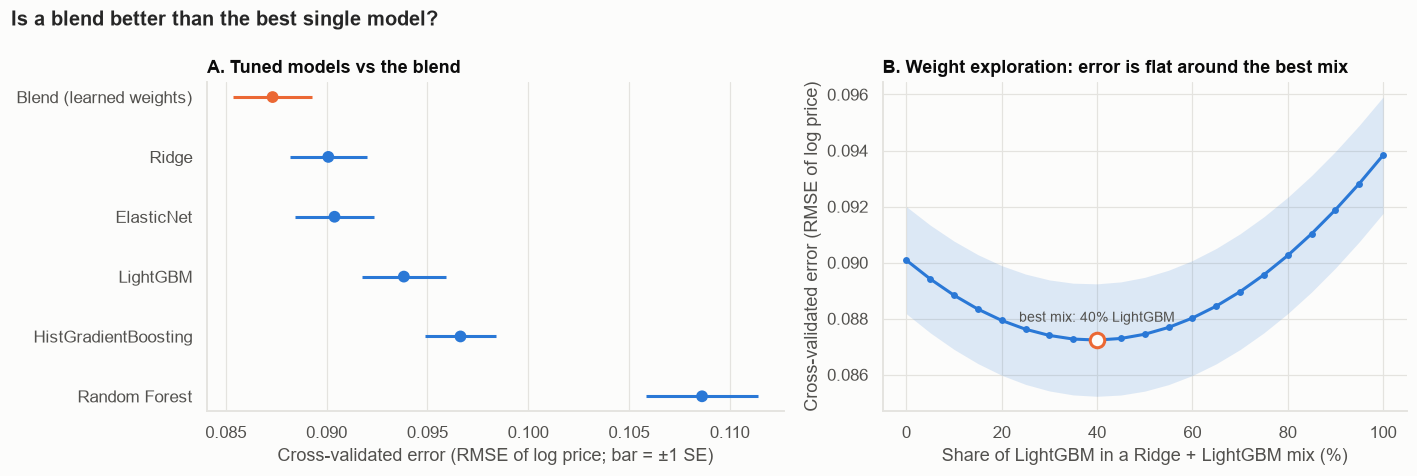

Best single model: Ridge | blend gain over it: 0.0028 RMSE(log) per fold (SE 0.0006) -> use the blend
Learned weights (all tuned models): {'Ridge': 0.607, 'ElasticNet': 0.0, 'Random Forest': 0.0, 'HistGradientBoosting': 0.096, 'LightGBM': 0.297}
Final model weights: {'Ridge': 0.607, 'HistGradientBoosting': 0.096, 'LightGBM': 0.297}


In [55]:
summary = pd.DataFrame({m: {"CV RMSE (log)": s.mean(), "SE": s.std(ddof=1) / np.sqrt(len(s))} for m, s in fold_scores.items()}).T
summary = summary.sort_values("CV RMSE (log)")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
y = np.arange(len(summary))
colors = [COLORS["orange"] if m.startswith("Blend") else COLORS["blue"] for m in summary.index]
ax.errorbar(summary["CV RMSE (log)"], y, xerr=summary["SE"], fmt="none", ecolor=colors, elinewidth=2, capsize=0)
ax.scatter(summary["CV RMSE (log)"], y, c=colors, s=45, zorder=3)
ax.set_yticks(y, labels=summary.index)
ax.invert_yaxis()
ax.set_xlabel("Cross-validated error (RMSE of log price; bar = ±1 SE)")
ax.set_title("A. Tuned models vs the blend")
ax.grid(axis="y", visible=False)
ax = axes[1]
ax.fill_between(100 * shares, mix.mean(1) - mix.std(1, ddof=1) / np.sqrt(mix.shape[1]),
                mix.mean(1) + mix.std(1, ddof=1) / np.sqrt(mix.shape[1]), color=COLORS["blue"], alpha=0.15, linewidth=0)
ax.plot(100 * shares, mix.mean(1), marker="o", ms=3.5, lw=2, color=COLORS["blue"])
best_share = shares[mix.mean(1).argmin()]
ax.scatter([100 * best_share], [mix.mean(1).min()], s=90, facecolor=COLORS["surface"], edgecolor=COLORS["orange"], linewidth=2, zorder=4)
ax.annotate(f"best mix: {100 * best_share:.0f}% {best_tree}", (100 * best_share, mix.mean(1).min()), xytext=(0, 12),
            textcoords="offset points", ha="center", fontsize=9, color=COLORS["text2"])
ax.set_xlabel(f"Share of {best_tree} in a {best_linear} + {best_tree} mix (%)")
ax.set_ylabel("Cross-validated error (RMSE of log price)")
ax.set_title("B. Weight exploration: error is flat around the best mix")
fig.suptitle("Is a blend better than the best single model?", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "03_model_selection")
plt.show()

print(f"Best single model: {best_single} | blend gain over it: {blend_gain:.4f} RMSE(log) per fold "
      f"(SE {blend_gain_se:.4f}) -> {'use the blend' if USE_BLEND else 'use the single model'}")
print("Learned weights (all tuned models):", {n: round(float(w), 3) for n, w in zip(MODEL_NAMES, learned)})
print("Final model weights:", {n: round(float(w), 3) for n, w in FINAL_WEIGHTS.items()})

**Reading.**
- **Tuning matters** (gap between best and worst setting in the table). Ridge and ElasticNet are the strongest single models; Random Forest is clearly weaker (panel A).
- **The blend passes the rule**, by several standard errors (printed above).
- **The learned weights keep three models.** ElasticNet adds nothing beyond Ridge, and Random Forest nothing beyond the boosted trees. The linear model carries most of the weight.
- **The exact weights barely matter:** the error is flat around the best mix (panel B).

<a id="s3-3"></a>

### 3.3 Final check on the test set, and over time

The tuned models are refitted on the whole training set and scored **once** on the 526 test sales. The 95% intervals come from a bootstrap that uses the **same resampled sales for every model**, so models are compared on identical data. The paired comparison then tests whether the final model really beats the best single model on test sales. The time-based check trains on 2006–2009 sales and predicts 2010, the conditions of using the model on newer sales. Fit and prediction times are printed separately, labeled as machine-dependent (Section 0 decision).

In [56]:
import time

final_models, fit_seconds = {}, {}
for name in MODEL_NAMES:
    t0 = time.perf_counter()
    final_models[name] = CANDIDATE_MODELS[name][0](best_params[name]).fit(train_df[FEATURE_COLS], y_train_log)
    fit_seconds[name] = time.perf_counter() - t0
final_models["Simple baseline"] = linear_pipe(Ridge(alpha=1.0), SIMPLE_COLS).fit(train_df[SIMPLE_COLS], y_train_log)


def final_predict_log(X):
    """Log price predicted by the final model (Section 3.2) for rows that contain the model inputs."""
    return sum(w * final_models[n].predict(X[FEATURE_COLS]) for n, w in FINAL_WEIGHTS.items())


test_log = {n: final_models[n].predict(test_df[FEATURE_COLS]) for n in MODEL_NAMES}
test_log["Simple baseline"] = final_models["Simple baseline"].predict(test_df[SIMPLE_COLS])
test_log["Naive baseline"] = np.full(len(test_df), np.median(y_train_log))
t0 = time.perf_counter()
test_log["Final model"] = final_predict_log(test_df)
final_predict_ms = 1000 * (time.perf_counter() - t0)
test_usd = {n: np.exp(v) for n, v in test_log.items()}


mape = lambda a, b: 100 * mean_absolute_percentage_error(a, b)
rows = []
for name, pred in test_usd.items():
    mae, mae_lo, mae_hi = bootstrap_ci(mean_absolute_error, p_test_usd, pred, task="3.3 test bootstrap")
    mp, mp_lo, mp_hi = bootstrap_ci(mape, p_test_usd, pred, task="3.3 test bootstrap")
    rows.append({"model": name, "MAE ($)": mae, "MAE 95% low": mae_lo, "MAE 95% high": mae_hi,
                 "MedAE ($)": np.median(np.abs(p_test_usd - pred)), "MAPE (%)": mp, "MAPE 95% low": mp_lo, "MAPE 95% high": mp_hi})
test_table = pd.DataFrame(rows).set_index("model").sort_values("MAE ($)")

# Paired test: final model vs best single model on the same test sales
err_final, err_single = np.abs(p_test_usd - test_usd["Final model"]), np.abs(p_test_usd - test_usd[best_single])
_, diff_lo, diff_hi = bootstrap_ci(lambda a, b: a.mean() - b.mean(), err_final, err_single, task="3.3 paired difference")
paired_diff = err_final.mean() - err_single.mean()

# Mean vs median price: Duan's smearing factor (team decision: report the typical price, without it)
smear_factor = np.mean(np.exp(y_train_log - final_predict_log(train_df)))

display(format_table(test_table, money=[c for c in test_table.columns if "MAE" in c or "MedAE" in c],
                     pct=[c for c in test_table.columns if "MAPE" in c]))
print(f"Paired test, final model minus {best_single}: MAE {paired_diff:+,.0f} $ (95% interval {diff_lo:+,.0f} to {diff_hi:+,.0f})")
print(f"Duan smearing factor: {smear_factor:.4f} (mean price would be {100 * (smear_factor - 1):.2f}% above the typical price)")
print("Machine-dependent timings (indicative only): fit " +
      ", ".join(f"{n} {s:.1f}s" for n, s in fit_seconds.items() if n in FINAL_WEIGHTS) +
      f" | final model prices all {len(test_df)} test homes in {final_predict_ms:.0f} ms")

,MAE ($),MAE 95% low,MAE 95% high,MedAE ($),MAPE (%),MAPE 95% low,MAPE 95% high
model,,,,,,,
Final model,"$10,767","$9,740","$11,887","$7,301",6.11%,5.45%,6.92%
LightGBM,"$11,270","$10,203","$12,514","$7,587",6.36%,5.69%,7.18%
HistGradientBoosting,"$11,465","$10,419","$12,667","$8,023",6.45%,5.80%,7.27%
Ridge,"$11,586","$10,514","$12,772","$8,197",6.56%,5.89%,7.44%
ElasticNet,"$11,638","$10,562","$12,821","$7,988",6.58%,5.91%,7.46%
Random Forest,"$13,070","$11,822","$14,442","$8,961",7.42%,6.63%,8.35%
Simple baseline,"$21,289","$19,605","$22,871","$17,450",12.19%,11.19%,13.24%
Naive baseline,"$55,052","$50,494","$59,420","$38,250",30.75%,28.24%,33.38%


Paired test, final model minus Ridge: MAE -819 $ (95% interval -1,221 to -460)
Duan smearing factor: 1.0022 (mean price would be 0.22% above the typical price)
Machine-dependent timings (indicative only): fit Ridge 0.1s, HistGradientBoosting 1.6s, LightGBM 0.8s | final model prices all 526 test homes in 94 ms


In [57]:
# Time-based check: train on 2006-2009, predict 2010 (whole analysis sample, settings and weights from 3.1-3.2)
before_2010, in_2010 = data_fe[data_fe["Yr Sold"] < 2010], data_fe[data_fe["Yr Sold"] == 2010]
time_models = {n: CANDIDATE_MODELS[n][0](best_params[n]).fit(before_2010[FEATURE_COLS], np.log(before_2010["SalePrice"]))
               for n in FINAL_WEIGHTS}
pred_2010 = np.exp(sum(w * time_models[n].predict(in_2010[FEATURE_COLS]) for n, w in FINAL_WEIGHTS.items()))
time_check = {"MAE ($)": mean_absolute_error(in_2010["SalePrice"], pred_2010),
              "MAPE (%)": mape(in_2010["SalePrice"].to_numpy(), pred_2010)}
print(f"Time-based check (train 2006-2009, n={len(before_2010):,}; predict 2010, n={len(in_2010)}): "
      f"MAE ${time_check['MAE ($)']:,.0f} | MAPE {time_check['MAPE (%)']:.2f}%")

Time-based check (train 2006-2009, n=2,319; predict 2010, n=310): MAE $12,062 | MAPE 6.99%


**Reading.**
- **The final model is the most accurate on unseen sales.** The paired comparison's interval excludes zero.
- **It roughly halves the error of the rule-of-thumb baseline.**
- **It holds up over time.** Trained on 2006–2009 and used on 2010, its error stays in the same range.
- **Typical vs average price:** the smearing factor is practically 1.

<a id="s3-4"></a>

### 3.4 Listing range and negotiation band

**What brokers get.** Around the reference price, an **80% listing range** (should contain about 8 in 10 comparable sales) and a **50% negotiation band** (about half).

**How (conformal calibration).** From the honest out-of-fold errors of the final model on the training set: the 80% range uses the error size that 80% of homes stayed within, and the 50% band the size half stayed within. Both are calibrated **separately for each predicted price tier**. The test set then checks their coverage.

In [58]:
TIER_NAMES = ["Starter", "Mid-market", "Upper"]
RANGE_LEVELS = {"80% listing range": 0.80, "50% negotiation band": 0.50}
tier_edges = np.quantile(np.exp(final_oof_log), [1 / 3, 2 / 3])


def tier_of(pred_log):
    """Predicted price tier (cut points from the training set)."""
    return np.array(TIER_NAMES)[np.searchsorted(tier_edges, np.exp(pred_log))]


calib_tier = tier_of(final_oof_log)
abs_error_log = np.abs(y_train_log - final_oof_log)
half_width = {(tier, level): np.quantile(abs_error_log[calib_tier == tier],
                                         min(1.0, share * (1 + 1 / (calib_tier == tier).sum())))
              for tier in TIER_NAMES for level, share in RANGE_LEVELS.items()}


def price_range(pred_log, level):
    """Low and high end of a calibrated range around the predicted log price."""
    hw = np.array([half_width[(t, level)] for t in tier_of(pred_log)])
    return np.exp(pred_log - hw), np.exp(pred_log + hw)


final_test_log = test_log["Final model"]
test_tier = tier_of(final_test_log)
range_rows = []
for level, share in RANGE_LEVELS.items():
    lo, hi = price_range(final_test_log, level)
    inside = (p_test_usd >= lo) & (p_test_usd <= hi)
    for tier in ["All"] + TIER_NAMES:
        m = np.ones(len(inside), bool) if tier == "All" else test_tier == tier
        range_rows.append({"range": level, "tier": tier, "test homes": int(m.sum()), "target": share,
                           "coverage": inside[m].mean(), "median width ($)": np.median((hi - lo)[m]),
                           "median half-width (%)": 100 * np.median(np.expm1(np.log(hi[m]) - final_test_log[m]))})
range_table = pd.DataFrame(range_rows).set_index(["range", "tier"])
print("Tier cut points (predicted price): " + " | ".join(f"${e:,.0f}" for e in tier_edges))
format_table(range_table, ints=["test homes"], share=["target", "coverage"], money=["median width ($)"],
             pct=["median half-width (%)"])

Tier cut points (predicted price): $141,194 | $195,130


test homes target coverage median width ($) median half-width (%)
range                tier                                                                        
80% listing range    All               526  80.0%    82.5%          $28,767                10.08%
                     Starter           175  80.0%    84.6%          $25,436                11.06%
                     Mid-market        181  80.0%    82.9%          $27,529                 8.67%
                     Upper             170  80.0%    80.0%          $47,805                10.08%
50% negotiation band All               526  50.0%    51.7%          $14,409                 5.03%
                     Starter           175  50.0%    58.3%          $12,715                 5.39%
                     Mid-market        181  50.0%    48.1%          $13,825                 4.27%
                     Upper             170  50.0%    48.8%          $24,407                 5.03%

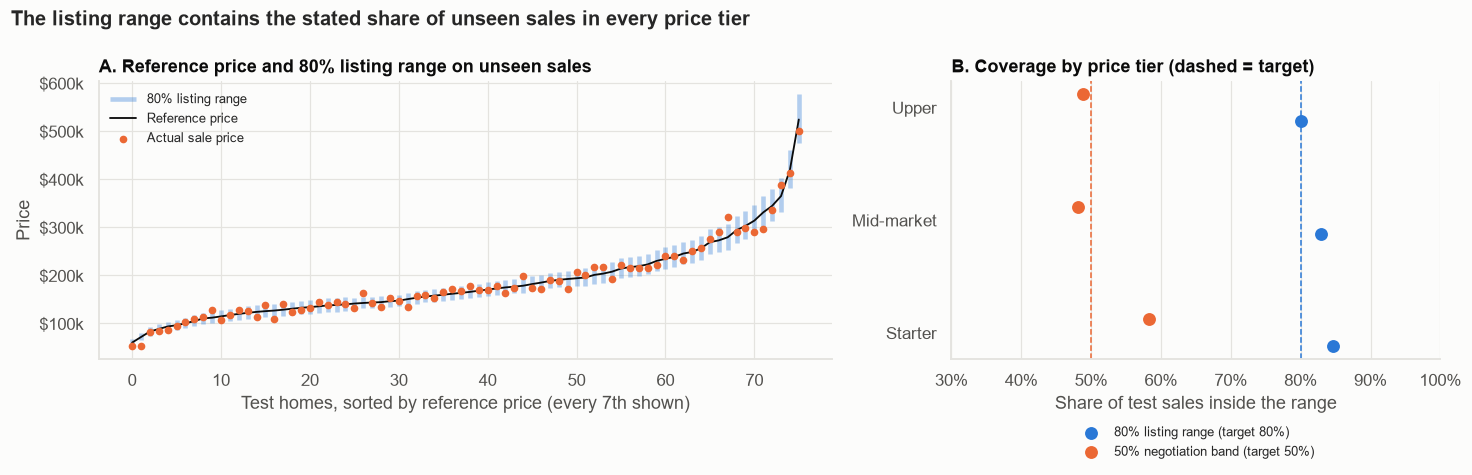

In [59]:
lo80, hi80 = price_range(final_test_log, "80% listing range")
order = np.argsort(final_test_log)
step = max(1, len(order) // 70)
shown = order[::step]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
x = np.arange(len(shown))
ax.vlines(x, lo80[shown], hi80[shown], color=COLORS["blue"], alpha=0.35, lw=3, label="80% listing range")
ax.plot(x, np.exp(final_test_log[shown]), color=COLORS["text"], lw=1.2, label="Reference price")
ax.scatter(x, p_test_usd[shown], s=16, color=COLORS["orange"], zorder=3, label="Actual sale price")
ax.yaxis.set_major_formatter(USD)
ax.set_xlabel(f"Test homes, sorted by reference price (every {step}th shown)")
ax.set_ylabel("Price")
ax.set_title("A. Reference price and 80% listing range on unseen sales")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax = axes[1]
cov = range_table.reset_index()
cov = cov[cov["tier"] != "All"]
for (level, g), color, dy in zip(cov.groupby("range", sort=False), [COLORS["blue"], COLORS["orange"]], [-0.12, 0.12]):
    yy = np.arange(len(TIER_NAMES)) + dy
    ax.scatter(100 * g["coverage"], yy, s=55, color=color, label=f"{level} (target {100 * RANGE_LEVELS[level]:.0f}%)", zorder=3)
    ax.axvline(100 * RANGE_LEVELS[level], color=color, lw=1, ls="--")
ax.set_yticks(np.arange(len(TIER_NAMES)), labels=TIER_NAMES)
ax.set_xlim(30, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Share of test sales inside the range")
ax.set_title("B. Coverage by price tier (dashed = target)")
ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1)
ax.grid(axis="y", visible=False)
fig.suptitle("The listing range contains the stated share of unseen sales in every price tier", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "03_listing_ranges")
plt.show()

**Reading.**
- **The 80% listing range meets its target** overall and in every price tier (table and panel B), slightly conservatively for starter homes.
- **The 50% negotiation band is on target** overall. It is a little wide for starter homes, where more sales than intended fall inside it.
- **Widths.** The ranges are of similar size *in percent* across tiers, so in dollars they are wider for upper-tier homes (table).

**For brokers.** The 80% range is a defensible listing range. The 50% band is where about half of comparable homes close: a natural zone for the negotiation.

<a id="s3-5"></a>

### 3.5 Valuation card for brokers

`valuation_card()` turns the model into what a broker uses: for a home's characteristics, it prints the reference price, the 50% negotiation band and the 80% listing range, rounded to the nearest $1,000. The examples below are three test homes chosen by a fixed rule, **the home whose reference price is closest to the median of its price tier**, so they represent typical homes of each segment. Their actual sale prices are shown for comparison.

In [60]:
def valuation_card(homes):
    """Reference price, 50% negotiation band and 80% listing range for homes given as rows of model inputs."""
    pred_log = final_predict_log(homes)
    lo50, hi50 = price_range(pred_log, "50% negotiation band")
    lo80, hi80 = price_range(pred_log, "80% listing range")
    r = lambda v: np.round(v, -3).astype(int)
    return pd.DataFrame({
        "Neighborhood": homes["Neighborhood"].to_numpy(),
        "Living area (sqft)": homes["Gr Liv Area"].astype(int).to_numpy(),
        "Overall quality (1-10)": homes["Overall Qual"].astype(int).to_numpy(),
        "Year built": homes["Year Built"].astype(int).to_numpy(),
        "Price tier": tier_of(pred_log),
        "80% range low": r(lo80), "50% band low": r(lo50), "Reference price": r(np.exp(pred_log)),
        "50% band high": r(hi50), "80% range high": r(hi80),
    }, index=homes.index)


test_reference = pd.Series(np.exp(final_test_log), index=test_df.index)
example_ids = [(test_reference[test_tier == t] - test_reference[test_tier == t].median()).abs().idxmin() for t in TIER_NAMES]
cards = valuation_card(test_df.loc[example_ids])
cards["Actual sale price"] = test_df.loc[example_ids, "SalePrice"].astype(int)
format_table(cards, money=["80% range low", "50% band low", "Reference price", "50% band high", "80% range high",
                           "Actual sale price"]).T

,408,2254,2479
Neighborhood,Sawyer,Somerst,Somerst
Living area (sqft),1040,1458,1958
Overall quality (1-10),5,6,7
Year built,1963,1999,2005
Price tier,Starter,Mid-market,Upper
80% range low,"$109,000","$152,000","$226,000"
50% band low,"$115,000","$159,000","$237,000"
Reference price,"$121,000","$165,000","$249,000"
50% band high,"$128,000","$172,000","$261,000"
80% range high,"$134,000","$180,000","$274,000"


<a id="s3-6"></a>

### 3.6 Key results

In [61]:
ft = test_table.loc["Final model"]
r80, r50 = range_table.loc[("80% listing range", "All")], range_table.loc[("50% negotiation band", "All")]
print("Key results - Section 3")
print(f"  Tuned models, best single by cross-validation: {best_single} {best_params[best_single]}")
print(f"  Blend vs best single (cross-validated): gain {blend_gain:.4f} RMSE(log), SE {blend_gain_se:.4f} -> "
      + ("blend used" if USE_BLEND else "single model used") + "; final weights "
      + ", ".join(f"{n} {w:.2f}" for n, w in FINAL_WEIGHTS.items()))
print(f"  Test set ({len(test_df)} sales): MAE ${ft['MAE ($)']:,.0f} (95% {ft['MAE 95% low']:,.0f}-{ft['MAE 95% high']:,.0f}), "
      f"median error ${ft['MedAE ($)']:,.0f}, MAPE {ft['MAPE (%)']:.2f}%")
print(f"  Versus {best_single} on the same test sales: MAE {paired_diff:+,.0f} $ (95% {diff_lo:+,.0f} to {diff_hi:+,.0f})")
print(f"  Baselines on the test set: simple MAPE {test_table.loc['Simple baseline', 'MAPE (%)']:.2f}%, "
      f"naive MAPE {test_table.loc['Naive baseline', 'MAPE (%)']:.2f}%")
print(f"  Time-based check (2006-2009 -> 2010): MAPE {time_check['MAPE (%)']:.2f}%")
print(f"  80% listing range: test coverage {r80['coverage']:.1%}, typical half-width ±{r80['median half-width (%)']:.1f}% "
      f"(${r80['median width ($)']:,.0f} wide) | 50% band: coverage {r50['coverage']:.1%}, ±{r50['median half-width (%)']:.1f}%")

Key results - Section 3
  Tuned models, best single by cross-validation: Ridge {'alpha': 10}
  Blend vs best single (cross-validated): gain 0.0028 RMSE(log), SE 0.0006 -> blend used; final weights Ridge 0.61, HistGradientBoosting 0.10, LightGBM 0.30
  Test set (526 sales): MAE $10,767 (95% 9,740-11,887), median error $7,301, MAPE 6.11%
  Versus Ridge on the same test sales: MAE -819 $ (95% -1,221 to -460)
  Baselines on the test set: simple MAPE 12.19%, naive MAPE 30.75%
  Time-based check (2006-2009 -> 2010): MAPE 6.99%
  80% listing range: test coverage 82.5%, typical half-width ±10.1% ($28,767 wide) | 50% band: coverage 51.7%, ±5.0%


<a id="s3-decisions"></a>

### Decisions and rationale — Section 3


| Decision | Why |
|---|---|
| Every candidate model tuned by cross-validation. | Each setting is backed by evidence (3.1). |
| Blend only if it beats the best single model by more than one standard error (rule fixed in advance). Weights learned from data. | It passes the rule, and the test set confirms the gain (3.2, 3.3). |
| Test set used once, at the end. | Keeps the accuracy estimate unbiased. |
| Reference price = the typical (median) price. | Simpler to explain. The average would differ by a fraction of a percent (3.3). |
| Listing range and negotiation band calibrated around the final model, per price tier. | Centered on the reference price, and on target in every tier (3.4). |
| Example homes chosen by a stated rule. | They stay representative when results change (3.5). |
| Boosted trees: learning rate and number of trees not tuned. | Limitation, to keep the run time reasonable. |

<a id="s4"></a>

## 4. Q2 — Price drivers

> **In brief.** *Question (Q2):* which characteristics move prices most, split by what owners can change? *Answer:* the building's size and age carry most of the information, followed by the overall quality and condition ratings. Owner-modifiable features add little that other characteristics do not already tell. Location matters, but far less than raw neighborhood prices suggest. *Numbers:* [Key results](#s4-5). *Decisions:* [end of section](#s4-decisions).

**Approach.** Assign every model variable to one group by a written rule (4.1); measure each group's importance two ways (4.2); rank individual characteristics (4.3); price location alone (4.4). These are **associations** learned from past sales, not the effect of changing a characteristic; that is Q3.

<a id="s4-1"></a>

### 4.1 Groups of characteristics

| Group | Rule |
|---|---|
| Location and lot | Where the home is and the land it stands on. They cannot be changed. |
| Structure and size | The building itself: floor areas, rooms and bathrooms, age, type, foundation, roof, masonry, garage capacity, basement height and exposure. Changing them means enlarging or rebuilding. |
| Owner-modifiable | Changeable by renovation, repair or a small addition: kitchen and exterior quality and covering, heating, central air, electrical, fireplace, basement and garage finishing, decks and porches, fence, driveway, repairs, remodel recency. |
| Overall ratings (mixed) | Overall quality and condition reflect both construction and upkeep. |
| Sale circumstances | The sale, not the home: sale type, new construction. |

Every model variable is assigned exactly once (checked in code).

In [62]:
DRIVER_GROUPS = {
    "Location and lot": ["Neighborhood", "MS Zoning", "Condition 1", "Lot Config", "Land Contour", "Lot Shape",
                         "Lot Area", "Alley"],
    "Structure and size": ["Gr Liv Area", "1st Flr SF", "2nd Flr SF", "total_sf", "Total Bsmt SF", "TotRms AbvGrd",
                           "Bedroom AbvGr", "Full Bath", "Half Bath", "Bsmt Full Bath", "total_baths", "Year Built",
                           "Bldg Type", "House Style", "MS SubClass", "Foundation", "Roof Style", "Mas Vnr Type",
                           "Mas Vnr Area", "Garage Cars", "Garage Area", "Garage Type", "Bsmt Qual", "Bsmt Exposure"],
    "Owner-modifiable": ["Kitchen Qual", "Exter Qual", "Exterior 1st", "Exterior 2nd", "Heating QC", "Central Air",
                         "Electrical", "Fireplaces", "Fireplace Qu", "BsmtFin Type 1", "BsmtFin SF 1", "Bsmt Unf SF",
                         "Bsmt Cond", "Garage Finish", "Garage Qual", "Garage Cond", "Wood Deck SF", "Open Porch SF",
                         "Enclosed Porch", "porch_sf", "Fence", "Paved Drive", "Functional", "years_since_remod"],
    "Overall ratings (mixed)": ["Overall Qual", "Overall Cond"],
    "Sale circumstances": ["Sale Type", "is_new_home"],
}
GROUP_OF = {v: g for g, vs in DRIVER_GROUPS.items() for v in vs}
assert len(GROUP_OF) == sum(len(v) for v in DRIVER_GROUPS.values()), "a variable is assigned twice"
assert set(GROUP_OF) == set(FEATURE_COLS), f"unassigned: {set(FEATURE_COLS) - set(GROUP_OF)}; extra: {set(GROUP_OF) - set(FEATURE_COLS)}"
GROUP_COLORS = dict(zip(DRIVER_GROUPS, [COLORS["blue"], COLORS["gray"], COLORS["orange"], COLORS["aqua"], "#c3c2b7"]))

taxonomy = pd.DataFrame({
    "group": [GROUP_OF[v] for v in FEATURE_COLS],
    "meaning": [VAR_DESCRIPTIONS[v] if v in VAR_DESCRIPTIONS else ENGINEERED[v]["meaning"] for v in FEATURE_COLS],
}, index=pd.Index(FEATURE_COLS, name="variable")).sort_values(["group", "variable"])
print(taxonomy["group"].value_counts().to_dict())
show_scrollable(taxonomy.assign(**{"plain name": [plain_name(v) for v in taxonomy.index]})
                [["plain name", "group", "meaning"]])

{'Owner-modifiable': 24, 'Structure and size': 24, 'Location and lot': 8, 'Overall ratings (mixed)': 2, 'Sale circumstances': 2}


,plain name,group,meaning
variable,,,
Alley,Alley access,Location and lot,Type of alley access to property; NaN = no alley access
Condition 1,Nearby road or railway,Location and lot,Proximity to various conditions (primary)
Land Contour,Land flatness,Location and lot,Flatness of the property
Lot Area,Lot size (sqft),Location and lot,Lot size in square feet (numeric).
Lot Config,"Lot position (inside, corner, cul-de-sac)",Location and lot,Lot configuration
Lot Shape,Lot shape,Location and lot,General shape of property
MS Zoning,Zoning,Location and lot,General zoning classification of the sale
Neighborhood,Neighborhood,Location and lot,Physical location within city limits.
Overall Cond,Overall condition (1-10),Overall ratings (mixed),Rates the overall condition of the house.; Integer from 1 (Very Poor) to 10 (Very Excellent).


<a id="s4-2"></a>

### 4.2 How much does each group matter?

Groups overlap (bigger houses tend to have better finishes), so we use two measures, both in RMSE of log price (≈ percentage points of typical error):
- **Information lost (test set):** shuffle all of a group's variables together and measure how much the error grows (20 repetitions). This counts everything the group tells the model, shared or not.
- **Unique contribution (cross-validation):** refit the final model without the group. This counts only what no other group can replace.

In [63]:
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.inspection import permutation_importance


class FinalModel(BaseEstimator, RegressorMixin):
    """Wraps the final model of Section 3 (already fitted) for scikit-learn's inspection tools."""

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return final_predict_log(X)


X_test_f = test_df[FEATURE_COLS]
base_test_rmse = root_mean_squared_error(y_test_log, final_predict_log(X_test_f))


def shuffled_group_loss(cols, task, n_repeats=20):
    """Increase in test RMSE(log) when the group's columns are shuffled together (same order for all of them)."""
    rng, losses = rng_for(task), []
    for _ in range(n_repeats):
        order = rng.permutation(len(X_test_f))
        shuffled = X_test_f.copy()
        for c in cols:
            shuffled[c] = X_test_f[c].to_numpy()[order]
        losses.append(root_mean_squared_error(y_test_log, final_predict_log(shuffled)) - base_test_rmse)
    return np.mean(losses), np.std(losses, ddof=1)


def oof_final_without(cols_out):
    """Out-of-fold log predictions of the final model refitted without some variables (same weights and settings)."""
    keep = [c for c in FEATURE_COLS if c not in cols_out]
    oof = np.zeros(len(train_df))
    for name, w in FINAL_WEIGHTS.items():
        reg = clone(CANDIDATE_MODELS[name][0](best_params[name]).named_steps["reg"])
        pipe = linear_pipe(reg, keep) if name in ("Ridge", "ElasticNet") else tree_pipe(reg, keep)
        oof += w * oof_log_predictions(pipe, keep)
    return oof


oof_final_all = oof_final_without([])
group_rows = []
for group, cols in DRIVER_GROUPS.items():
    loss, loss_sd = shuffled_group_loss(cols, f"4.2 shuffled group {group}")
    unique = fold_rmse(oof_final_without(cols)) - fold_rmse(oof_final_all)
    group_rows.append({"group": group, "variables": len(cols),
                       "information lost when shuffled (test)": loss, "shuffle SD": loss_sd,
                       "unique contribution (CV)": unique.mean(), "unique SE": unique.std(ddof=1) / np.sqrt(len(unique))})
group_importance = pd.DataFrame(group_rows).set_index("group")
group_importance["share of information (%)"] = (100 * group_importance["information lost when shuffled (test)"]
                                                / group_importance["information lost when shuffled (test)"].sum())
format_table(group_importance, ints=["variables"], pct=["share of information (%)"], decimals=4)

,variables,information lost when shuffled (test),shuffle SD,unique contribution (CV),unique SE,share of information (%)
group,,,,,,
Location and lot,8,0.0268,0.0018,0.0105,0.0014,7.11%
Structure and size,24,0.2514,0.0080,0.0396,0.0025,66.71%
Owner-modifiable,24,0.0454,0.0031,0.0061,0.0010,12.03%
Overall ratings (mixed),2,0.0537,0.0027,0.0132,0.0015,14.24%
Sale circumstances,2,-0.0003,0.0003,0.0002,0.0002,-0.09%


**Reading.**
- **Structure and size** carry most of the information and make the largest unique contribution.
- **Overall quality and condition** come second, with just two variables.
- **Owner-modifiable features** carry a meaningful share, but little that is unique: much of it is already reflected in overall quality and size.
- **Location** carries a smaller share, but more unique information than the owner-modifiable group (see 4.4).
- **Sale circumstances** add nothing once the home itself is described.

<a id="s4-3"></a>

### 4.3 Which individual characteristics matter most?

Each variable is shuffled on its own on the test set (10 repetitions), and we measure how much the final model's error grows. Variables that share information split the credit. Total area and living area, for example, both describe size, so each looks smaller than "size" as a whole. The group view in 4.2 corrects for that.

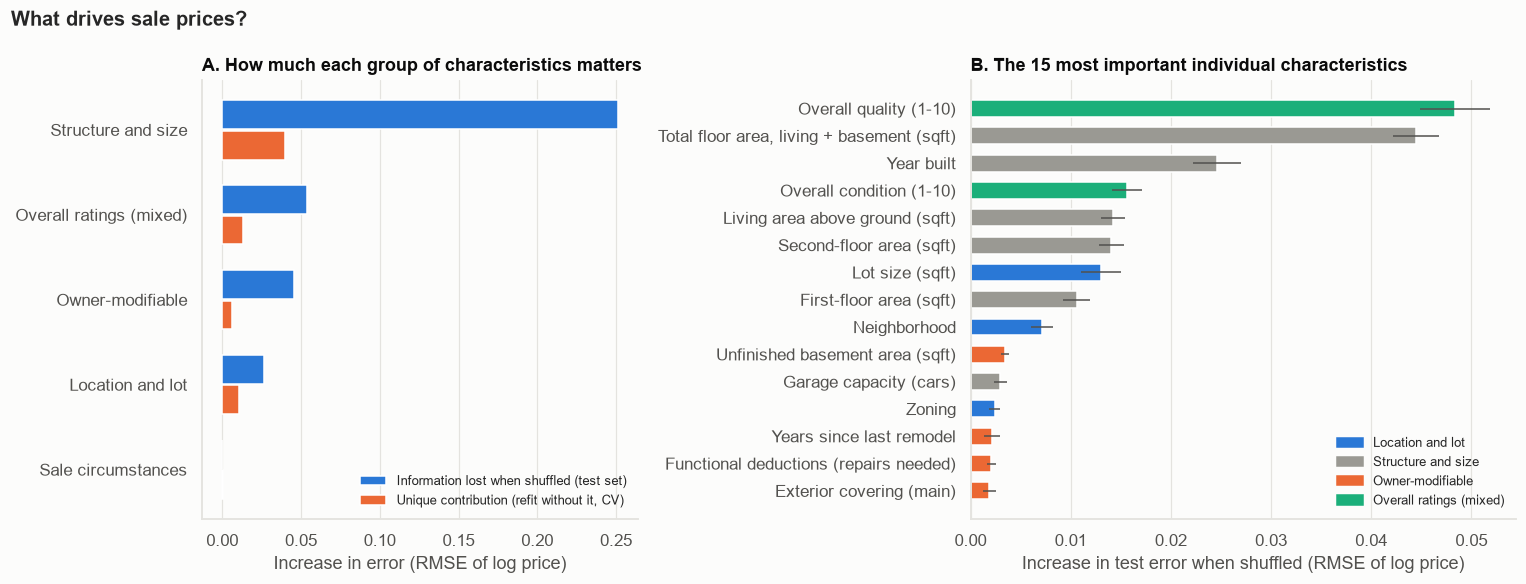

Most important owner-modifiable characteristics: Unfinished basement area (sqft), Years since last remodel, Functional deductions (repairs needed), Exterior covering (main), Number of fireplaces, Finished basement area, main (sqft)


In [64]:
TOP_N_DRIVERS = 15
perm = permutation_importance(FinalModel(), X_test_f, y_test_log, n_repeats=10, random_state=SEED,
                              scoring="neg_root_mean_squared_error")
driver_importance = pd.DataFrame({"importance": perm.importances_mean, "SD": perm.importances_std,
                                  "group": [GROUP_OF[v] for v in FEATURE_COLS]},
                                 index=pd.Index(FEATURE_COLS, name="variable")).sort_values("importance", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
gi = group_importance.sort_values("information lost when shuffled (test)")
y = np.arange(len(gi))
ax.barh(y + 0.18, gi["information lost when shuffled (test)"], height=0.34, color=COLORS["blue"],
        label="Information lost when shuffled (test set)")
ax.barh(y - 0.18, gi["unique contribution (CV)"], height=0.34, color=COLORS["orange"],
        label="Unique contribution (refit without it, CV)")
ax.set_yticks(y, labels=gi.index)
ax.set_xlabel("Increase in error (RMSE of log price)")
ax.set_title("A. How much each group of characteristics matters")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.grid(axis="y", visible=False)
ax = axes[1]
top = driver_importance.head(TOP_N_DRIVERS).iloc[::-1]
ax.barh([plain_name(v) for v in top.index], top["importance"], xerr=top["SD"], color=[GROUP_COLORS[g] for g in top["group"]],
        height=0.62, error_kw={"ecolor": COLORS["text2"], "elinewidth": 1})
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for g, c in GROUP_COLORS.items() if g in set(top["group"])]
ax.legend(handles, [g for g in GROUP_COLORS if g in set(top["group"])], frameon=False, fontsize=8.5, loc="lower right")
ax.set_xlabel("Increase in test error when shuffled (RMSE of log price)")
ax.set_title(f"B. The {TOP_N_DRIVERS} most important individual characteristics")
ax.grid(axis="y", visible=False)
fig.suptitle("What drives sale prices?", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "04_price_drivers")
plt.show()

print("Most important owner-modifiable characteristics:",
      ", ".join(plain_name(v) for v in driver_importance[driver_importance["group"] == "Owner-modifiable"].head(6).index))

**Reading.**
- **Overall quality and total floor area lead**, followed by age (`Year Built`), overall condition and the individual floor areas.
- **Location appears** through lot area and neighborhood.
- **The leading owner-modifiable variables** are unfinished basement area (which partly carries basement size), time since the last remodel, functional deductions (repairs), exterior covering and fireplaces (printed list). Each matters far less than size, quality or age.

<a id="s4-4"></a>

### 4.4 How much is location worth?

A regression of log price on the main characteristics of the house, plus one term per neighborhood, gives the **price difference for the same house in different neighborhoods**. The characteristics are living and basement area, lot size, overall quality and condition, age, bathrooms, garage capacity and new construction. The reference is NAmes, the neighborhood with the most sales. This regression has no penalty, so the neighborhood effects are not shrunk toward zero as they would be in a penalized model such as Ridge. Intervals use robust standard errors (HC1). Only neighborhoods with at least 15 sales are shown.

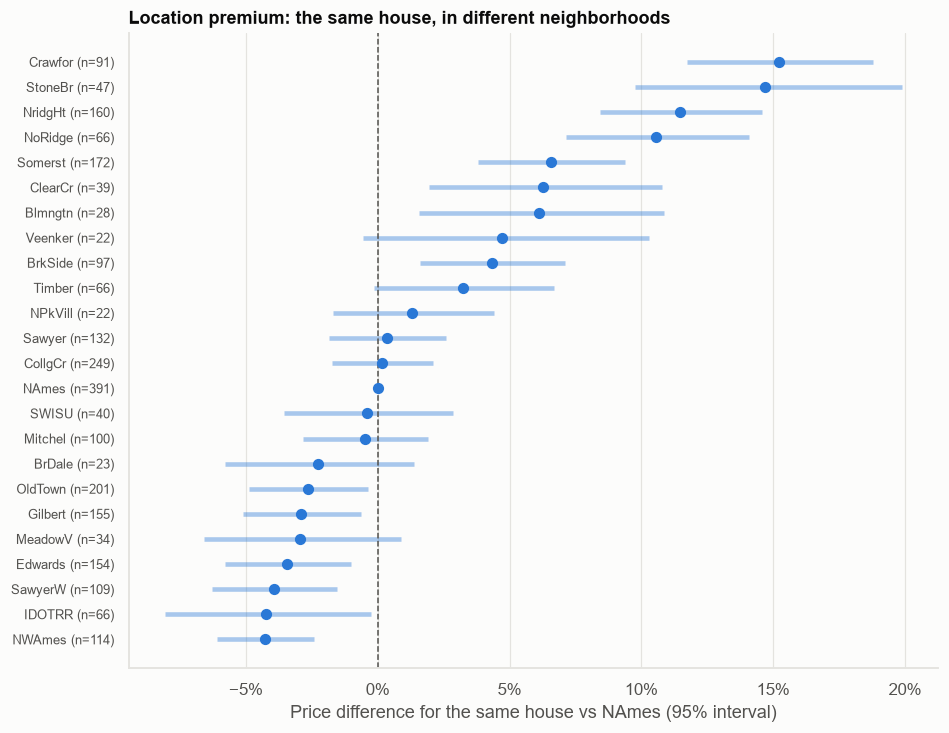

Regression R² = 0.927 on 2,599 sales
Same-house premium range: -4% to +15% vs NAmes | raw median prices of the same neighborhoods range 3.6x


In [65]:
import statsmodels.formula.api as smf

MIN_NEIGHBORHOOD_SALES = 15
REFERENCE_NEIGHBORHOOD = "NAmes"
loc_df = pd.DataFrame({
    "log_price": np.log(data_fe["SalePrice"]), "log_living": np.log(data_fe["Gr Liv Area"]),
    "bsmt_k": data_fe["Total Bsmt SF"] / 1000, "log_lot": np.log(data_fe["Lot Area"].astype(float)),
    "quality": data_fe["Overall Qual"], "condition": data_fe["Overall Cond"], "age": data_fe["house_age"],
    "baths": data_fe["total_baths"], "garage": data_fe["Garage Cars"], "new": data_fe["is_new_home"],
    "nbhd": data_fe["Neighborhood"]}).dropna()
loc_fit = smf.ols(f"log_price ~ C(nbhd, Treatment('{REFERENCE_NEIGHBORHOOD}')) + log_living + bsmt_k + log_lot + "
                  "quality + condition + age + baths + garage + new", loc_df).fit(cov_type="HC1")
terms = [t for t in loc_fit.params.index if t.startswith("C(nbhd")]
ci = loc_fit.conf_int().loc[terms]
location = pd.DataFrame({"premium (%)": 100 * np.expm1(loc_fit.params[terms]),
                         "95% low": 100 * np.expm1(ci[0]), "95% high": 100 * np.expm1(ci[1])})
location.index = [t.split("[T.")[1].rstrip("]") for t in terms]
location.loc[REFERENCE_NEIGHBORHOOD] = 0.0
sales_per_nbhd = loc_df["nbhd"].value_counts()
location["sales"] = sales_per_nbhd.reindex(location.index)
location = location[location["sales"] >= MIN_NEIGHBORHOOD_SALES].sort_values("premium (%)")
raw_median = data_fe.groupby("Neighborhood")["SalePrice"].median()

fig, ax = plt.subplots(figsize=(9.5, 7.5))
y = np.arange(len(location))
ax.hlines(y, location["95% low"], location["95% high"], color=COLORS["blue"], lw=3, alpha=0.4)
ax.scatter(location["premium (%)"], y, s=40, color=COLORS["blue"], zorder=3)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(y, labels=[f"{n} (n={int(s)})" for n, s in zip(location.index, location["sales"])], fontsize=8.5)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel(f"Price difference for the same house vs {REFERENCE_NEIGHBORHOOD} (95% interval)")
ax.set_title("Location premium: the same house, in different neighborhoods")
ax.grid(axis="y", visible=False)
save_fig(fig, "04_location_premium")
plt.show()

shown = raw_median.reindex(location.index)
print(f"Regression R² = {loc_fit.rsquared:.3f} on {len(loc_df):,} sales")
print(f"Same-house premium range: {location['premium (%)'].min():+.0f}% to {location['premium (%)'].max():+.0f}% vs "
      f"{REFERENCE_NEIGHBORHOOD} | raw median prices of the same neighborhoods range "
      f"{shown.max() / shown.min():.1f}x")

**Reading.**
- **Location matters, but much less than raw prices suggest.** Raw median prices differ several-fold between these neighborhoods, but for the same house the difference shrinks to a much narrower range (both printed above). Most of the raw gap comes from the houses themselves: the expensive neighborhoods have newer, larger, better-built homes (see also Section 6).
- **A few neighborhoods carry a clear premium**, with intervals well above zero: Crawfor, StoneBr, NridgHt, NoRidge. Several carry a small discount, such as NWAmes, IDOTRR and Edwards.

**For brokers.** A neighborhood's name alone overstates what location is worth. Compare like with like.

<a id="s4-5"></a>

### 4.5 Key results

In [66]:
print("Key results - Section 4")
for g, r in group_importance.sort_values("information lost when shuffled (test)", ascending=False).iterrows():
    print(f"  {g} ({int(r['variables'])} variables): information share {r['share of information (%)']:.0f}%, "
          f"unique contribution {r['unique contribution (CV)']:+.4f} (SE {r['unique SE']:.4f})")
print("  Top 5 characteristics:", ", ".join(plain_name(v) for v in driver_importance.head(5).index))
print("  Top owner-modifiable:", ", ".join(plain_name(v) for v in driver_importance[driver_importance["group"] == "Owner-modifiable"].head(5).index))
print(f"  Location premium for the same house: {location['premium (%)'].min():+.0f}% to {location['premium (%)'].max():+.0f}% "
      f"vs {REFERENCE_NEIGHBORHOOD} ({len(location)} neighborhoods with >= {MIN_NEIGHBORHOOD_SALES} sales)")

Key results - Section 4
  Structure and size (24 variables): information share 67%, unique contribution +0.0396 (SE 0.0025)
  Overall ratings (mixed) (2 variables): information share 14%, unique contribution +0.0132 (SE 0.0015)
  Owner-modifiable (24 variables): information share 12%, unique contribution +0.0061 (SE 0.0010)
  Location and lot (8 variables): information share 7%, unique contribution +0.0105 (SE 0.0014)
  Sale circumstances (2 variables): information share -0%, unique contribution +0.0002 (SE 0.0002)
  Top 5 characteristics: Overall quality (1-10), Total floor area, living + basement (sqft), Year built, Overall condition (1-10), Living area above ground (sqft)
  Top owner-modifiable: Unfinished basement area (sqft), Years since last remodel, Functional deductions (repairs needed), Exterior covering (main), Number of fireplaces
  Location premium for the same house: -4% to +15% vs NAmes (24 neighborhoods with >= 15 sales)


<a id="s4-decisions"></a>

### Decisions and rationale — Section 4


| Decision | Why |
|---|---|
| Five groups of characteristics, defined by a written rule. Basement height counts as structure. | A defensible split. The dictionary defines `Bsmt Qual` as height (4.1). |
| Group importance measured two ways: information shared vs unique contribution. | Groups overlap, so one number would mislead (4.2). |
| Individual importance shown with its limitation. | Correlated variables split the credit (4.3). |
| Location premium from a regression with house controls and no penalty. | Ridge would shrink neighborhood effects toward zero (4.4). |
| Results stated as associations. | Importance does not show what a renovation would do. That is Q3. |

<a id="s5"></a>

## 5. Q3 — Improvement return on investment

> **In brief.** *Question (Q3):* which improvements are a profitable investment? *Answer:* none of the improvements with a published 2008 cost pays for itself at resale; past sales value them well below their cost. For the others (central air, heating, fireplace, driveway, garage finish, fence), the break-even cost is the most an owner should spend. *Numbers:* [Key results](#s5-1). *Decisions:* [end of section](#s5-decisions).

**Approach.**
- **What-if.** Each eligible Normal resale is priced twice by the final model: as it is, and with one improvement. The difference is the **price uplift**.
- **Main result: break-even cost.** An improvement pays for itself only if it costs less than its uplift. No cost data is needed.
- **Uncertainty:** 30 refits of the model on resampled training data.
- **Cost comparison:** against **published 2008 costs**: *Remodeling* magazine's Cost vs. Value Report 2008–09, West North Central region (which includes Iowa), for the four improvements it covers, adjusted to our scenarios' scope as noted in the table. Its Realtor estimates of value added are shown as a cross-check. No dated source was found for the other six, so they show break-even only. 2008 is mid-period and prices were flat (2.4), so no inflation adjustment is needed.

**Scope.** Normal resales only, because new homes include builder finishes. Bathroom additions without extra floor area are excluded as unrealistic. Uplifts are associations, not experiments.

In [67]:
# Published renovation costs: Remodeling magazine, "Cost vs. Value Report 2008-09", West North Central region
# (the region that includes Iowa): https://www.jlconline.com/cost-vs-value/2008/west-north-central/
# Job cost = labor, materials, subcontractors, contractor overhead and profit (HomeTech Information Systems).
# Resale value = Realtors' estimate of what the project adds at sale (survey of July-August 2008).
# 2008 is mid-period for these 2006-2010 sales and like-for-like prices were flat (2.4): no inflation adjustment.
CVV = "Cost vs. Value 2008-09, West North Central"
COST_BENCHMARKS = {   # improvement: (cost low, cost high, Realtors' resale estimate, source and scope); None = no published cost
    "Install central air": None,
    "Kitchen: typical -> good": (
        21_185, 21_185, 15_528,
        f"{CVV}: minor kitchen remodel, midrange (200 sqft: new cabinet fronts, counters, appliances, sink, flooring, paint)"),
    "Kitchen: typical -> good, plus overall quality +1 (upper bound)": (
        21_185, 21_185, 15_528,
        f"{CVV}: minor kitchen remodel, midrange; a floor for this scenario, which implies more work"),
    "Exterior material: typical -> good": (
        10_027, 13_256, 7_449,
        f"{CVV}: siding replacement, 1,250 sqft, vinyl ($10,027; resale $7,449) to fiber-cement ($13,256)"),
    "Heating: typical -> excellent": None,
    "Add a fireplace": None,
    "Finish 500 sqft of basement": (
        50_363, 50_363, 32_859,
        f"{CVV}: basement remodel, 600 sqft including a bathroom and wet bar ($60,436; resale $39,431), "
        "pro-rated to 500 sqft; an upper reference"),
    "Add a 200 sqft wood deck": (
        6_486, 10_378, 4_939,
        f"{CVV}: wood deck addition, 320 sqft ($10,378; resale $7,902); low end and resale pro-rated to 200 sqft"),
    "Finish the garage interior": None,
    "Pave the driveway": None,
    "Add a privacy fence": None,
}
SCENARIOS = {   # name: (which homes are eligible, how the improvement changes them)
    "Install central air": (lambda d: d["Central Air"] == "N", lambda d: d.assign(**{"Central Air": "Y"})),
    "Kitchen: typical -> good": (lambda d: d["Kitchen Qual"] == "TA", lambda d: d.assign(**{"Kitchen Qual": "Gd"})),
    "Kitchen: typical -> good, plus overall quality +1 (upper bound)": (
        lambda d: (d["Kitchen Qual"] == "TA") & d["Overall Qual"].between(4, 7),
        lambda d: d.assign(**{"Kitchen Qual": "Gd", "Overall Qual": d["Overall Qual"] + 1, "years_since_remod": 0})),
    "Exterior material: typical -> good": (lambda d: d["Exter Qual"] == "TA", lambda d: d.assign(**{"Exter Qual": "Gd"})),
    "Heating: typical -> excellent": (lambda d: d["Heating QC"] == "TA", lambda d: d.assign(**{"Heating QC": "Ex"})),
    "Add a fireplace": (lambda d: d["Fireplaces"] == 0, lambda d: d.assign(**{"Fireplaces": 1, "Fireplace Qu": "Gd"})),
    "Finish 500 sqft of basement": (
        lambda d: (d["BsmtFin Type 1"] == "Unf") & (d["Bsmt Unf SF"] >= 500),
        lambda d: d.assign(**{"BsmtFin Type 1": "GLQ", "BsmtFin SF 1": d["BsmtFin SF 1"] + 500,
                              "Bsmt Unf SF": d["Bsmt Unf SF"] - 500})),
    "Add a 200 sqft wood deck": (lambda d: d["Wood Deck SF"] == 0,
                                 lambda d: d.assign(**{"Wood Deck SF": 200, "porch_sf": d["porch_sf"] + 200})),
    "Finish the garage interior": (lambda d: d["Garage Finish"] == "Unf", lambda d: d.assign(**{"Garage Finish": "Fin"})),
    "Pave the driveway": (lambda d: d["Paved Drive"] == "N", lambda d: d.assign(**{"Paved Drive": "Y"})),
    "Add a privacy fence": (lambda d: d["Fence"] == "Absent", lambda d: d.assign(**{"Fence": "GdPrv"})),
}
assert set(SCENARIOS) == set(COST_BENCHMARKS)
changed = set()
for elig, mod in SCENARIOS.values():
    eligible_homes = data_fe[elig(data_fe)]
    improved = mod(eligible_homes.copy())
    changed |= {c for c in improved.columns if not improved[c].equals(eligible_homes[c])}
print("Variables changed by the scenarios:", sorted(changed))
print("  of which not used by the model (their change has no effect):", sorted(changed - set(FEATURE_COLS)) or "none")
variables_table({c: "Changed by an improvement scenario" for c in sorted(changed)})

Variables changed by the scenarios: ['Bsmt Unf SF', 'BsmtFin SF 1', 'BsmtFin Type 1', 'Central Air', 'Exter Qual', 'Fence', 'Fireplace Qu', 'Fireplaces', 'Garage Finish', 'Heating QC', 'Kitchen Qual', 'Overall Qual', 'Paved Drive', 'Wood Deck SF', 'porch_sf', 'years_since_remod']
  of which not used by the model (their change has no effect): none


,Plain name,Source,Meaning,Codes / formula,Role in this section
Variable,,,,,
Bsmt Unf SF,Unfinished basement area (sqft),Data dictionary,Unfinished square feet of basement area (numeric).; dictionary note: NaN = no basement,numeric,Changed by an improvement scenario
BsmtFin SF 1,"Finished basement area, main (sqft)",Data dictionary,Type 1 finished square feet (numeric).; dictionary note: NaN = no basement,numeric,Changed by an improvement scenario
BsmtFin Type 1,Basement finish quality (main area),Data dictionary,Rating of basement finished area (primary); NaN = no basement,ALQ = Average Living Quarters; BLQ = Below Average Living Quarters; GLQ = Good Living Quarters; LwQ = Low Quality; Rec = Average Rec Room; Unf = Unfinished,Changed by an improvement scenario
Central Air,Central air conditioning,Data dictionary,Central air conditioning,N = No; Y = Yes,Changed by an improvement scenario
Exter Qual,Exterior material quality,Data dictionary,Quality of the material on the exterior,Ex = Excellent; Fa = Fair; Gd = Good; TA = Average / Typical,Changed by an improvement scenario
Fence,Fence type,Data dictionary,Fence quality; NaN = no fence,GdPrv = Good Privacy; GdWo = Good Wood; MnPrv = Minimum Privacy; MnWw = Minimum Wood/Wire,Changed by an improvement scenario
Fireplace Qu,Fireplace quality,Data dictionary,Fireplace quality; NaN = no fireplace,Ex = Excellent; Fa = Fair; Gd = Good; Po = Poor; TA = Average / Typical,Changed by an improvement scenario
Fireplaces,Number of fireplaces,Data dictionary,Number of fireplaces (integer).,numeric,Changed by an improvement scenario
Garage Finish,Garage interior finish,Data dictionary,Interior finish of the garage; NaN = no garage,Fin = Finished; RFn = Rough Finished; Unf = Unfinished,Changed by an improvement scenario


In [68]:
N_REFITS = 30
normal_sales = data_fe[data_fe["Sale Condition"] == "Normal"]
before_after = {name: (normal_sales[elig(normal_sales)], mod(normal_sales[elig(normal_sales)].copy()))
                for name, (elig, mod) in SCENARIOS.items()}


def uplift_usd(predict_log, before, after):
    """Predicted price change per home (USD) when only the improvement changes."""
    return np.exp(predict_log(after)) - np.exp(predict_log(before))


# Point estimate with the final model, and a Ridge-only check (model agreement)
point = {n: uplift_usd(final_predict_log, b, a) for n, (b, a) in before_after.items()}
ridge_check = {n: np.median(uplift_usd(lambda X: final_models["Ridge"].predict(X[FEATURE_COLS]), b, a))
               for n, (b, a) in before_after.items()}

# Uncertainty: refit the final model on resampled training data
rng = rng_for("5 refits")
refit_medians = {n: [] for n in SCENARIOS}
for _ in range(N_REFITS):
    rows = rng.choice(len(train_df), len(train_df), replace=True)
    Xb, yb = train_df.iloc[rows][FEATURE_COLS], y_train_log[rows]
    models_b = {n: CANDIDATE_MODELS[n][0](best_params[n]).fit(Xb, yb) for n in FINAL_WEIGHTS}
    predict_b = lambda X: sum(w * models_b[n].predict(X[FEATURE_COLS]) for n, w in FINAL_WEIGHTS.items())
    for n, (b, a) in before_after.items():
        refit_medians[n].append(np.median(uplift_usd(predict_b, b, a)))

roi_rows = []
for n, (b, a) in before_after.items():
    up = point[n]
    lo, hi = np.percentile(refit_medians[n], [2.5, 97.5])
    bench = COST_BENCHMARKS[n]
    if bench is None:
        c_lo = c_hi = resale = np.nan
        verdict = "no published cost: worth it only below the break-even"
    else:
        c_lo, c_hi, resale, _ = bench
        verdict = ("pays for itself" if lo >= c_hi else "does not pay back at resale" if hi < c_lo
                   else "depends on the actual cost")
    roi_rows.append({"improvement": n, "eligible homes": len(b),
                     "uplift = break-even cost ($)": np.median(up), "range low ($)": lo, "range high ($)": hi,
                     "uplift (% of price)": 100 * np.median(up / np.exp(final_predict_log(b))),
                     "Ridge-only check ($)": ridge_check[n],
                     "published cost low ($)": c_lo, "published cost high ($)": c_hi,
                     "Realtors' resale estimate, 2008 ($)": resale,
                     "uplift as % of published cost": 100 * np.median(up) / ((c_lo + c_hi) / 2),
                     "verdict": verdict})
roi = pd.DataFrame(roi_rows).set_index("improvement").sort_values("uplift = break-even cost ($)", ascending=False)

# Does the uplift differ by price tier (Section 3.4)? Median uplift in % of the home's price
tier_rows = []
for n, (b, a) in before_after.items():
    pct = 100 * point[n] / np.exp(final_predict_log(b))
    tiers = tier_of(final_predict_log(b))
    tier_rows.append({"improvement": n, **{t: np.median(pct[tiers == t]) if (tiers == t).sum() >= 20 else np.nan
                                           for t in TIER_NAMES}})
uplift_by_tier = pd.DataFrame(tier_rows).set_index("improvement").loc[roi.index]
with pd.option_context("display.max_colwidth", None):
    display(format_table(roi, ints=["eligible homes"],
                         money=["uplift = break-even cost ($)", "range low ($)", "range high ($)", "Ridge-only check ($)",
                                "published cost low ($)", "published cost high ($)", "Realtors' resale estimate, 2008 ($)"],
                         pct=["uplift (% of price)", "uplift as % of published cost"]))
    sources = pd.Series({n: b[3] for n, b in COST_BENCHMARKS.items() if b is not None}, name="cost source and scope")
    display(sources.to_frame())
print("Median uplift in % of the home's price, by predicted price tier (blank: fewer than 20 eligible homes):")
format_table(uplift_by_tier, pct_signed=TIER_NAMES)

,eligible homes,uplift = break-even cost ($),range low ($),range high ($),uplift (% of price),Ridge-only check ($),published cost low ($),published cost high ($),"Realtors' resale estimate, 2008 ($)",uplift as % of published cost,verdict
improvement,,,,,,,,,,,
"Kitchen: typical -> good, plus overall quality +1 (upper bound)","1,245","$13,025","$11,577","$14,757",9.69%,"$12,850","$21,185","$21,185","$15,528",61.48%,does not pay back at resale
Finish 500 sqft of basement,595,"$7,360","$6,309","$9,397",4.71%,"$7,467","$50,363","$50,363","$32,859",14.61%,does not pay back at resale
Install central air,152,"$5,120","$3,086","$7,540",5.48%,"$4,839",,,,,no published cost: worth it only below the break-even
Add a fireplace,"1,152","$3,616","$2,402","$4,353",2.61%,"$3,921",,,,,no published cost: worth it only below the break-even
Exterior material: typical -> good,"1,548","$3,076","$1,633","$4,129",2.31%,"$3,150","$10,027","$13,256","$7,449",26.43%,does not pay back at resale
Kitchen: typical -> good,"1,283","$2,319","$1,329","$3,271",1.87%,"$2,400","$21,185","$21,185","$15,528",10.95%,does not pay back at resale
Heating: typical -> excellent,721,"$2,182","$1,524","$3,407",1.56%,"$2,528",,,,,no published cost: worth it only below the break-even
Pave the driveway,178,"$1,962",$975,"$3,653",1.80%,"$2,756",,,,,no published cost: worth it only below the break-even
Add a 200 sqft wood deck,"1,245","$1,523",$722,"$2,300",1.09%,$986,"$6,486","$10,378","$4,939",18.06%,does not pay back at resale


,cost source and scope
Kitchen: typical -> good,"Cost vs. Value 2008-09, West North Central: minor kitchen remodel, midrange (200 sqft: new cabinet fronts, counters, appliances, sink, flooring, paint)"
"Kitchen: typical -> good, plus overall quality +1 (upper bound)","Cost vs. Value 2008-09, West North Central: minor kitchen remodel, midrange; a floor for this scenario, which implies more work"
Exterior material: typical -> good,"Cost vs. Value 2008-09, West North Central: siding replacement, 1,250 sqft, vinyl ($10,027; resale $7,449) to fiber-cement ($13,256)"
Finish 500 sqft of basement,"Cost vs. Value 2008-09, West North Central: basement remodel, 600 sqft including a bathroom and wet bar ($60,436; resale $39,431), pro-rated to 500 sqft; an upper reference"
Add a 200 sqft wood deck,"Cost vs. Value 2008-09, West North Central: wood deck addition, 320 sqft ($10,378; resale $7,902); low end and resale pro-rated to 200 sqft"


Median uplift in % of the home's price, by predicted price tier (blank: fewer than 20 eligible homes):


,Starter,Mid-market,Upper
improvement,,,
"Kitchen: typical -> good, plus overall quality +1 (upper bound)",+9.7%,+9.3%,+10.9%
Finish 500 sqft of basement,+5.4%,+4.5%,+4.3%
Install central air,+5.5%,,
Add a fireplace,+2.6%,+2.7%,+2.4%
Exterior material: typical -> good,+2.4%,+2.2%,+2.6%
Kitchen: typical -> good,+1.9%,+1.7%,+2.7%
Heating: typical -> excellent,+1.7%,+1.4%,+1.3%
Pave the driveway,+1.8%,,
Add a 200 sqft wood deck,+1.4%,+0.9%,+0.6%


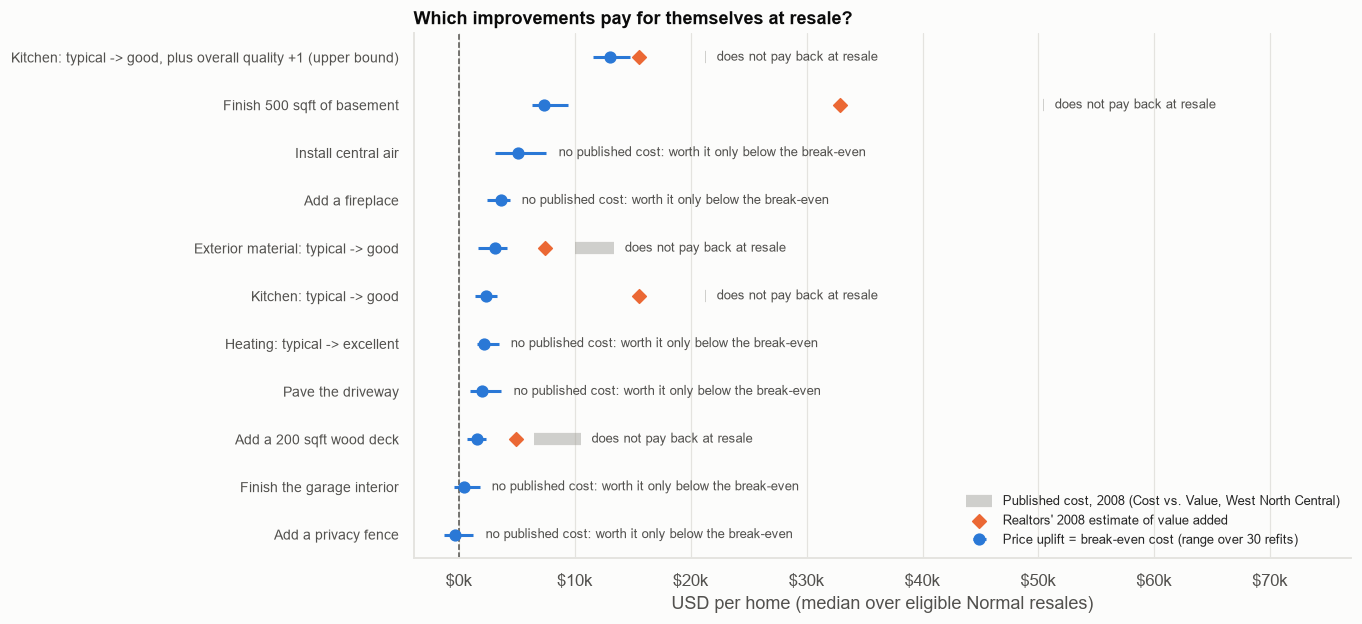

In [69]:
plot_r = roi.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6.2))
y = np.arange(len(plot_r))
has_cost = plot_r["published cost low ($)"].notna().to_numpy()
ax.hlines(y[has_cost], plot_r["published cost low ($)"][has_cost], plot_r["published cost high ($)"][has_cost] + 150,
          color=COLORS["gray"], lw=8, alpha=0.45, label="Published cost, 2008 (Cost vs. Value, West North Central)")
ax.scatter(plot_r["Realtors' resale estimate, 2008 ($)"][has_cost], y[has_cost], marker="D", s=40, color=COLORS["orange"],
           zorder=3, label="Realtors' 2008 estimate of value added")
ax.errorbar(plot_r["uplift = break-even cost ($)"], y,
            xerr=[plot_r["uplift = break-even cost ($)"] - plot_r["range low ($)"],
                  plot_r["range high ($)"] - plot_r["uplift = break-even cost ($)"]],
            fmt="o", ms=7, color=COLORS["blue"], elinewidth=2, capsize=0, label="Price uplift = break-even cost (range over 30 refits)")
for yi, (_, r) in zip(y, plot_r.iterrows()):
    right_end = np.nanmax([r["range high ($)"], r["published cost high ($)"]])
    ax.annotate(r["verdict"], (right_end, yi), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=COLORS["text2"])
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(y, labels=plot_r.index, fontsize=9)
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(right=ax.get_xlim()[1] * 1.45)
ax.set_xlabel("USD per home (median over eligible Normal resales)")
ax.set_title("Which improvements pay for themselves at resale?")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "05_improvement_break_even")
plt.show()

**Reading.**
- **None of the four improvements with a published cost pays for itself at resale.** Past sales value a kitchen upgrade, new siding, a deck and a finished basement at a fraction of their 2008 cost (table, figure). Even the kitchen upper bound, which assumes the overall quality rating rises a full point, stays below the cost of a minor kitchen remodel.
- **Past sales value these improvements below what Realtors estimated in 2008** (orange diamonds): opinion-based payback figures were optimistic.
- **For the other six, the break-even cost is the answer**, e.g. installing central air where it is missing is worth doing only if it costs less than its break-even (table). Missing central air and gravel driveways occur almost only in starter homes (tier table).
- **A fence shows no detectable uplift.**
- **Robust:** the Ridge-only check agrees for the larger improvements, and uplifts are a similar share of the price across tiers.

**For brokers.** Do not promise owners that a renovation will pay for itself. Quote each improvement's break-even cost, and check the 2008 regional costs against local quotes before advising.

<a id="s5-1"></a>

### 5.1 Key results

In [70]:
print("Key results - Section 5 (uplift = break-even cost; costs from Cost vs. Value 2008-09 where published)")
for n, r in roi.iterrows():
    print(f"  {n}: ${r['uplift = break-even cost ($)']:,.0f} (range ${r['range low ($)']:,.0f} to "
          f"${r['range high ($)']:,.0f}; {r['uplift (% of price)']:.1f}% of price) -> {r['verdict']}")

Key results - Section 5 (uplift = break-even cost; costs from Cost vs. Value 2008-09 where published)
  Kitchen: typical -> good, plus overall quality +1 (upper bound): $13,025 (range $11,577 to $14,757; 9.7% of price) -> does not pay back at resale
  Finish 500 sqft of basement: $7,360 (range $6,309 to $9,397; 4.7% of price) -> does not pay back at resale
  Install central air: $5,120 (range $3,086 to $7,540; 5.5% of price) -> no published cost: worth it only below the break-even
  Add a fireplace: $3,616 (range $2,402 to $4,353; 2.6% of price) -> no published cost: worth it only below the break-even
  Exterior material: typical -> good: $3,076 (range $1,633 to $4,129; 2.3% of price) -> does not pay back at resale
  Kitchen: typical -> good: $2,319 (range $1,329 to $3,271; 1.9% of price) -> does not pay back at resale
  Heating: typical -> excellent: $2,182 (range $1,524 to $3,407; 1.6% of price) -> no published cost: worth it only below the break-even
  Pave the driveway: $1,962 (ran

<a id="s5-decisions"></a>

### Decisions and rationale — Section 5


| Decision | Why |
|---|---|
| Main result: the break-even cost (the price uplift). | Needs no cost data, and stays valid whatever the costs turn out to be. |
| Published 2008 regional costs (Cost vs. Value 2008–09, West North Central) for the 4 improvements it covers, scope-adjusted; break-even only for the rest. | Cited figures from the study period (team approval). No dated source exists for the other six. |
| Uncertainty from 30 model refits. A verdict needs the whole range to clear or miss the cost range. | A verdict should not rest on a single fit. |
| Kitchen plus overall quality +1 shown as an upper bound. | Its key assumption cannot be checked with the data. |
| Bathroom additions without extra floor area removed. | Not a realistic change. |
| Normal resales only, with a Ridge-only check and a breakdown by price tier. | New homes include builder finishes. The checks show the conclusions are robust. |

<a id="s6"></a>

## 6. Q4 — Market segmentation

> **In brief.** *Question (Q4):* are there market segments that behave differently? *Answer:* yes. The market splits into two halves, older and smaller vs newer and larger homes, located in largely different neighborhoods. Quality is worth more in the newer half, and one price model serves both. *Numbers:* [Key results](#s6-5). *Decisions:* [end of section](#s6-decisions).

**Approach.** Group homes by **physical characteristics only** (size, lot, age, quality, condition, bathrooms, garage). Price, location and new-home status are used afterwards to describe the groups; using them as inputs would build the answer into the groups. Then: the number of segments, by a rule fixed in advance (6.1); profiles (6.2); do the segments behave differently? (6.3); does one price model serve both? (6.4). All 2,629 sales are used, and prices never enter the clustering.

In [71]:
define_variable(
    "market_segment", "Market segment of a home, from k-means clustering of its physical characteristics",
    "k-means on the standardized clustering inputs below (living and lot area on a log scale); "
    "number of segments chosen by the rule in 6.1",
    "Section 6: answers Q4. The segments are then compared on price, price drivers and model accuracy.")

SEGMENT_FEATURES = ["Gr Liv Area", "Total Bsmt SF", "Lot Area", "house_age", "Overall Qual", "Overall Cond",
                    "total_baths", "Garage Cars"]
LOG_SEGMENT_FEATURES = ["Gr Liv Area", "Lot Area"]   # skewed sizes; basement area stays on its natural scale (6.1)
variables_table({c: "Clustering input" for c in SEGMENT_FEATURES}
                | {"SalePrice": "Compares the segments afterwards (not a clustering input)",
                   "Neighborhood": "Describes the segments afterwards (not a clustering input)",
                   "is_new_home": "Describes the segments afterwards (not a clustering input)",
                   "market_segment": None})

,Plain name,Source,Meaning,Codes / formula,Role in this section
Variable,,,,,
Gr Liv Area,Living area above ground (sqft),Data dictionary,Above-grade (ground) living area square feet (numeric).,numeric,Clustering input
Total Bsmt SF,Basement area (sqft),Data dictionary,Total square feet of basement area (numeric).; dictionary note: NaN = no basement,numeric,Clustering input
Lot Area,Lot size (sqft),Data dictionary,Lot size in square feet (numeric).,numeric,Clustering input
house_age,House age at sale (years),Computed,Age of the house when it was sold (years),Yr Sold - Year Built,Clustering input
Overall Qual,Overall quality (1-10),Data dictionary,Rates the overall material and finish of the house.; Integer from 1 (Very Poor) to 10 (Very Excellent).,numeric,Clustering input
Overall Cond,Overall condition (1-10),Data dictionary,Rates the overall condition of the house.; Integer from 1 (Very Poor) to 10 (Very Excellent).,numeric,Clustering input
total_baths,Total bathrooms,Computed,"All bathrooms, half baths counted as one half",Full Bath + 0.5 Half Bath + Bsmt Full Bath + 0.5 Bsmt Half Bath,Clustering input
Garage Cars,Garage capacity (cars),Data dictionary,Size of garage in car capacity (integer).; dictionary note: NaN = no garage,numeric,Clustering input
SalePrice,Sale price ($),Data dictionary,Sale price of the property in US dollars (numeric).,numeric,Compares the segments afterwards (not a clustering input)


<a id="s6-1"></a>

### 6.1 How many segments?

**Method.** K-means (which groups homes so that each is closer to its own group's average than to the others') on standardized characteristics (all put on the same scale), with living and lot area on a log scale so that a few very large homes do not dominate. Basement area stays on its natural scale: on a log scale, homes without a basement formed an artificial group.

**Rule for k (from 2 to 6), fixed in advance.** Among segmentations that are **stable** (mean adjusted Rand index ≥ 0.80 over 20 resamples; 1 = identical) and **useful** (smallest segment ≥ 5% of sales), take the most **distinct**: the highest silhouette, where above about 0.5 is clearly distinct and 0.25–0.5 is real but overlapping.

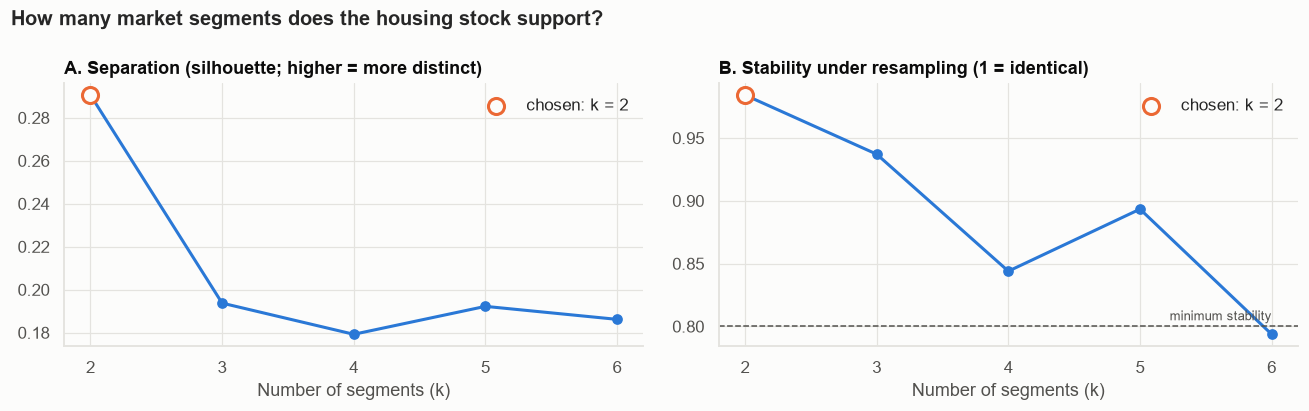

Chosen number of segments: 2


,silhouette,stability (mean ARI),stability (lowest ARI),smallest segment (share of sales)
k,,,,
2,0.291,0.984,0.962,49.7%
3,0.194,0.937,0.845,18.7%
4,0.179,0.844,0.581,18.8%
5,0.192,0.893,0.556,8.6%
6,0.186,0.794,0.597,7.9%


In [72]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

K_RANGE = range(2, 7)
N_STABILITY_RESAMPLES = 20
MIN_STABILITY, MIN_SEGMENT_SHARE = 0.80, 0.05

seg_inputs = data_fe[SEGMENT_FEATURES].copy()
seg_inputs = seg_inputs.fillna(seg_inputs.median())
for c in LOG_SEGMENT_FEATURES:
    seg_inputs[c] = np.log1p(seg_inputs[c])
Z_seg = StandardScaler().fit_transform(seg_inputs)

k_rows, labels_by_k = [], {}
for k in K_RANGE:
    labels = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Z_seg)
    labels_by_k[k] = labels
    rng = rng_for(f"6.1 stability k={k}")
    agreement = []
    for _ in range(N_STABILITY_RESAMPLES):
        rows = rng.choice(len(Z_seg), len(Z_seg), replace=True)
        refit = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_seg[rows])
        agreement.append(adjusted_rand_score(labels, refit.predict(Z_seg)))
    k_rows.append({"k": k, "silhouette": silhouette_score(Z_seg, labels),
                   "stability (mean ARI)": np.mean(agreement), "stability (lowest ARI)": np.min(agreement),
                   "smallest segment (share of sales)": np.bincount(labels).min() / len(labels)})
k_table = pd.DataFrame(k_rows).set_index("k")
eligible = k_table[(k_table["stability (mean ARI)"] >= MIN_STABILITY)
                   & (k_table["smallest segment (share of sales)"] >= MIN_SEGMENT_SHARE)]
K_SEGMENTS = int(eligible["silhouette"].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, threshold, title in [
        (axes[0], "silhouette", None, "A. Separation (silhouette; higher = more distinct)"),
        (axes[1], "stability (mean ARI)", MIN_STABILITY, "B. Stability under resampling (1 = identical)")]:
    ax.plot(k_table.index, k_table[col], marker="o", lw=2, color=COLORS["blue"])
    ax.scatter([K_SEGMENTS], [k_table.loc[K_SEGMENTS, col]], s=110, facecolor=COLORS["surface"],
               edgecolor=COLORS["orange"], linewidth=2, zorder=4, label=f"chosen: k = {K_SEGMENTS}")
    if threshold is not None:
        ax.axhline(threshold, color=COLORS["text2"], lw=1, ls="--")
        ax.annotate("minimum stability", (K_RANGE[-1], threshold), xytext=(0, 4), textcoords="offset points",
                    ha="right", fontsize=8.5, color=COLORS["text2"])
    ax.set_xticks(list(K_RANGE))
    ax.set_xlabel("Number of segments (k)")
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper right")
fig.suptitle("How many market segments does the housing stock support?", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "06_segment_count")
plt.show()
print(f"Chosen number of segments: {K_SEGMENTS}")
format_table(k_table, share=["smallest segment (share of sales)"], decimals=3)

**Reading.** The rule picks **two segments**. This split is almost perfectly stable under resampling and the most separated of all. The separation is moderate (silhouette between 0.25 and 0.5): homes form a continuum from older, smaller, plainer houses to newer, larger, higher-quality ones, and the two segments are its two halves rather than sharply distinct groups. Three segments are also stable but clearly less separated (table).

<a id="s6-2"></a>

### 6.2 Who is in each segment?

The segments are named from their profile, ordered by median price. The name is assigned in code only if the profile supports it: the cheaper segment must also be older *and* smaller. Otherwise neutral names (Segment 1, 2, ...) are used.

In [73]:
raw_labels = labels_by_k[K_SEGMENTS]
by_label = pd.DataFrame({"label": raw_labels, "price": data_fe["SalePrice"].to_numpy(),
                         "year": data_fe["Year Built"].to_numpy(), "area": data_fe["Gr Liv Area"].to_numpy()})
med = by_label.groupby("label").median().sort_values("price")
names = [f"Segment {i + 1}" for i in range(K_SEGMENTS)]
if K_SEGMENTS == 2 and med["year"].is_monotonic_increasing and med["area"].is_monotonic_increasing:
    names = ["Older, smaller homes", "Newer, larger homes"]
SEGMENT_NAMES = dict(zip(med.index, names))
SEGMENTS = names
data_fe["market_segment"] = pd.Series(raw_labels, index=data_fe.index).map(SEGMENT_NAMES)

g = data_fe.groupby("market_segment")
profile = pd.DataFrame({
    "sales": g.size(),
    "share of sales (%)": 100 * g.size() / len(data_fe),
    "median price ($)": g["SalePrice"].median(),
    "median price per sqft ($)": g.apply(lambda d: (d["SalePrice"] / d["Gr Liv Area"]).median(), include_groups=False),
    "median living area (sqft)": g["Gr Liv Area"].median(),
    "median basement area (sqft)": g["Total Bsmt SF"].median(),
    "median lot area (sqft)": g["Lot Area"].median(),
    "median year built": g["Year Built"].median(),
    "mean overall quality (1-10)": g["Overall Qual"].mean(),
    "mean overall condition (1-10)": g["Overall Cond"].mean(),
    "mean bathrooms": g["total_baths"].mean(),
    "median garage (cars)": g["Garage Cars"].median(),
    "new homes (%)": 100 * g["is_new_home"].mean(),
}).loc[SEGMENTS].T
display(format_table(profile.T, money=["median price ($)", "median price per sqft ($)"], pct=["share of sales (%)", "new homes (%)"],
                     ints=["sales", "median living area (sqft)", "median basement area (sqft)", "median lot area (sqft)",
                           "median garage (cars)"], years=["median year built"], decimals=1).T)

TOP_NEIGHBORHOODS = 6
mix = pd.crosstab(data_fe["Neighborhood"], data_fe["market_segment"])[SEGMENTS]
top = {s: (mix[s].sort_values(ascending=False).head(TOP_NEIGHBORHOODS) / mix[s].sum() * 100).round(0)
       for s in SEGMENTS}
print("Largest neighborhoods in each segment (% of the segment's sales):")
for s in SEGMENTS:
    print(f"  {s}: " + ", ".join(f"{n} {v:.0f}%" for n, v in top[s].items()))
mostly = (mix.div(mix.sum(axis=1), axis=0) >= 0.9) & (mix.sum(axis=1).to_numpy()[:, None] >= 20)
print("Neighborhoods (20+ sales) with at least 90% of their sales in one segment: "
      + "; ".join(f"{s}: {', '.join(mostly.index[mostly[s]])}" for s in SEGMENTS if mostly[s].any()))

market_segment,"Older, smaller homes","Newer, larger homes"
sales,"1,307","1,322"
share of sales (%),49.71%,50.29%
median price ($),"$132,500","$214,000"
median price per sqft ($),$112,$129
median living area (sqft),"1,145","1,674"
median basement area (sqft),864,"1,274"
median lot area (sqft),"8,546","10,381"
median year built,1956,2001
mean overall quality (1-10),5.2,7.1
mean overall condition (1-10),6.0,5.2


Largest neighborhoods in each segment (% of the segment's sales):
  Older, smaller homes: NAmes 25%, OldTown 15%, Edwards 10%, Sawyer 9%, BrkSide 7%, IDOTRR 5%
  Newer, larger homes: CollgCr 14%, Somerst 13%, NridgHt 12%, Gilbert 11%, NWAmes 7%, SawyerW 6%
Neighborhoods (20+ sales) with at least 90% of their sales in one segment: Older, smaller homes: BrDale, BrkSide, IDOTRR, MeadowV, OldTown, SWISU; Newer, larger homes: Blmngtn, Gilbert, NoRidge, NridgHt, Somerst, StoneBr, Timber, Veenker


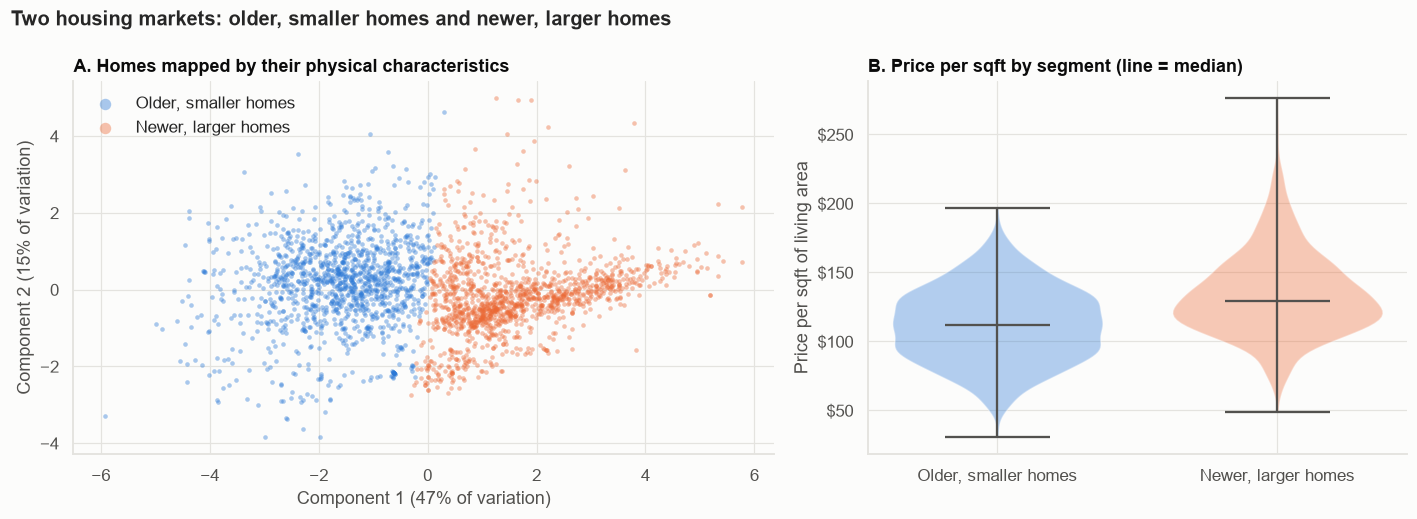

In [74]:
pca = PCA(n_components=2, random_state=SEED)
pcs = pca.fit_transform(Z_seg)
seg_colors = dict(zip(SEGMENTS, [COLORS["blue"], COLORS["orange"], COLORS["aqua"]] + [COLORS["gray"]] * 5))
ppsf_all = data_fe["SalePrice"] / data_fe["Gr Liv Area"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for s in SEGMENTS:
    m = (data_fe["market_segment"] == s).to_numpy()
    ax.scatter(pcs[m, 0], pcs[m, 1], s=9, alpha=0.4, color=seg_colors[s], linewidths=0, label=s)
ax.set_xlabel(f"Component 1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
ax.set_ylabel(f"Component 2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
ax.set_title("A. Homes mapped by their physical characteristics")
ax.legend(frameon=False, markerscale=2.5, loc="best")
ax = axes[1]
parts = ax.violinplot([ppsf_all[data_fe["market_segment"] == s] for s in SEGMENTS], showmedians=True, widths=0.75)
for body, s in zip(parts["bodies"], SEGMENTS):
    body.set_facecolor(seg_colors[s])
    body.set_alpha(0.35)
for key in ["cmedians", "cmins", "cmaxes", "cbars"]:
    parts[key].set_color(COLORS["text2"])
ax.set_xticks(range(1, len(SEGMENTS) + 1), labels=SEGMENTS)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.set_ylabel("Price per sqft of living area")
ax.set_title("B. Price per sqft by segment (line = median)")
fig.suptitle("Two housing markets: older, smaller homes and newer, larger homes" if K_SEGMENTS == 2
             else "Market segments by physical characteristics", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "06_segment_profile")
plt.show()

**Reading.**
- **Two halves of similar size.** *Older, smaller homes*: mid-century, plainer finishes but better rated condition, smaller lots and garages. *Newer, larger homes*: recent, higher quality, more bathrooms and garage space.
- **Newer homes cost more per square foot,** not only in total (panel B).
- **Location follows the housing stock:** most neighborhoods sell almost only one type of home (printed list).
- **New construction is not a segment of its own;** it falls within the newer half.

<a id="s6-3"></a>

### 6.3 Do the segments behave differently?

**Question.** Do the same characteristics move prices by the same amount in both segments?

**Method.** In each segment, a regression of log price on the main drivers, with a price level for each neighborhood. The coefficients are converted into the change a broker would quote: +10% living area, +1 point of quality or condition, +10 years of age, +1 bathroom, +1 garage space, with robust intervals. A joint F-test (a test of whether the differences are larger than chance would explain) checks whether the effects differ between segments overall. These are associations; the effect of making a change is Q3.

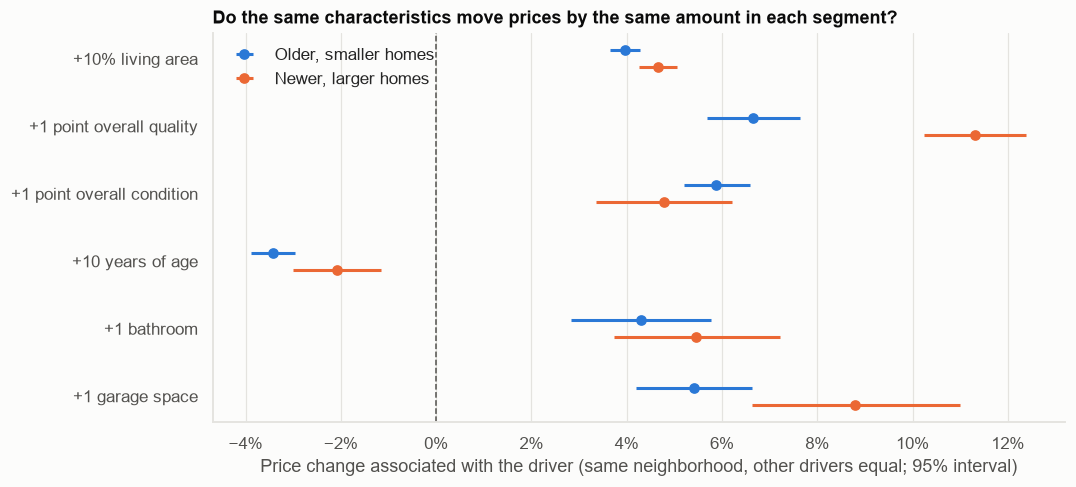

Joint test that all driver effects are equal across segments: F = 19.7 on 6 restrictions, p = 1.2e-22


segment,"Older, smaller homes","Newer, larger homes"
driver,,
+10% living area,4.0,4.7
+1 point overall quality,6.6,11.3
+1 point overall condition,5.9,4.8
+10 years of age,-3.4,-2.1
+1 bathroom,4.3,5.5
+1 garage space,5.4,8.8


In [75]:
import statsmodels.formula.api as smf

DRIVERS = {   # coefficient name: (label, function turning the log-price coefficient into a % price change)
    "log_living": ("+10% living area", lambda b: 100 * (1.1 ** b - 1)),
    "quality": ("+1 point overall quality", lambda b: 100 * np.expm1(b)),
    "condition": ("+1 point overall condition", lambda b: 100 * np.expm1(b)),
    "age": ("+10 years of age", lambda b: 100 * np.expm1(10 * b)),
    "baths": ("+1 bathroom", lambda b: 100 * np.expm1(b)),
    "garage": ("+1 garage space", lambda b: 100 * np.expm1(b)),
}
reg_df = pd.DataFrame({
    "log_price": np.log(data_fe["SalePrice"]), "log_living": np.log(data_fe["Gr Liv Area"]),
    "quality": data_fe["Overall Qual"], "condition": data_fe["Overall Cond"], "age": data_fe["house_age"],
    "baths": data_fe["total_baths"], "garage": data_fe["Garage Cars"], "nbhd": data_fe["Neighborhood"],
    "seg": data_fe["market_segment"].map({s: f"S{i}" for i, s in enumerate(SEGMENTS)}),
}).dropna()
reg_df["seg_nbhd"] = reg_df["seg"] + "_" + reg_df["nbhd"]   # neighborhood levels within each segment (only existing pairs)
rhs = " + ".join(DRIVERS)

effect_rows = []
for i, s in enumerate(SEGMENTS):
    fit = smf.ols(f"log_price ~ {rhs} + C(nbhd)", reg_df[reg_df["seg"] == f"S{i}"]).fit(cov_type="HC1")
    ci = fit.conf_int()
    for var, (label, to_pct) in DRIVERS.items():
        effect_rows.append({"segment": s, "driver": label, "effect (%)": to_pct(fit.params[var]),
                            "95% low": to_pct(ci.loc[var, 0]), "95% high": to_pct(ci.loc[var, 1])})
effects = pd.DataFrame(effect_rows)

shared = smf.ols(f"log_price ~ C(seg_nbhd) + {rhs}", reg_df).fit()                    # same driver effects
separate = smf.ols("log_price ~ C(seg_nbhd) + " + " + ".join(f"C(seg):{v}" for v in DRIVERS), reg_df).fit()
f_stat, f_p, f_df = separate.compare_f_test(shared)

fig, ax = plt.subplots(figsize=(10, 4.6))
labels = [v[0] for v in DRIVERS.values()]
for j, s in enumerate(SEGMENTS):
    e = effects[effects["segment"] == s].set_index("driver").loc[labels]
    y = np.arange(len(labels)) + (j - (len(SEGMENTS) - 1) / 2) * 0.25
    ax.errorbar(e["effect (%)"], y, xerr=[e["effect (%)"] - e["95% low"], e["95% high"] - e["effect (%)"]],
                fmt="o", ms=6, color=seg_colors[s], elinewidth=2, capsize=0, label=s)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(np.arange(len(labels)), labels=labels)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Price change associated with the driver (same neighborhood, other drivers equal; 95% interval)")
ax.set_title("Do the same characteristics move prices by the same amount in each segment?")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", visible=False)
save_fig(fig, "06_segment_drivers")
plt.show()

print(f"Joint test that all driver effects are equal across segments: F = {f_stat:.1f} on {int(f_df)} restrictions, "
      f"p = {f_p:.1e}")
effects.pivot(index="driver", columns="segment", values="effect (%)").loc[labels, SEGMENTS].round(1)

**Reading.**
- **Yes, the segments behave differently.** The joint test printed above clearly rejects that the drivers have the same effects in both segments.
- **Quality is worth much more in newer homes.** One more point of overall quality goes with a markedly larger price difference in the newer segment, and the two intervals do not overlap. Garage space points the same way, with wider uncertainty.
- **Age weighs somewhat more on older homes.**
- **Size, condition and bathrooms have similar effects in both segments** (overlapping intervals).

**For brokers.** In newer homes, finish quality separates prices most strongly. In older homes, age carries more weight. Whether *improving* a characteristic pays off is a different question, answered in Q3.

<a id="s6-4"></a>

### 6.4 Does one price model serve both segments?

If the segments behave differently, a single price model might serve one of them worse, and separate models might do better. Two checks:
1. **Accuracy of the Section 3 model by segment:** honest out-of-fold errors on the training set, plus errors and listing-range coverage on the test set.
2. **One model per segment vs one global model:** a Ridge model with the tuned setting from 3.1, cross-validated on the training set, either fitted once on all homes or fitted separately inside each segment.

In [76]:
seg_train = data_fe.loc[train_df.index, "market_segment"].to_numpy()
seg_test = data_fe.loc[test_df.index, "market_segment"].to_numpy()
lo80_t, hi80_t = price_range(final_test_log, "80% listing range")
in80 = (p_test_usd >= lo80_t) & (p_test_usd <= hi80_t)

acc_rows = []
for s in SEGMENTS:
    mt, ms = seg_train == s, seg_test == s
    acc_rows.append({"segment": s,
                     "train sales": int(mt.sum()),
                     "CV MAPE, final model (%)": mape(p_train_usd[mt], np.exp(final_oof_log[mt])),
                     "CV median bias (%)": 100 * np.median(np.exp(final_oof_log[mt]) / p_train_usd[mt] - 1),
                     "test sales": int(ms.sum()),
                     "test MAPE, final model (%)": mape(p_test_usd[ms], np.exp(final_test_log[ms])),
                     "test 80% range coverage": in80[ms].mean()})
accuracy_by_segment = pd.DataFrame(acc_rows).set_index("segment")

# One Ridge per segment vs one global Ridge (same folds, same tuned penalty)
ridge_setting = best_params["Ridge"]
oof_per_segment = np.zeros(len(train_df))
for tr, va in kf.split(train_df):
    for s in SEGMENTS:
        tr_s, va_s = tr[seg_train[tr] == s], va[seg_train[va] == s]
        model = linear_pipe(Ridge(**ridge_setting)).fit(train_df.iloc[tr_s][FEATURE_COLS], y_train_log[tr_s])
        oof_per_segment[va_s] = model.predict(train_df.iloc[va_s][FEATURE_COLS])
cmp_rows = []
for s in ["All"] + SEGMENTS:
    m = np.ones(len(train_df), bool) if s == "All" else seg_train == s
    cmp_rows.append({"segment": s,
                     "one global Ridge: CV MAPE (%)": mape(p_train_usd[m], np.exp(oof_logs["Ridge"][m])),
                     "one Ridge per segment: CV MAPE (%)": mape(p_train_usd[m], np.exp(oof_per_segment[m]))})
global_vs_segment = pd.DataFrame(cmp_rows).set_index("segment")
gain_per_segment = fold_rmse(oof_logs["Ridge"]) - fold_rmse(oof_per_segment)   # positive = per-segment better
print(f"Per-segment models vs global model, CV RMSE(log) gain per fold: {gain_per_segment.mean():+.4f} "
      f"(SE {gain_per_segment.std(ddof=1) / np.sqrt(len(gain_per_segment)):.4f}; positive = per-segment better)")
display(format_table(accuracy_by_segment, ints=["train sales", "test sales"],
                     pct=["CV MAPE, final model (%)", "test MAPE, final model (%)"],
                     pct_signed=["CV median bias (%)"], share=["test 80% range coverage"]))
format_table(global_vs_segment, pct=list(global_vs_segment.columns))

Per-segment models vs global model, CV RMSE(log) gain per fold: -0.0009 (SE 0.0004; positive = per-segment better)


,train sales,"CV MAPE, final model (%)",CV median bias (%),test sales,"test MAPE, final model (%)",test 80% range coverage
segment,,,,,,
"Older, smaller homes","1,039",6.96%,-0.1%,268,6.30%,82.1%
"Newer, larger homes","1,064",5.75%,+0.2%,258,5.92%,82.9%


,one global Ridge: CV MAPE (%),one Ridge per segment: CV MAPE (%)
segment,,
All,6.63%,6.68%
"Older, smaller homes",7.22%,7.34%
"Newer, larger homes",6.05%,6.04%


**Reading.**
- **The Section 3 model serves both segments.** Accuracy is similar, there is no systematic bias in either segment (median bias near zero), and the listing range keeps its coverage in both (table). Older, smaller homes are a little harder to price.
- **Separate models per segment do not help.** One Ridge per segment is slightly *less* accurate than one global model (the gain printed above is negative). The global model already captures the segment differences through the characteristics themselves, and splitting the data halves what each model can learn from.

**Decision.** Keep one price model. The segments are an insight for brokers, not a reason to split the model.

<a id="s6-5"></a>

### 6.5 Key results

In [77]:
print("Key results - Section 6")
print(f"  Segments: {K_SEGMENTS} (rule: stable, smallest segment >= {MIN_SEGMENT_SHARE:.0%}, best silhouette); "
      f"silhouette {k_table.loc[K_SEGMENTS, 'silhouette']:.2f}, stability {k_table.loc[K_SEGMENTS, 'stability (mean ARI)']:.2f}")
for s in SEGMENTS:
    p = profile[s]
    print(f"  {s}: {p['share of sales (%)']:.0f}% of sales, median ${p['median price ($)']:,.0f} "
          f"(${p['median price per sqft ($)']:,.0f}/sqft), built {p['median year built']:.0f}, "
          f"quality {p['mean overall quality (1-10)']:.1f}, new homes {p['new homes (%)']:.0f}%")
print(f"  Driver effects differ between segments: joint F-test p = {f_p:.1e}")
for label in [v[0] for v in DRIVERS.values()]:
    e = effects[effects["driver"] == label].set_index("segment")["effect (%)"]
    print(f"    {label}: " + " | ".join(f"{s} {e[s]:+.1f}%" for s in SEGMENTS))
print("  Final model by segment (test MAPE): " + " | ".join(
    f"{s} {accuracy_by_segment.loc[s, 'test MAPE, final model (%)']:.2f}%" for s in SEGMENTS))
print(f"  One Ridge per segment vs one global Ridge: CV RMSE(log) gain {gain_per_segment.mean():+.4f} "
      f"(SE {gain_per_segment.std(ddof=1) / np.sqrt(len(gain_per_segment)):.4f})")

Key results - Section 6
  Segments: 2 (rule: stable, smallest segment >= 5%, best silhouette); silhouette 0.29, stability 0.98
  Older, smaller homes: 50% of sales, median $132,500 ($112/sqft), built 1956, quality 5.2, new homes 1%
  Newer, larger homes: 50% of sales, median $214,000 ($129/sqft), built 2001, quality 7.1, new homes 17%
  Driver effects differ between segments: joint F-test p = 1.2e-22
    +10% living area: Older, smaller homes +4.0% | Newer, larger homes +4.7%
    +1 point overall quality: Older, smaller homes +6.6% | Newer, larger homes +11.3%
    +1 point overall condition: Older, smaller homes +5.9% | Newer, larger homes +4.8%
    +10 years of age: Older, smaller homes -3.4% | Newer, larger homes -2.1%
    +1 bathroom: Older, smaller homes +4.3% | Newer, larger homes +5.5%
    +1 garage space: Older, smaller homes +5.4% | Newer, larger homes +8.8%
  Final model by segment (test MAPE): Older, smaller homes 6.30% | Newer, larger homes 5.92%
  One Ridge per segment vs o

<a id="s6-decisions"></a>

### Decisions and rationale — Section 6


| Decision | Why |
|---|---|
| Segments built from physical characteristics only. | Otherwise the answer would be built into the segments. |
| Number of segments by a rule fixed in advance: stable, at least 5% of sales each, most distinct. | Two stable segments. Their moderate separation is reported as such (6.1). |
| Basement area kept on its natural scale. | On a log scale, homes without a basement formed an artificial segment. |
| Behavior tested directly: driver effects per segment, a joint test, model accuracy by segment. | Dollar comparisons would mostly reflect price levels (6.3, 6.4). |
| One global price model. | Per-segment models are not more accurate (6.4). |
| Segment names assigned in code, only when the profile supports them. | A name cannot contradict the data. |

<a id="s7"></a>

## 7. Conclusions, limitations and next steps

> **In brief.** *Purpose:* the answers in plain language, the limitations and the next steps. The summary is printed from the results of Sections 3–6.

The summary below is printed from the results of Sections 3–6, so it always matches the current run. The answers in plain language follow.

In [78]:
ft = test_table.loc["Final model"]
r80 = range_table.loc[("80% listing range", "All")]
print("Q1 - listing price range")
print(f"  Reference price error on unseen sales: median ${ft['MedAE ($)']:,.0f}, average ${ft['MAE ($)']:,.0f} "
      f"({ft['MAPE (%)']:.1f}% of price); 80% listing range ±{r80['median half-width (%)']:.0f}%, "
      f"contains {r80['coverage']:.0%} of unseen sales")
print("Q2 - price drivers (share of information the model uses)")
print("  " + " | ".join(f"{g} {r['share of information (%)']:.0f}%" for g, r in
                        group_importance.sort_values("share of information (%)", ascending=False).iterrows()))
print(f"  Same house, different neighborhood: {location['premium (%)'].min():+.0f}% to {location['premium (%)'].max():+.0f}%")
print("Q3 - improvements (break-even cost)")
for n, r in roi.iterrows():
    print(f"  {n}: ${r['uplift = break-even cost ($)']:,.0f} -> {r['verdict']}")
print("Q4 - segments")
for s in SEGMENTS:
    p = profile[s]
    print(f"  {s}: {p['share of sales (%)']:.0f}% of sales, median ${p['median price ($)']:,.0f}, built {p['median year built']:.0f}")
q = effects.set_index(["driver", "segment"])["effect (%)"]
print("  +1 point overall quality: " + " | ".join(f"{s} {q[('+1 point overall quality', s)]:+.1f}%" for s in SEGMENTS))

Q1 - listing price range
  Reference price error on unseen sales: median $7,301, average $10,767 (6.1% of price); 80% listing range ±10%, contains 83% of unseen sales
Q2 - price drivers (share of information the model uses)
  Structure and size 67% | Overall ratings (mixed) 14% | Owner-modifiable 12% | Location and lot 7% | Sale circumstances -0%
  Same house, different neighborhood: -4% to +15%
Q3 - improvements (break-even cost)
  Kitchen: typical -> good, plus overall quality +1 (upper bound): $13,025 -> does not pay back at resale
  Finish 500 sqft of basement: $7,360 -> does not pay back at resale
  Install central air: $5,120 -> no published cost: worth it only below the break-even
  Add a fireplace: $3,616 -> no published cost: worth it only below the break-even
  Exterior material: typical -> good: $3,076 -> does not pay back at resale
  Kitchen: typical -> good: $2,319 -> does not pay back at resale
  Heating: typical -> excellent: $2,182 -> no published cost: worth it only be

<a id="s7-answers"></a>

### Answers to the client's questions

**Q1. Listing range.** Every home gets a reference price, an 80% listing range and a 50% negotiation band. On unseen sales they held their stated share in every price tier, and the model held up on newer sales (Section 3). `valuation_card()` produces them.

**Q2. Drivers.** The building's size and age carry most of the information, then overall quality and condition. Owner-modifiable features largely overlap with these. Location matters, but far less than raw neighborhood prices suggest (Section 4).

**Q3. Improvements.** None of the improvements with a published 2008 cost (kitchen, siding, deck, basement) pays for itself at resale: past sales value them well below their cost, and below Realtors' estimates. For the others, use the break-even cost as the most worth spending (Section 5).

**Q4. Segments.** Two halves, older and smaller vs newer and larger homes, in largely different neighborhoods. Quality is worth more in the newer half, and one price model serves both (Section 6).

<a id="s7-limitations"></a>

### Limitations
- **Data origin:** described as Cedar Falls, but the records match the public Ames, Iowa housing dataset; the conclusions describe these records.
- **Period:** 2006–2010 prices; the model must be recalibrated on recent sales before use.
- **Scope:** open-market sales up to 4,000 sqft; not for foreclosures, family sales or very large homes.
- **Associations:** Q2 and Q3 describe what past prices reward; interior condition and other unrecorded details are missing.
- **Costs:** published 2008 regional averages for four improvements (Cost vs. Value 2008–09), adjusted to our scenarios' scope; no published cost for the other six. Local quotes should replace them; the break-even figures do not depend on costs.
- **Segments** overlap: they are halves of a continuum.
- **Records:** remodel years before 1950 are often recorded as 1950; quality ratings are subjective.
- **Modeling:** the boosted trees' learning rate and number of trees were not tuned; cross-validated scores are slightly optimistic (the test set is unbiased).

<a id="s7-next"></a>

### Next steps
1. Recalibrate the model on Clearview's recent transactions, and track its accuracy on new sales over time.
2. Offer `valuation_card()` to brokers as an internal tool, showing the reference price, the listing range and the negotiation band.
3. Collect contractor quotes, and the sale prices of homes before and after renovation, to measure the return on improvements directly.
4. Record listing prices and time on market, to study how listing within or outside the range affects the sale.